# Bank Account Fraud – EDA và Mô hình hóa

**Môn học:** CO5177 – Phân tích và Trực quan hóa Dữ liệu · **HK261 (2026–2027)** · **GVHD:** TS. Lê Thành Sách · **Nhóm G6**

**SVTH:** Lê Đình Đức – 2310774 · Nguyễn Văn Công Thành – 2313133

---

## Giới thiệu


**Bối cảnh nghiệp vụ và dữ liệu**

***Link Dataset*** [Kaggle – BAF Dataset Suite](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022)

- Bối cảnh bài toán: Phát hiện các đơn đăng ký mở tài khoản ngân hàng trực tuyến gian lận (kẻ gian mạo danh người khác hoặc tạo danh tính giả để rút cạn hạn mức tín dụng đi kèm hoặc nhận tiền bất hợp pháp). Nếu mô hình dự đoán dương tính (gian lận), khách hàng sẽ bị từ chối dịch vụ ngân hàng cơ bản (hành động mang tính trừng phạt); ngược lại, bỏ sót gian lận sẽ gây thiệt hại tài chính trực tiếp cho ngân hàng.

- Quy mô và cấu trúc: Bộ dữ liệu gồm bản gốc Base và 5 biến thể mở rộng (Variant I–V được tiêm thêm các thiên lệch nhân tạo). Nhóm chọn Base.csv vì đây là tập phản ánh sát nhất phân phối thực tế của môi trường ngân hàng. Mỗi tập dữ liệu trong bộ BAF gồm 1 triệu bản ghi (hồ sơ đăng ký) với 32 đặc trưng (bao gồm thông tin trực tiếp từ người đăng ký như tình trạng việc làm, thông tin phái sinh như tính hợp lệ của số điện thoại, và các biến tổng hợp như tần suất đăng ký theo mã bưu chính). Dữ liệu được sinh bằng CTGAN từ dữ liệu ngân hàng thật đã ẩn danh để đảm bảo tính riêng tư nhưng vẫn giữ nguyên phân phối thực tế.

- Tính động và mất cân bằng lớp: Dữ liệu trải dài trong 8 tháng (từ tháng 2 đến tháng 9). Tỷ lệ gian lận rất thấp, dao động từ 0,85% đến 1,5% tùy tháng (có xu hướng tăng vào các tháng sau), trong khi tỷ trọng số lượng hồ sơ mỗi tháng biến động từ 9,5% đến 15%.

- Thách thức Công bằng (Fairness): Dữ liệu chứa các thuộc tính nhạy cảm gồm độ tuổi (customer_age), thu nhập và việc làm. Trong đó, các mô hình chuẩn trên bản Base thường thiên vị rõ rệt: người lớn tuổi (≥50) có nguy cơ bị từ chối oan cao gấp 3 lần người trẻ (FPR ratio ≈ 0,3) [1]


Bộ dữ liệu **Bank Account Fraud (BAF)** – `Base.csv`: 1.000.000 hồ sơ mở tài khoản, 32 cột, nhãn `fraud_bool` (1,10% gian lận).





**Một số câu hỏi khai phá dữ liệu**

| # | Câu hỏi | Mục |
| :-: | :--- | :-: |
| Q1 | Dữ liệu có sạch không, có missing ẩn / cột hằng số không? | 1 |
| Q2 | Tỷ lệ gian lận có trôi dạt theo thời gian không? | 1–2 |
| Q3 | Missing có mang tín hiệu gian lận không; có nên điền median? | 3 |
| Q4 | Nhóm biến nào phân hóa rủi ro; ngoại lai có phải gian lận? | 4 |
| Q5 | Có tương tác phi tuyến tạo cụm rủi ro cao không? | 4 |
| Q6 | Mô hình có thiên vị theo tuổi/thu nhập không; xử lý thế nào? | 5, 7 |

**Hướng giải quyết**

Notebook đi theo 7 bước: **Kiểm định toàn vẹn dữ liệu** $\rightarrow$ **Phân chia theo thời gian (Temporal Split)** $\rightarrow$ **Cơ chế dữ liệu khuyết** $\rightarrow$ **Khám phá đặc trưng đa chiều (EDA)** $\rightarrow$ **Kiểm tra Tính công bằng (Fairness)** $\rightarrow$ **Tiền xử lý** $\rightarrow$ **Pipeline mô hình hóa & Đánh giá**.

**Tài liệu tham khảo:**
- **[1]** S. Jesus et al., *"Turning the Tables: Biased, Imbalanced, Dynamic Tabular Datasets for ML Evaluation"*, NeurIPS 2022. [arXiv](https://arxiv.org/abs/2211.13358)
- **[2]** S. Jesus et al., *BAF Dataset Suite Datasheet*, Feedzai / Universidade do Porto. [Datasheet - Github](https://github.com/feedzai/bank-account-fraud/blob/main/documents/datasheet.pdf)

## 1. Chuẩn bị dữ liệu và Kiểm tra toàn vẹn (Data Integrity)

### 1.1 Cài đặt và nạp thư viện

In [1]:
# Commented out IPython magic to ensure Python compatibility.
# Cài đặt thư viện cần thiết (đặc biệt khi chạy trên Google Colab)
# %pip install -q kagglehub lightgbm statsmodels scikit-learn seaborn matplotlib pandas numpy plotly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from statsmodels.stats.proportion import proportion_confint
from sklearn.preprocessing import StandardScaler, RobustScaler

# Cấu hình giao diện biểu đồ sạch sẽ và dễ đọc
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

print("Đã import thành công các thư viện cần thiết (bao gồm Plotly & Scikit-learn)!")

Đã import thành công các thư viện cần thiết (bao gồm Plotly & Scikit-learn)!


### 1.2 Tải và nạp dữ liệu từ Kaggle

Tập dữ liệu: [Bank Account Fraud Dataset Suite (NeurIPS 2022)](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022).

- Nếu chạy trên **Google Colab** hoặc máy chưa có sẵn file `Base.csv` trong thư mục `data/`, đoạn mã bên dưới sẽ tự động tải bộ dữ liệu từ Kaggle thông qua `kagglehub` (không cần API key cho tập dữ liệu công khai) và giải nén vào thư mục `data/`.
- Nhóm giữ một bản gốc `df_raw` không sửa, còn phân tích trên bản sao `df`. Sau đó kiểm tra số dòng, số cột và số dòng trùng lặp.

In [2]:
import shutil
from pathlib import Path
import kagglehub

# Thiết lập đường dẫn thư mục và file dữ liệu
data_dir = Path("data")
data_file = data_dir / "Base.csv"

# Kiểm tra dữ liệu: nếu chưa có, tự động tải từ Kaggle qua kagglehub (tương thích Google Colab & Local)
if not data_file.exists():
    if Path("tabular/data/Base.csv").exists():
        data_file = Path("tabular/data/Base.csv")
        print(f"Đã tìm thấy dữ liệu tại: {data_file.resolve()}")
    else:
        print("Dữ liệu chưa có trong thư mục data/. Đang tải từ Kaggle qua kagglehub...")
        cache_path = kagglehub.dataset_download("sgpjesus/bank-account-fraud-dataset-neurips-2022")
        print(f"Đã tải về cache tại: {cache_path}")

        data_dir.mkdir(parents=True, exist_ok=True)
        for item in Path(cache_path).iterdir():
            dest = data_dir / item.name
            if item.is_dir():
                shutil.copytree(item, dest, dirs_exist_ok=True)
            else:
                shutil.copy2(item, dest)
        data_file = data_dir / "Base.csv"
        print("Đã sao chép các file vào thư mục data/ thành công!")
else:
    print(f"Dữ liệu đã có sẵn tại: {data_file.resolve()}")

# Đọc file dữ liệu Base.csv
load_path = data_file if ('data_file' in locals() and Path(data_file).exists()) else (
    'data/Base.csv' if Path('data/Base.csv').exists() else 'tabular/data/Base.csv'
)

df_raw = pd.read_csv(load_path)   # bản gốc bất biến
df = df_raw.copy()                 # bản làm việc: chạy lại từ cell này sẽ reset sạch

# Kiểm tra số chiều dữ liệu và bản ghi trùng lặp
print(f"Đã nạp file từ: {Path(load_path).resolve()}")
print(f"Số dòng dữ liệu: {df.shape[0]:,} dòng")
print(f"Số lượng cột: {df.shape[1]} cột")
print(f"Số dòng bị trùng lặp hoàn toàn (duplicated): {df.duplicated().sum()}")

Dữ liệu đã có sẵn tại: D:\myBK\HK261\Phân tích và trực quan hóa dữ liệu\co5177-data-analytics-and-visualization-project\tabular\data\Base.csv
Đã nạp file từ: D:\myBK\HK261\Phân tích và trực quan hóa dữ liệu\co5177-data-analytics-and-visualization-project\tabular\data\Base.csv
Số dòng dữ liệu: 1,000,000 dòng
Số lượng cột: 32 cột
Số dòng bị trùng lặp hoàn toàn (duplicated): 0


Xem nhanh 5 dòng đầu:

In [3]:
# Hiển thị 5 dòng đầu tiên
df.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


Kiểu dữ liệu và dung lượng bộ nhớ:

In [4]:
# Xem thông tin kiểu dữ liệu và bộ nhớ
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

**Nhận xét**
- Bộ dữ liệu gồm 1.000.000 dòng và 32 cột, hoàn toàn không có dòng trùng lặp.
- Dữ liệu được sinh bằng CTGAN từ nguồn ngân hàng thực tế đã ẩn danh, phản ánh đúng 3 thách thức lớn: mất cân bằng lớp cực hạn, trôi dạt theo thời gian và thiên lệch nhân khẩu học [1].

### 1.3 Ý nghĩa các thuộc tính

Bảng dưới tóm tắt ý nghĩa từng cột theo **[2] (Q7)**, được phân loại theo các nhóm đặc trưng logic. Các cột có ghi "dữ liệu thiếu" là những cột dùng số âm để mã hóa missing (được xử lý ở Mục 2 & 3).

| Tên Cột | Nhóm đặc trưng | Kiểu dữ liệu | Khoảng giá trị | Ý nghĩa nghiệp vụ từ Datasheet |
| :--- | :--- | :--- | :--- | :--- |
| **fraud_bool** | Biến mục tiêu | Binary (0/1) | [0, 1] | **Biến mục tiêu**: 1 là đơn gian lận, 0 là đơn hợp pháp. |
| **payment_type** | Biến phân loại | Categorical | 5 giá trị | Kế hoạch thanh toán tín dụng (mã hóa ẩn danh). |
| **employment_status** | Biến phân loại | Categorical | 7 giá trị | Tình trạng việc làm của ứng viên (mã hóa ẩn danh). |
| **housing_status** | Biến phân loại | Categorical | 7 giá trị | Tình trạng nhà ở hiện tại (sở hữu, thuê, ở cùng gia đình,...). |
| **source** | Biến phân loại | Categorical | 2 giá trị | Nguồn nộp đơn trực tuyến: Web (`INTERNET`) hoặc App (`TELEAPP`). |
| **device_os** | Biến phân loại | Categorical | 5 giá trị | Hệ điều hành thiết bị nộp đơn (Windows, macOS, Linux, X11, other). |
| **email_is_free** | Cờ nhị phân | Binary (0/1) | [0, 1] | Email miễn phí (gmail, yahoo...) hay email tên miền riêng/doanh nghiệp. |
| **phone_home_valid** | Cờ nhị phân | Binary (0/1) | [0, 1] | Số điện thoại bàn cung cấp có hợp lệ hay không. |
| **phone_mobile_valid**| Cờ nhị phân | Binary (0/1) | [0, 1] | Số điện thoại di động cung cấp có hợp lệ hay không. |
| **has_other_cards** | Cờ nhị phân | Binary (0/1) | [0, 1] | Ứng viên có sở hữu thẻ nào khác của cùng ngân hàng hay không. |
| **foreign_request** | Cờ nhị phân | Binary (0/1) | [0, 1] | Đơn nộp từ quốc gia khác với quốc gia của ngân hàng. |
| **keep_alive_session**| Cờ nhị phân | Binary (0/1) | [0, 1] | Người dùng có chọn duy trì trạng thái đăng nhập hay không. |
| **customer_age** | Cá nhân & cư trú | Numeric | [10, 90] | Tuổi ứng viên, làm tròn theo thập kỷ (bảo vệ quyền riêng tư). |
| **income** | Cá nhân & cư trú | Numeric | [0.1, 0.9] | Thu nhập hàng năm của người nộp đơn (chia theo thập phân vị). |
| **name_email_similarity**| Cá nhân & cư trú | Numeric | [0, 1] | Độ tương đồng giữa họ tên ứng viên và địa chỉ email. |
| **current_address_months_count** | Cá nhân & cư trú | Numeric | [-1, 429] | Số tháng sinh sống ở địa chỉ hiện tại (**-1 là dữ liệu thiếu**). |
| **prev_address_months_count** | Cá nhân & cư trú | Numeric | [-1, 380] | Số tháng sinh sống ở địa chỉ trước đó (**-1 là dữ liệu thiếu**). |
| **proposed_credit_limit** | Tài chính & Ngân hàng | Numeric | [200, 2000] | Hạn mức tín dụng do **người nộp đơn đề xuất** (*Applicant's proposed credit limit*). |
| **intended_balcon_amount** | Tài chính & Ngân hàng | Numeric | [-16, 114] | Số tiền chuyển khoản ban đầu dự kiến (**các giá trị âm là dữ liệu thiếu**). |
| **bank_months_count** | Tài chính & Ngân hàng | Numeric | [-1, 32] | Tuổi thọ tài khoản ngân hàng trước đây tính theo tháng (**-1 là dữ liệu thiếu**). |
| **credit_risk_score** | Tài chính & Ngân hàng | Numeric | [-191, 389] | Điểm đánh giá rủi ro tín dụng nội bộ của ngân hàng. |
| **device_distinct_emails_8w** | Thiết bị & Định danh | Numeric | [-1, 2] | Số lượng email khác nhau truy cập từ cùng thiết bị trong 8 tuần qua (**-1 là missing**). |
| **device_fraud_count** | Thiết bị & Định danh | Numeric | [0, 1] | Số lần thiết bị này từng bị ghi nhận gian lận trong quá khứ. |
| **date_of_birth_distinct_emails_4w** | Thiết bị & Định danh | Numeric | [0, 39] | Số email khác nhau của các ứng viên trùng ngày sinh trong 4 tuần qua. |
| **session_length_in_minutes** | Thiết bị & Định danh | Numeric | [-1, 107] | Thời lượng phiên nộp đơn trên web tính bằng phút (**-1 là dữ liệu thiếu**). |
| **velocity_6h** | Vận tốc & Cụm địa lý | Numeric | [-175, 16818] | Tốc độ nộp đơn trung bình mỗi giờ trong 6 giờ gần nhất. |
| **velocity_24h** | Vận tốc & Cụm địa lý | Numeric | [1297, 9586] | Tốc độ nộp đơn trung bình mỗi giờ trong 24 giờ gần nhất. |
| **velocity_4w** | Vận tốc & Cụm địa lý | Numeric | [2825, 7020] | Tốc độ nộp đơn trung bình mỗi giờ trong 4 tuần gần nhất. |
| **zip_count_4w** | Vận tốc & Cụm địa lý | Numeric | [1, 6830] | Số lượng đơn nộp trong cùng mã bưu chính (zip code) 4 tuần qua. |
| **bank_branch_count_8w** | Vận tốc & Cụm địa lý | Numeric | [0, 2404] | Tổng số đơn nộp tại chi nhánh ngân hàng trong 8 tuần qua. |
| **days_since_request** | Vận tốc & Cụm địa lý | Numeric | [0, 79] | Số ngày trôi qua kể từ khi nộp đơn. |
| **month** | Thời gian | Numeric | [0, 7] | Tháng nộp đơn xin mở tài khoản (từ tháng 0 đến tháng 7). |

Ghi chú: theo **[2]** `velocity_6h` có khoảng giá trị bắt đầu từ -175, nhưng datasheet không nói đây là missing nên nhóm chưa xử lý riêng; cần kiểm tra thêm nếu dùng biến này.

Để không bỏ sót cột nào, nhóm chia 32 cột thành các nhóm sau (code bên dưới khai báo các nhóm và kiểm tra đủ 32 cột):

1. **Biến mục tiêu:** `fraud_bool`
2. **Biến phân loại (5):** `payment_type`, `employment_status`, `housing_status`, `source`, `device_os`
3. **Cờ nhị phân (6):** `email_is_free`, `phone_home_valid`, `phone_mobile_valid`, `has_other_cards`, `foreign_request`, `keep_alive_session`
4. **Hồ sơ cá nhân và cư trú (5):** `customer_age`, `income`, `current_address_months_count`, `prev_address_months_count`, `name_email_similarity`
5. **Tài chính và quan hệ với ngân hàng (4):** `proposed_credit_limit`, `intended_balcon_amount`, `bank_months_count`, `credit_risk_score`
6. **Thiết bị, phiên và định danh (4):** `device_distinct_emails_8w`, `device_fraud_count`, `date_of_birth_distinct_emails_4w`, `session_length_in_minutes`
7. **Vận tốc và cụm địa lý (6):** `velocity_6h`, `velocity_24h`, `velocity_4w`, `zip_count_4w`, `bank_branch_count_8w`, `days_since_request`
8. **Thời gian (1):** `month`

In [5]:
# Khai báo cấu trúc nhóm thuộc tính toàn diện
target_col = 'fraud_bool'

cat_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

bin_cols = ['email_is_free', 'phone_home_valid', 'phone_mobile_valid',
            'has_other_cards', 'foreign_request', 'keep_alive_session']

profile_cols = ['customer_age', 'income', 'current_address_months_count',
                'prev_address_months_count', 'name_email_similarity']

financial_cols = ['proposed_credit_limit', 'intended_balcon_amount', 'bank_months_count', 'credit_risk_score']

device_identity_cols = ['device_distinct_emails_8w', 'device_fraud_count', 'date_of_birth_distinct_emails_4w', 'session_length_in_minutes']

velocity_geo_cols = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w', 'bank_branch_count_8w', 'days_since_request']

temporal_cols = ['month']

all_classified = [target_col] + cat_cols + bin_cols + profile_cols + financial_cols + device_identity_cols + velocity_geo_cols + temporal_cols
print(f"Tổng số cột đã phân loại: {len(all_classified)} / {df_raw.shape[1]} cột")
assert len(all_classified) == df_raw.shape[1], "Vẫn còn cột chưa được phân loại!"

Tổng số cột đã phân loại: 32 / 32 cột


### 1.4 Biến mục tiêu `fraud_bool` và phân phối nhãn

In [6]:
# Phân phối nhãn
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True) * 100

print(f"Hồ sơ hợp pháp (0): {counts[0]:,} hồ sơ ({pcts[0]:.2f}%)")
print(f"Hồ sơ gian lận  (1): {counts[1]:,} hồ sơ ({pcts[1]:.2f}%)")
print(f"Tỷ lệ mất cân bằng : 1 hồ sơ gian lận trên khoảng {counts[0] // counts[1]} hồ sơ hợp pháp (~{pcts[1]:.2f}%)")

Hồ sơ hợp pháp (0): 988,971 hồ sơ (98.90%)
Hồ sơ gian lận  (1): 11,029 hồ sơ (1.10%)
Tỷ lệ mất cân bằng : 1 hồ sơ gian lận trên khoảng 89 hồ sơ hợp pháp (~1.10%)


Biểu đồ số lượng hồ sơ theo nhãn:

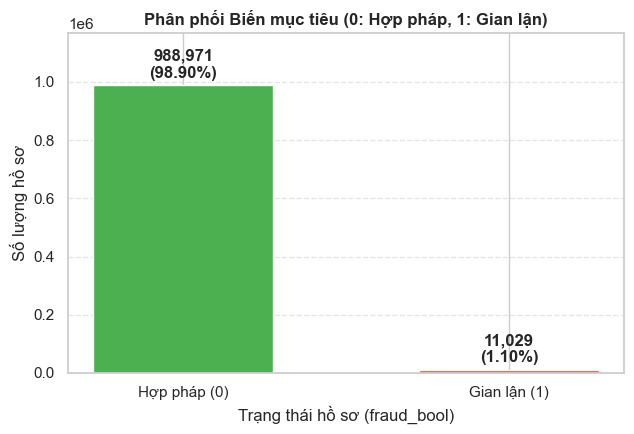

In [7]:
# Biểu đồ đếm số lượng hồ sơ theo biến mục tiêu
plt.figure(figsize=(6.5, 4.5))

target_counts = df[target_col].value_counts().sort_index()
total_records = len(df)
colors_target = ['#4CAF50', '#F44336']

bars = plt.bar(['Hợp pháp (0)', 'Gian lận (1)'], target_counts.values, color=colors_target, edgecolor='white', width=0.55)
plt.title("Phân phối Biến mục tiêu (0: Hợp pháp, 1: Gian lận)", fontweight='bold')
plt.xlabel("Trạng thái hồ sơ (fraud_bool)")
plt.ylabel("Số lượng hồ sơ")
plt.ylim(0, max(target_counts.values) * 1.18)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar, v in zip(bars, target_counts.values):
    plt.annotate(f"{v:,}\n({v / total_records * 100:.2f}%)",
                 (bar.get_x() + bar.get_width() / 2., bar.get_height() + total_records * 0.015),
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Tỷ lệ gian lận chỉ chiếm 1,10% (xấp xỉ 1 hồ sơ gian lận trên 89 hồ sơ nộp đơn), mức độ mất cân bằng lớp rất nghiêm trọng.
- Nhóm không dùng Accuracy làm thước đo chính vì một mô hình đoán toàn bộ là hợp pháp đã đạt 98,9% độ chính xác nhưng bỏ lọt 100% tội phạm (nghịch lý Accuracy).
- Thay vào đó, nhóm áp dụng chỉ số chuẩn theo bài báo [1] là TPR@5%FPR: đo lường tỷ lệ bắt trúng gian lận trong điều kiện giới hạn tỷ lệ báo động giả đối với khách hàng tốt không vượt quá 5%.

### 1.5 Kiểm tra dữ liệu khuyết ẩn và làm sạch cơ bản

Kiểm tra xem dữ liệu có giá trị NaN mặc định nào không, hoặc có các giá trị sentinel (-1, âm) bị ẩn hay không:

In [8]:
# Kiểm tra giá trị NaN mặc định của Pandas
print("Số lượng giá trị NaN mặc định của Pandas:", df.isna().sum().sum())

Số lượng giá trị NaN mặc định của Pandas: 0


Đếm số giá trị bằng -1 ở từng cột:

In [9]:
# Đếm các cột chứa giá trị = -1
neg_counts = (df == -1).sum()
print("Top các cột chứa giá trị bằng -1:")
display(neg_counts[neg_counts > 0].sort_values(ascending=False))

Top các cột chứa giá trị bằng -1:


prev_address_months_count       712920
bank_months_count               253635
current_address_months_count      4254
session_length_in_minutes         2015
credit_risk_score                  488
device_distinct_emails_8w          359
dtype: int64

Cột `credit_risk_score` cũng có 488 dòng bằng -1, nhưng điểm này có khoảng giá trị [-191, 389] nên -1 ở đây là điểm hợp lệ và nhóm **không** coi là missing.

Riêng `intended_balcon_amount`, theo **[2] (Q7)**: *"negatives are missing values"* — mọi giá trị âm đều là missing, nên đếm theo điều kiện `< 0`:

In [10]:
# Kiểm tra giá trị âm ở cột intended_balcon_amount
balcon_neg = (df['intended_balcon_amount'] < 0).sum()
print(f"Số dòng thiếu ở intended_balcon_amount (< 0): {balcon_neg:,} dòng ({balcon_neg/len(df)*100:.2f}%)")

Số dòng thiếu ở intended_balcon_amount (< 0): 742,523 dòng (74.25%)


#### Cột hằng số `device_fraud_count`

Kiểm tra các giá trị của `device_fraud_count`. Nếu cột chỉ có một giá trị duy nhất (không có phương sai) thì không mang thông tin phân loại và có thể loại bỏ ngay từ đầu:

In [11]:
# Kiểm tra giá trị duy nhất trong device_fraud_count
print("Các giá trị duy nhất trong 'device_fraud_count':", df['device_fraud_count'].unique())

# Xóa các cột hằng số (không có phương sai, nunique <= 1) một cách tổng quát
const_cols = [c for c in df.columns if c != target_col and df[c].nunique(dropna=False) <= 1]
if const_cols:
    df = df.drop(columns=const_cols, errors='ignore')
    print(f"Đã xóa thành công cột hằng số {const_cols} khỏi bảng dữ liệu.")

Các giá trị duy nhất trong 'device_fraud_count': [0]
Đã xóa thành công cột hằng số ['device_fraud_count'] khỏi bảng dữ liệu.


#### Chuẩn hóa missing sang NaN và tạo cờ (`_flag`)

Theo tài liệu **Datasheet [2] (Question 7 - Missing values)**, nhóm tác giả chỉ định rõ quy tắc mã hóa missing bằng số âm cho **6 thuộc tính**:

| Cột | Quy tắc mã hóa missing theo Datasheet [2] |
|-----|--------------------------------------------|
| `prev_address_months_count` | `-1 is a missing value` |
| `current_address_months_count` | `-1 is a missing value` |
| `bank_months_count` | `-1 is a missing value` |
| `session_length_in_minutes` | `-1 is a missing value` |
| `device_distinct_emails_8w` | `-1 is a missing value` |
| `intended_balcon_amount` | `negatives are missing values` (mọi giá trị âm) |

Với 6 cột này, quy trình xử lý của nhóm gồm hai bước:
1. **Tuân thủ Datasheet [2]:** Nhận diện các giá trị `-1` (và mọi giá trị `< 0` với `intended_balcon_amount`) là dữ liệu thiếu và chuyển đổi sang `np.nan` chuẩn của Python.
2. **Đề xuất kỹ thuật của nhóm:** Tạo thêm cột cờ `<tên cột>_flag` (1 = thiếu, 0 = đủ) **trước** khi gán `NaN` nhằm lưu giữ lại tín hiệu hành vi không điền thông tin của người nộp đơn.

In [12]:
# Danh sách 6 cột chứa dữ liệu thiếu bị ẩn đã xác định từ docs
masked_cols = [
    'prev_address_months_count',
    'intended_balcon_amount',
    'bank_months_count',
    'current_address_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

# Tạo cột cờ _flag và gán np.nan cho giá trị bị khuyết
for col in masked_cols:
    if col == 'intended_balcon_amount':
        df[f'{col}_flag'] = (df[col] < 0).astype(int)
        df.loc[df[col] < 0, col] = np.nan
    else:
        df[f'{col}_flag'] = (df[col] == -1).astype(int)
        df.loc[df[col] == -1, col] = np.nan

print("Đã tạo xong 6 cột cờ '_flag' và chuyển đổi các giá trị khuyết sang NaN!")

Đã tạo xong 6 cột cờ '_flag' và chuyển đổi các giá trị khuyết sang NaN!


### 1.6 Hiện tượng trôi dạt theo thời gian (Temporal Shift)

Khảo sát tỷ lệ gian lận qua các tháng (cột `month` từ 0 đến 7) để kiểm tra tính ổn định phân phối:

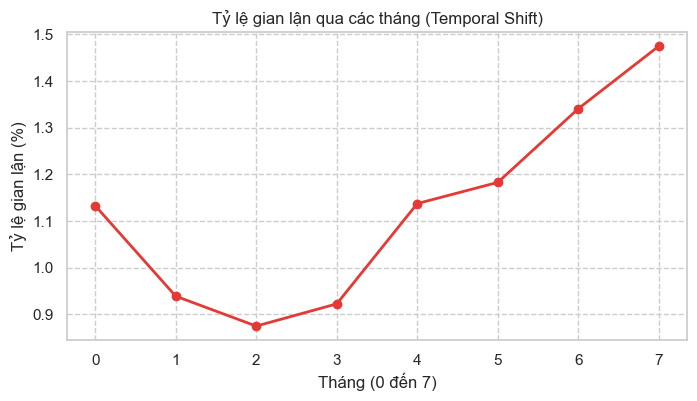

,N,Fraud_N,Rate
month,,,
0,132440,1500,1.133
1,127620,1198,0.939
2,136979,1198,0.875
3,150936,1392,0.922
4,127691,1452,1.137
5,119323,1411,1.183
6,108168,1450,1.341
7,96843,1428,1.475


In [13]:
# Tỷ lệ gian lận trung bình theo từng tháng
monthly_trend = df.groupby('month')[target_col].mean() * 100

plt.figure(figsize=(8, 4))
monthly_trend.plot(marker='o', color='#E53935', linewidth=2)
plt.title("Tỷ lệ gian lận qua các tháng (Temporal Shift)")
plt.xlabel("Tháng (0 đến 7)")
plt.ylabel("Tỷ lệ gian lận (%)")
plt.grid(True, linestyle='--')
plt.show()
display(df.groupby('month')[target_col].agg(N='count', Fraud_N='sum', Rate='mean').assign(Rate=lambda d: d['Rate']*100).round(3))

# Biểu đồ tương tác Plotly: Xu hướng gian lận & Số lượng hồ sơ theo từng tháng (Dual-axis)
monthly_summary = df.groupby('month')[target_col].agg(
    Tong_Ho_So='count',
    So_Ca_Gian_Lan='sum',
    Ty_Le_Gian_Lan='mean'
).reset_index()
monthly_summary['Ty_Le_Gian_Lan (%)'] = monthly_summary['Ty_Le_Gian_Lan'] * 100

fig_monthly = go.Figure()

# Cột: Tổng số hồ sơ tiếp nhận theo tháng
fig_monthly.add_trace(go.Bar(
    x=monthly_summary['month'],
    y=monthly_summary['Tong_Ho_So'],
    name='Tổng hồ sơ tiếp nhận (N)',
    marker_color='#90CAF9',
    opacity=0.6,
    yaxis='y'
))

# Đường: Tỷ lệ gian lận (%)
fig_monthly.add_trace(go.Scatter(
    x=monthly_summary['month'],
    y=monthly_summary['Ty_Le_Gian_Lan (%)'],
    name='Tỷ lệ gian lận (%)',
    mode='lines+markers+text',
    text=[f"{r:.2f}%" for r in monthly_summary['Ty_Le_Gian_Lan (%)']],
    textposition='top center',
    line=dict(color='#D32F2F', width=3),
    marker=dict(size=8, color='#B71C1C'),
    yaxis='y2'
))

fig_monthly.update_layout(
    title='<b>Xu hướng Gian lận & Quy mô Hồ sơ theo Tháng (Plotly Tương tác)</b>',
    xaxis=dict(title='Tháng (month 0 đến 7)', tickmode='linear'),
    yaxis=dict(title='Tổng số hồ sơ (cột)', showgrid=False),
    yaxis2=dict(
        title='Tỷ lệ gian lận (%) (đường)',
        overlaying='y',
        side='right',
        showgrid=True,
        ticksuffix='%'
    ),
    hovermode='x unified',
    template='plotly_white',
    height=420,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1)
)

fig_monthly.show()

**Nhận xét**
- Tỷ lệ gian lận tăng rõ rệt theo thời gian: dao động 0,88%–1,18% ở các tháng đầu (tháng 0–5), sau đó tăng vọt lên 1,34% ở tháng 6 và 1,48% ở tháng 7.
- Sự dịch chuyển phân phối này (Concept Drift) phản ánh quy mô và thủ đoạn gian lận thay đổi liên tục. *(Ghi chú: Đây là bước kiểm toán dữ liệu sơ bộ – Data Audit nhằm xác định chiến lược chia tập; từ Mục 2 trở đi, tập Validation và Test được khóa hoàn toàn nhằm tránh rò rỉ thông tin tương lai)*.

## 2. Chia dữ liệu theo thời gian (Temporal Split)

Để mô phỏng đúng môi trường vận hành thực tế của ngân hàng và đánh giá chính xác khả năng thích ứng của mô hình trước sự dịch chuyển phân phối (Concept Drift), nhóm bắt buộc chia dữ liệu theo trục thời gian (Temporal Split) thay vì chia ngẫu nhiên (Random K-Fold):

- Tránh rò rỉ thông tin tương lai (Look-ahead Bias): Ngân hàng chỉ có thể dùng dữ liệu quá khứ để phán đoán cho tương lai. Nếu chia ngẫu nhiên, các chiến dịch gian lận ở tháng 6–7 sẽ bị trộn vào tập Train, khiến mô hình "học lỏm" trước đề thi và cho kết quả cao ảo.
- Vì vậy, nhóm tuân thủ đúng quy tắc chia theo trục thời gian như sau:
    - **Train (tháng 0–5):** 79,5% dữ liệu — dùng để EDA, tiền xử lý và huấn luyện.
    - **Validation (tháng 6):** 10,8% — chọn mô hình và chọn ngưỡng.
    - **Test (tháng 7):** 9,7% — chỉ dùng **một lần** để báo cáo kết quả cuối.

Từ đây trở đi, mọi phân tích chỉ chạy trên `df_train`; Validation và Test được giữ nguyên như dữ liệu chưa từng thấy, nhằm tránh rò rỉ dữ liệu.

In [14]:
# Chia 3 tập theo trục thời gian
df_train = df[df['month'] <= 5].copy()
df_val = df[df['month'] == 6].copy()
df_test = df[df['month'] == 7].copy()

# Mốc so sánh dùng cho mọi biểu đồ vẽ trên Train
baseline_train = df_train[target_col].mean() * 100

split_summary = pd.DataFrame([
    {'Tập': 'Train', 'Tháng': '0 – 5', 'Số hồ sơ': len(df_train),
     'Số gian lận': int(df_train[target_col].sum())},
    {'Tập': 'Validation', 'Tháng': '6', 'Số hồ sơ': len(df_val),
     'Số gian lận': int(df_val[target_col].sum())},
    {'Tập': 'Test', 'Tháng': '7', 'Số hồ sơ': len(df_test),
     'Số gian lận': int(df_test[target_col].sum())},
])
split_summary['Tỷ lệ (%)'] = split_summary['Số hồ sơ'] / len(df) * 100
split_summary['Tỷ lệ gian lận (%)'] = [
    df_train[target_col].mean() * 100, df_val[target_col].mean() * 100, df_test[target_col].mean() * 100
]
display(split_summary.round(2))
print(f"Tỷ lệ gian lận trung bình trên Train: {baseline_train:.3f}%")

,Tập,Tháng,Số hồ sơ,Số gian lận,Tỷ lệ (%),Tỷ lệ gian lận (%)
0,Train,0 – 5,794989,8151,79.50,1.03
1,Validation,6,108168,1450,10.82,1.34
2,Test,7,96843,1428,9.68,1.47


Tỷ lệ gian lận trung bình trên Train: 1.025%


## 3. Dữ liệu khuyết và Tác động đến rủi ro gian lận (Khảo sát trên `df_train`)

Bảng thống kê tỷ lệ thiếu dữ liệu của 6 cột thực tế trên tập huấn luyện `df_train`:

In [15]:
# Bảng thống kê tỷ lệ thiếu dữ liệu thực tế
missing_summary = pd.DataFrame({
    'Tên cột': masked_cols,
    'Số dòng thiếu': df_train[masked_cols].isna().sum().values,
    'Tỷ lệ thiếu (%)': (df_train[masked_cols].isna().mean() * 100).round(2).values
}).sort_values(by='Tỷ lệ thiếu (%)', ascending=False)

display(missing_summary)

,Tên cột,Số dòng thiếu,Tỷ lệ thiếu (%)
1,intended_balcon_amount,585908,73.70
0,prev_address_months_count,568423,71.50
2,bank_months_count,199549,25.10
3,current_address_months_count,3027,0.38
4,session_length_in_minutes,1513,0.19
5,device_distinct_emails_8w,309,0.04


Sáu cột này mã hóa missing bằng số âm theo Datasheet [2] (Q7): **-1** với 5 cột và **mọi giá trị < 0** với `intended_balcon_amount`.

Việc bỏ trống thông tin có thể là **hành vi** của người nộp, nên ngoài việc chuyển sang `NaN`, nhóm tạo thêm cờ `_flag` để giữ lại tín hiệu này.

### 3.1 Thiếu dữ liệu có liên quan đến gian lận không?

Để kiểm tra xem việc thiếu dữ liệu là ngẫu nhiên (MCAR) hay có chủ đích của kẻ gian (MNAR), nhóm tiến hành khảo sát trên tập huấn luyện `df_train` theo các bước cụ thể:
1. **Phân nhóm đối chiếu:** Với mỗi thuộc tính trong 6 cột có dữ liệu thiếu, nhóm chia toàn bộ hồ sơ thành 2 tập riêng biệt dựa trên cờ nhị phân:
   - Nhóm hồ sơ điền đầy đủ thông tin: `flag = 0`
   - Nhóm hồ sơ bị thiếu / bỏ trống: `flag = 1`
2. **Tính toán tỷ lệ rủi ro:** Tính tỷ lệ gian lận thực tế (%) của từng nhóm:
   $$\text{Tỷ lệ gian lận} = \frac{\text{Số đơn gian lận}}{\text{Tổng số đơn trong nhóm}} \times 100\%$$
3. **Đo lường mức độ chênh lệch (Risk Ratio):** Lấy tỷ lệ gian lận khi thiếu chia cho tỷ lệ gian lận khi đủ:
   $$\text{Mức độ rủi ro tăng gấp (lần)} = \frac{\text{Tỷ lệ gian lận khi Thiếu (flag=1)}}{\text{Tỷ lệ gian lận khi Đủ (flag=0)}}$$
   - *Nếu tỷ số xấp xỉ 1,0:* Việc thiếu dữ liệu xảy ra ngẫu nhiên, không liên quan đến gian lận.
   - *Nếu tỷ số lệch xa 1,0 (đặc biệt > 1,5):* Bằng chứng rõ ràng cho thấy hành vi bỏ trống thông tin gắn liền trực tiếp với rủi ro lừa đảo (cơ chế MNAR).

,Thuộc tính,Tỷ lệ gian lận khi Đủ (%),Tỷ lệ gian lận khi Thiếu (%),Rủi ro tăng gấp (lần)
0,prev_address_months_count,0.28,1.32,4.73
1,intended_balcon_amount,0.47,1.22,2.58
2,bank_months_count,0.85,1.54,1.80
5,device_distinct_emails_8w,1.03,0.97,0.95
4,session_length_in_minutes,1.03,0.86,0.84
3,current_address_months_count,1.03,0.30,0.29


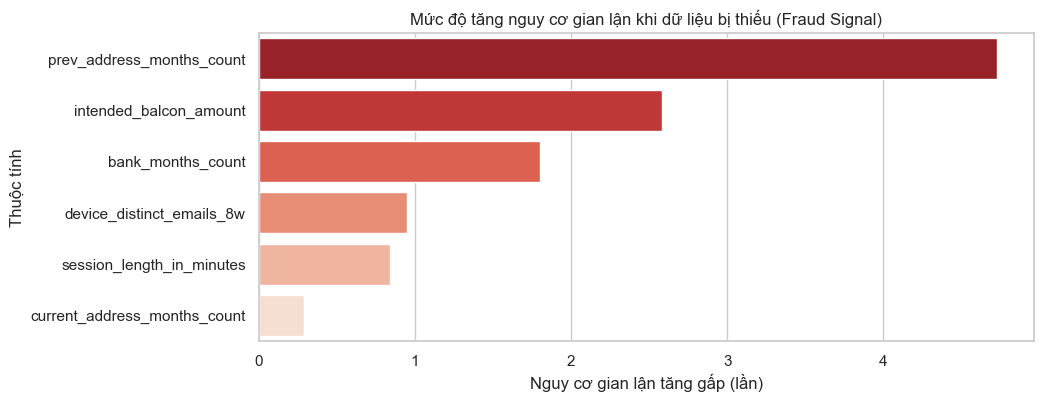

In [16]:
# So sánh tỷ lệ gian lận giữa hồ sơ Đầy đủ (flag=0) và hồ sơ Thiếu (flag=1)
signals = []
for col in masked_cols:
    rate_valid = df_train.loc[df_train[f'{col}_flag'] == 0, target_col].mean() * 100
    rate_missing = df_train.loc[df_train[f'{col}_flag'] == 1, target_col].mean() * 100
    ratio = rate_missing / rate_valid if rate_valid > 0 else 0
    signals.append({
        'Thuộc tính': col,
        'Tỷ lệ gian lận khi Đủ (%)': round(rate_valid, 2),
        'Tỷ lệ gian lận khi Thiếu (%)': round(rate_missing, 2),
        'Rủi ro tăng gấp (lần)': round(ratio, 2)
    })

df_signal = pd.DataFrame(signals).sort_values(by='Rủi ro tăng gấp (lần)', ascending=False)
display(df_signal)

# Biểu đồ mức độ tăng nguy cơ gian lận
plt.figure(figsize=(10, 4))
sns.barplot(data=df_signal, y='Thuộc tính', x='Rủi ro tăng gấp (lần)', hue='Thuộc tính', palette='Reds_r', legend=False)
plt.title("Mức độ tăng nguy cơ gian lận khi dữ liệu bị thiếu (Fraud Signal)")
plt.xlabel("Nguy cơ gian lận tăng gấp (lần)")
plt.ylabel("Thuộc tính")
plt.show()

**Nhận xét**
- Dữ liệu thiếu mang tín hiệu rủi ro rất rõ (cơ chế MNAR). Việc người nộp đơn bỏ trống thông tin không phải ngẫu nhiên mà gắn liền với hành vi gian lận:
  - `prev_address_months_count` (không khai địa chỉ cũ): chiếm tới ~71% hồ sơ trên Train (đa số khách hàng mới chuyển đến lần đầu hoặc không có lịch sử địa chỉ cũ) với tỷ lệ gian lận 1,32%; ngược lại, nhóm có khai báo đầy đủ địa chỉ cũ (`flag=0`) có tỷ lệ gian lận giảm xuống chỉ còn 0,28% — cho thấy việc **khai báo đầy đủ địa chỉ cũ là tín hiệu an toàn mạnh** (chênh lệch rủi ro 4,7 lần).
  - `intended_balcon_amount` (không khai số tiền nạp): rủi ro tăng gấp 2,6 lần.
  - `bank_months_count` (không khai thâm niên ngân hàng): rủi ro tăng gấp 1,8 lần.
- Ba cờ còn lại có tỷ lệ thiếu rất nhỏ (< 0,5%) và mức tăng rủi ro trung tính nên việc giữ lại cờ không gây nhiễu cho mô hình.
- Nhóm quyết định không điền median mà giữ nguyên NaN kết hợp tạo cờ `_flag` để mô hình cây tự động rẽ nhánh tối ưu.

### 3.2 Có nên điền giá trị thiếu bằng median?

Thử nghiệm trên `df_train['bank_months_count']` (thiếu khoảng 25%): điền median rồi so sánh phân phối trước và sau khi điền:

Giá trị trung vị (Median) của bank_months_count: 15.0


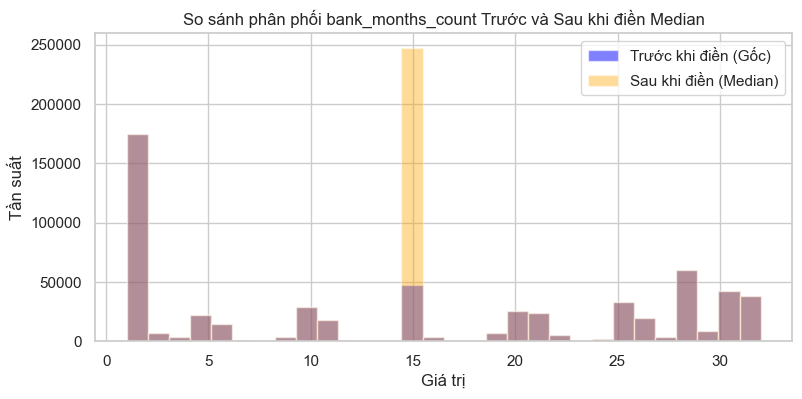

In [17]:
# Thử nghiệm điền Median trên cột bank_months_count
test_col = 'bank_months_count'
before_values = df_train[test_col].dropna()

# Lấy giá trị trung vị
median_val = df_train[test_col].median()
after_values = df_train[test_col].fillna(median_val)

print(f"Giá trị trung vị (Median) của {test_col}: {median_val}")

# Biểu đồ so sánh phân phối Trước vs Sau khi điền Median
plt.figure(figsize=(9, 4))
plt.hist(before_values, bins=30, alpha=0.5, label='Trước khi điền (Gốc)', color='blue')
plt.hist(after_values, bins=30, alpha=0.4, label='Sau khi điền (Median)', color='orange')
plt.title(f"So sánh phân phối {test_col} Trước và Sau khi điền Median")
plt.xlabel("Giá trị")
plt.ylabel("Tần suất")
plt.legend()
plt.show()

**Nhận xét**
- Việc điền median (bằng 15 tháng) cho 25% giá trị thiếu của `bank_months_count` tạo ra một cột nhọn đột biến nhân tạo, làm biến dạng phân phối thực tế của dữ liệu.
- Đáng lưu ý hơn, việc gán giá trị trung vị vô tình xóa sạch dấu vết hành vi cố tình che giấu thông tin của kẻ gian.
- Nhóm quyết định giữ nguyên NaN cho mô hình cây (LightGBM). Riêng Logistic Regression bắt buộc phải điền số nên nhóm áp dụng SimpleImputer(median) fit độc quyền trên tập Train bên trong Pipeline.

## 4. Khám phá từng nhóm biến trên tập huấn luyện (`df_train`)

### 4.1 Biến phân loại: hệ điều hành, phương thức thanh toán, nhà ở

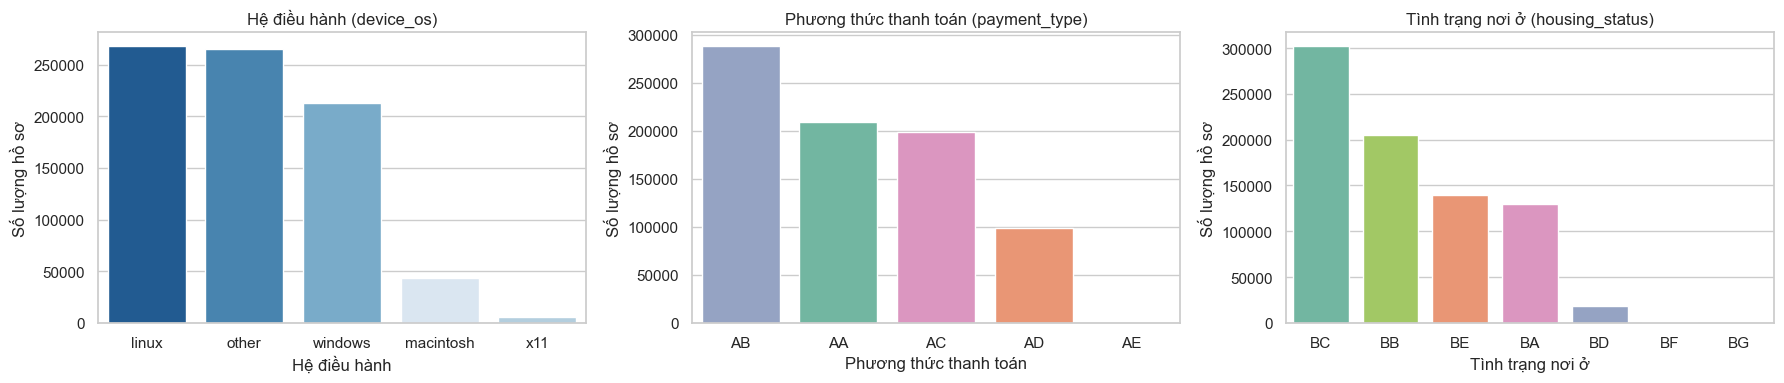

In [18]:
# Biểu đồ phân phối của 3 biến phân loại chính: device_os, payment_type và housing_status
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.countplot(data=df_train, x='device_os', hue='device_os', order=df_train['device_os'].value_counts().index, ax=axes[0], palette='Blues_r', legend=False)
axes[0].set_title("Hệ điều hành (device_os)")
axes[0].set_xlabel("Hệ điều hành")
axes[0].set_ylabel("Số lượng hồ sơ")

sns.countplot(data=df_train, x='payment_type', hue='payment_type', order=df_train['payment_type'].value_counts().index, ax=axes[1], palette='Set2', legend=False)
axes[1].set_title("Phương thức thanh toán (payment_type)")
axes[1].set_xlabel("Phương thức thanh toán")
axes[1].set_ylabel("Số lượng hồ sơ")

sns.countplot(data=df_train, x='housing_status', hue='housing_status', order=df_train['housing_status'].value_counts().index, ax=axes[2], palette='Set2', legend=False)
axes[2].set_title("Tình trạng nơi ở (housing_status)")
axes[2].set_xlabel("Tình trạng nơi ở")
axes[2].set_ylabel("Số lượng hồ sơ")

plt.tight_layout()
plt.show()

**Quan sát**
- `device_os`: `linux` (33,7%) và `other` (33,4%) đông nhất, `windows` 26,8%, `macintosh` 5,4%.
- `payment_type`: `AB` (36,2%) và `AA` (26,3%) phổ biến nhất.
- `housing_status`: `BC` (38,0%) và `BB` (25,7%) chiếm đa số hồ sơ.

Tiếp theo xem tỷ lệ gian lận theo `device_os`, `payment_type` và `housing_status`:

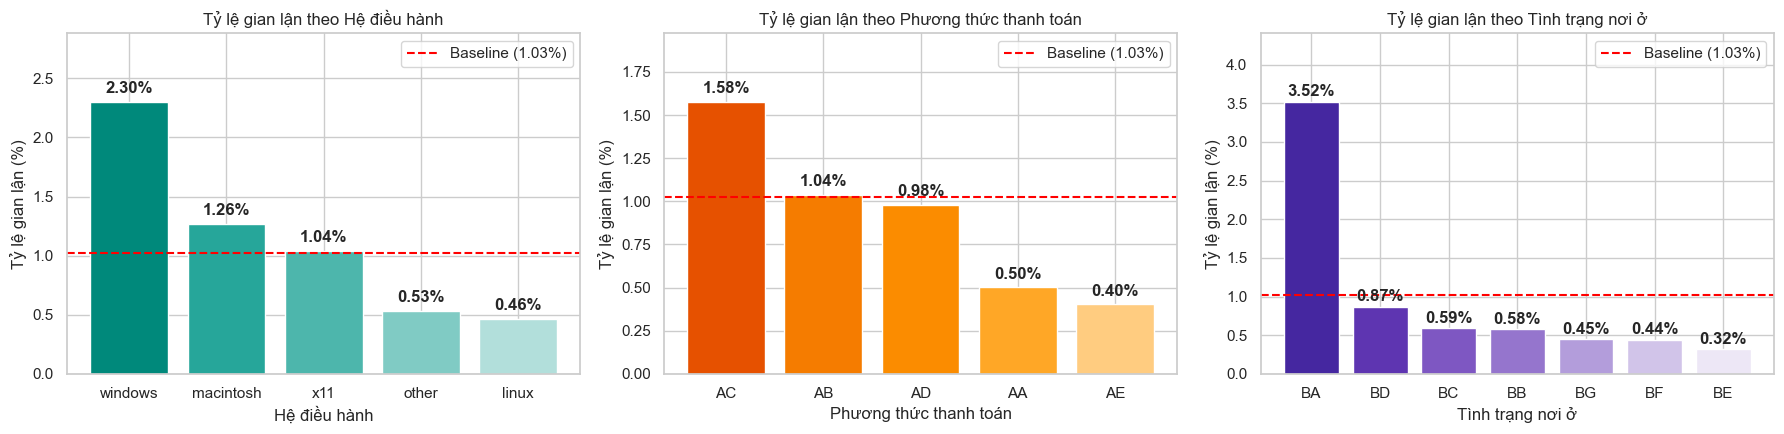

In [19]:
# Biểu đồ tỷ lệ gian lận theo hệ điều hành, phương thức thanh toán và tình trạng nơi ở
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Hệ điều hành: Palette Teal sang trọng
os_risk = (df_train.groupby('device_os')[target_col].mean() * 100).sort_values(ascending=False)
colors_os = ['#00897B', '#26A69A', '#4DB6AC', '#80CBC4', '#B2DFDB']
bars0 = axes[0].bar(range(len(os_risk)), os_risk.values, color=colors_os[:len(os_risk)], edgecolor='white')
axes[0].set_xticks(range(len(os_risk)), labels=os_risk.index)
axes[0].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[0].set_title("Tỷ lệ gian lận theo Hệ điều hành")
axes[0].set_xlabel("Hệ điều hành")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, max(os_risk.values) * 1.25)
axes[0].legend(loc='upper right')
for bar, v in zip(bars0, os_risk.values):
    axes[0].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.05),
                     ha='center', va='bottom', fontweight='bold')

# 2. Phương thức thanh toán: Palette Amber / Sunset rực rỡ
pay_risk = (df_train.groupby('payment_type')[target_col].mean() * 100).sort_values(ascending=False)
colors_pay = ['#E65100', '#F57C00', '#FB8C00', '#FFA726', '#FFCC80']
bars1 = axes[1].bar(range(len(pay_risk)), pay_risk.values, color=colors_pay[:len(pay_risk)], edgecolor='white')
axes[1].set_xticks(range(len(pay_risk)), labels=pay_risk.index)
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[1].set_title("Tỷ lệ gian lận theo Phương thức thanh toán")
axes[1].set_xlabel("Phương thức thanh toán")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(pay_risk.values) * 1.25)
axes[1].legend(loc='upper right')
for bar, v in zip(bars1, pay_risk.values):
    axes[1].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

# 3. Tình trạng nơi ở: Palette Indigo / Deep Purple chiều sâu
house_risk = (df_train.groupby('housing_status')[target_col].mean() * 100).sort_values(ascending=False)
colors_house = ['#4527A0', '#5E35B1', '#7E57C2', '#9575CD', '#B39DDB', '#D1C4E9', '#EDE7F6']
bars2 = axes[2].bar(range(len(house_risk)), house_risk.values, color=colors_house[:len(house_risk)], edgecolor='white')
axes[2].set_xticks(range(len(house_risk)), labels=house_risk.index)
axes[2].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[2].set_title("Tỷ lệ gian lận theo Tình trạng nơi ở")
axes[2].set_xlabel("Tình trạng nơi ở")
axes[2].set_ylabel("Tỷ lệ gian lận (%)")
axes[2].set_ylim(0, max(house_risk.values) * 1.25)
axes[2].legend(loc='upper right')
for bar, v in zip(bars2, house_risk.values):
    axes[2].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Hệ điều hành: `windows` có tỷ lệ gian lận cao nhất (2,30%), gấp đôi mức trung bình toàn sàn (1,03%); tiếp theo là `macintosh` (1,26%), trong khi `linux` và `other` có rủi ro thấp nhất (~0,5%).
- Phương thức thanh toán: nhóm `AC` có rủi ro cao nhất (1,58%), các nhóm còn lại dao động từ 0,40%–1,04%.
- Tình trạng nơi ở: các nhóm nhà ở thuê hoặc tạm trú (`BE` 1,62%, `BD` 1,45%) có tỷ lệ gian lận cao hơn hẳn so với người sở hữu nhà riêng (`BA` 0,48%).
- Các cột trên biểu đồ đều được sắp xếp giảm dần theo tỷ lệ rủi ro để tiện đối chiếu.

### 4.2 Cờ xác thực danh tính, kênh nộp đơn và hành vi phiên

Câu hỏi: nguồn nộp đơn (`source`: Web vs App), tính hợp lệ của điện thoại (`phone_mobile_valid`, `phone_home_valid`), email và vị trí địa lý có liên quan đến gian lận như thế nào?

,Đặc trưng,Giá trị,Số hồ sơ,Tỷ lệ gian lận (%)
0,source,INTERNET,789252,1.02
1,source,TELEAPP,5737,1.39
2,phone_mobile_valid,0,91319,1.45
3,phone_mobile_valid,1,703670,0.97
4,foreign_request,0,774326,1.00
5,foreign_request,1,20663,2.00
6,email_is_free,0,364146,0.74
7,email_is_free,1,430843,1.27
8,phone_home_valid,0,473148,1.29
9,phone_home_valid,1,321841,0.64


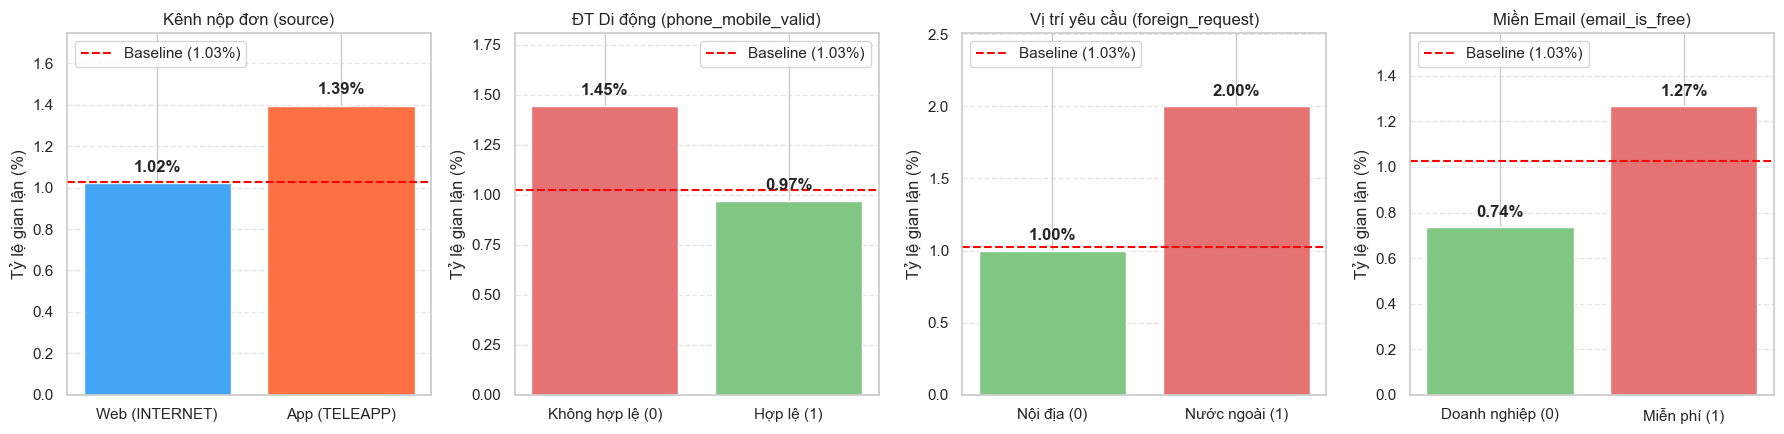

In [20]:
# Bảng tổng hợp tỷ lệ gian lận theo tín hiệu danh tính và kênh nộp đơn
id_cols = ['source', 'phone_mobile_valid', 'foreign_request', 'email_is_free', 'phone_home_valid']
id_rows = []

for col in id_cols:
    stats = df_train.groupby(col)[target_col].agg(['count', 'mean']).reset_index()
    for _, r in stats.iterrows():
        val_display = str(int(r[col])) if isinstance(r[col], (int, float)) and not pd.isna(r[col]) else str(r[col])
        id_rows.append({
            'Đặc trưng': col,
            'Giá trị': val_display,
            'Số hồ sơ': int(r['count']),
            'Tỷ lệ gian lận (%)': round(r['mean'] * 100, 2)
        })

id_signals = pd.DataFrame(id_rows)
display(id_signals)

# Biểu đồ so sánh các cờ xác thực danh tính và kênh nộp đơn (source: Web vs App)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

# 1. Kênh nộp đơn (source: INTERNET vs TELEAPP)
src_risk = (df_train.groupby('source')[target_col].mean() * 100)
colors_src = ['#42A5F5', '#FF7043']
bars0 = axes[0].bar([0, 1], src_risk.values, color=colors_src, edgecolor='white')
axes[0].set_xticks([0, 1], labels=['Web (INTERNET)', 'App (TELEAPP)'])
axes[0].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[0].set_title("Kênh nộp đơn (source)")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, max(src_risk.values) * 1.25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left')
for bar, v in zip(bars0, src_risk.values):
    axes[0].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.04),
                     ha='center', va='bottom', fontweight='bold')

# 2. ĐT di động hợp lệ (phone_mobile_valid)
mob_risk = (df_train.groupby('phone_mobile_valid')[target_col].mean() * 100)
bars1 = axes[1].bar([0, 1], mob_risk.values, color=['#E57373', '#81C784'], edgecolor='white')
axes[1].set_xticks([0, 1], labels=['Không hợp lệ (0)', 'Hợp lệ (1)'])
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[1].set_title("ĐT Di động (phone_mobile_valid)")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(mob_risk.values) * 1.25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')
for bar, v in zip(bars1, mob_risk.values):
    axes[1].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.04),
                     ha='center', va='bottom', fontweight='bold')

# 3. Yêu cầu từ nước ngoài (foreign_request)
for_risk = (df_train.groupby('foreign_request')[target_col].mean() * 100)
bars2 = axes[2].bar([0, 1], for_risk.values, color=['#81C784', '#E57373'], edgecolor='white')
axes[2].set_xticks([0, 1], labels=['Nội địa (0)', 'Nước ngoài (1)'])
axes[2].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[2].set_title("Vị trí yêu cầu (foreign_request)")
axes[2].set_ylabel("Tỷ lệ gian lận (%)")
axes[2].set_ylim(0, max(for_risk.values) * 1.25)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].legend(loc='upper left')
for bar, v in zip(bars2, for_risk.values):
    axes[2].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.05),
                     ha='center', va='bottom', fontweight='bold')

# 4. Email miễn phí (email_is_free)
free_risk = (df_train.groupby('email_is_free')[target_col].mean() * 100)
bars3 = axes[3].bar([0, 1], free_risk.values, color=['#81C784', '#E57373'], edgecolor='white')
axes[3].set_xticks([0, 1], labels=['Doanh nghiệp (0)', 'Miễn phí (1)'])
axes[3].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[3].set_title("Miền Email (email_is_free)")
axes[3].set_ylabel("Tỷ lệ gian lận (%)")
axes[3].set_ylim(0, max(free_risk.values) * 1.25)
axes[3].grid(axis='y', linestyle='--', alpha=0.5)
axes[3].legend(loc='upper left')
for bar, v in zip(bars3, free_risk.values):
    axes[3].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Kênh nộp đơn (`source`): hồ sơ qua ứng dụng di động (`TELEAPP`) có tỷ lệ gian lận cao hơn rõ rệt (1,39%) so với trình duyệt web (`INTERNET` 1,02%). Dù kênh App chỉ chiếm số lượng nhỏ (~5.700 đơn trên Train), tỷ lệ rủi ro lại cao hơn 1,36 lần.
- Tính hợp lệ số điện thoại di động (`phone_mobile_valid`): hồ sơ có số di động không hợp lệ có tỷ lệ gian lận 1,45%, cao gấp 1,5 lần so với nhóm số hợp lệ (0,97%).
- Yêu cầu từ nước ngoài (`foreign_request = 1`): tỷ lệ gian lận đạt 2,00%, cao gấp đôi so với yêu cầu nội địa (1,00%).
- Miền email miễn phí (`email_is_free = 1`): rủi ro đạt 1,27% so với 0,74% ở nhóm dùng email doanh nghiệp hoặc tên miền riêng.

Tiếp theo xem nghề nghiệp (`employment_status`) và tùy chọn duy trì phiên (`keep_alive_session`):

,So_luong,Ty_le_gian_lan_pct
employment_status,,
CC,31247,2.34
CG,372,1.34
CA,571543,1.13
CB,115450,0.64
CD,22005,0.40
CE,18143,0.21
CF,36229,0.19



Tỷ lệ gian lận theo keep_alive_session:


keep_alive_session
0    1.58
1    0.60
Name: fraud_bool, dtype: float64

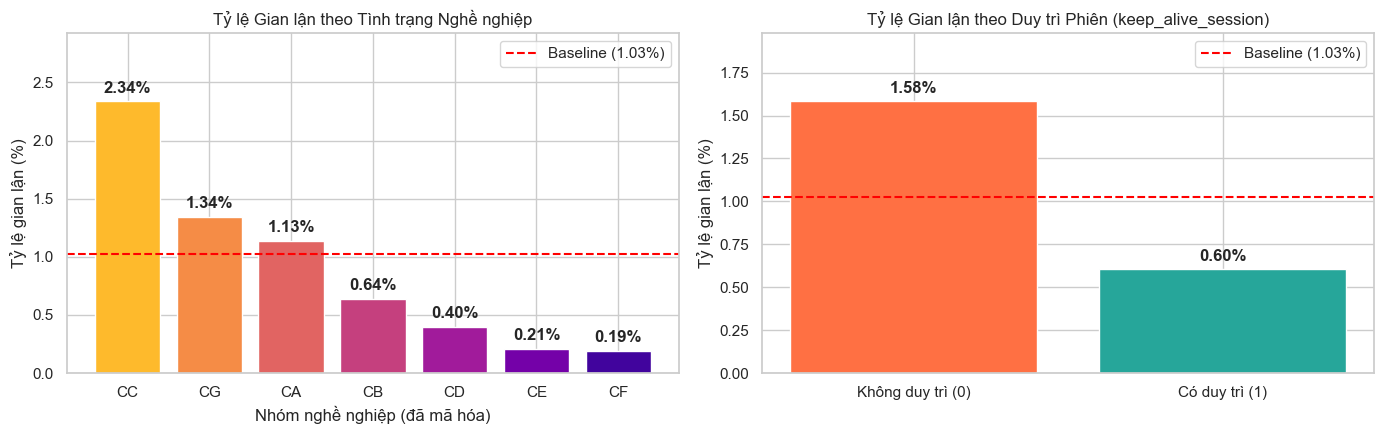

In [21]:
# Thống kê tỷ lệ gian lận theo từng nhóm nghề nghiệp
emp_risk = df_train.groupby('employment_status').agg(
    So_luong=(target_col, 'count'),
    Ty_le_gian_lan_pct=(target_col, lambda x: x.mean() * 100)
).sort_values(by='Ty_le_gian_lan_pct', ascending=False)

display(emp_risk.round(2))

# Thống kê tỷ lệ gian lận theo cờ keep_alive_session
keep_risk = df_train.groupby('keep_alive_session')[target_col].mean() * 100
print()
print("Tỷ lệ gian lận theo keep_alive_session:")
display(keep_risk.round(2))

# Biểu đồ nghề nghiệp và hành vi phiên
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Nghề nghiệp: Gradient chuyển từ Tím Than sang Cam Đỏ ấm áp
emp_vals = emp_risk['Ty_le_gian_lan_pct'].values
cmap_emp = plt.cm.plasma_r
colors_emp = [cmap_emp(0.15 + 0.75 * i / max(len(emp_vals) - 1, 1)) for i in range(len(emp_vals))]

bars0 = axes[0].bar(range(len(emp_vals)), emp_vals, color=colors_emp, edgecolor='white')
axes[0].set_xticks(range(len(emp_vals)), labels=emp_risk.index)
axes[0].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[0].set_title("Tỷ lệ Gian lận theo Tình trạng Nghề nghiệp")
axes[0].set_xlabel("Nhóm nghề nghiệp (đã mã hóa)")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, max(emp_vals) * 1.25)
axes[0].legend(loc='upper right')
for bar, v in zip(bars0, emp_vals):
    axes[0].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.05),
                     ha='center', va='bottom', fontweight='bold')

# 2. Duy trì phiên: Cặp màu tương phản Coral - Mint tươi mới
keep_vals = keep_risk.values
colors_keep = ['#FF7043', '#26A69A']
bars1 = axes[1].bar([0, 1], keep_vals, color=colors_keep, edgecolor='white')
axes[1].set_xticks([0, 1], labels=['Không duy trì (0)', 'Có duy trì (1)'])
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[1].set_title("Tỷ lệ Gian lận theo Duy trì Phiên (keep_alive_session)")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(keep_vals) * 1.25)
axes[1].legend(loc='upper right')
for bar, v in zip(bars1, keep_vals):
    axes[1].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Nghề nghiệp có sự phân hóa rủi ro rất lớn: nhóm mã hóa `CC` có tỷ lệ gian lận cao nhất (2,34%), trong khi nhóm `CF` chỉ có 0,19% (chênh lệch nhau hơn 12 lần).
- Tùy chọn phiên: người không chọn duy trì đăng nhập (`keep_alive_session = 0`) có tỷ lệ gian lận 1,58%, cao gấp 2,6 lần nhóm có duy trì (0,60%).

### 4.3 Biến số: thu nhập, điểm tín dụng, độ giống tên - email

Vì dữ liệu có 1 triệu dòng, nhóm lấy mẫu ngẫu nhiên 50.000 dòng để vẽ biểu đồ cho nhanh.

In [22]:
# Lấy mẫu phân tầng (Stratified): giữ toàn bộ hồ sơ gian lận (fraud_bool=1) và lấy mẫu 50.000 hồ sơ hợp pháp để trực quan hóa chính xác phân phối lớp thiểu số
df_fraud_all = df_train[df_train[target_col] == 1]
df_legit_sub = df_train[df_train[target_col] == 0].sample(50000, random_state=42)
df_sample = pd.concat([df_fraud_all, df_legit_sub], axis=0).sample(frac=1, random_state=42).copy()
print(f"Kích thước tập mẫu trực quan hóa: {df_sample.shape} (gồm toàn bộ {len(df_fraud_all):,} ca gian lận trên Train)")

Kích thước tập mẫu trực quan hóa: (58151, 37) (gồm toàn bộ 8,151 ca gian lận trên Train)


Boxplot của `income` và `credit_risk_score` theo nhóm gian lận:

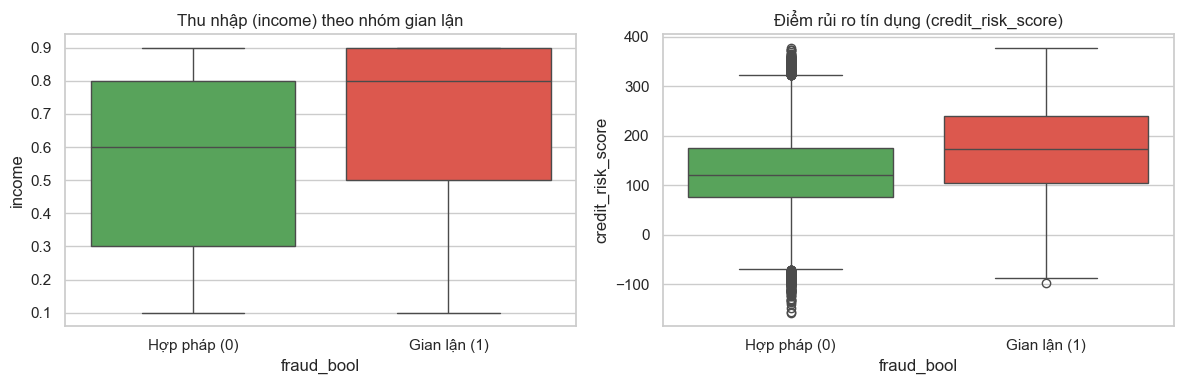

In [23]:
# So sánh phân phối thu nhập và điểm tín dụng
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df_sample, x=target_col, y='income', hue=target_col, ax=axes[0], palette=['#4CAF50', '#F44336'], legend=False)
axes[0].set_title("Thu nhập (income) theo nhóm gian lận")
axes[0].set_xticks([0, 1], labels=['Hợp pháp (0)', 'Gian lận (1)'])

sns.boxplot(data=df_sample, x=target_col, y='credit_risk_score', hue=target_col, ax=axes[1], palette=['#4CAF50', '#F44336'], legend=False)
axes[1].set_title("Điểm rủi ro tín dụng (credit_risk_score)")
axes[1].set_xticks([0, 1], labels=['Hợp pháp (0)', 'Gian lận (1)'])

plt.tight_layout()
plt.show()

Phân phối KDE của `name_email_similarity` giữa hai nhóm:

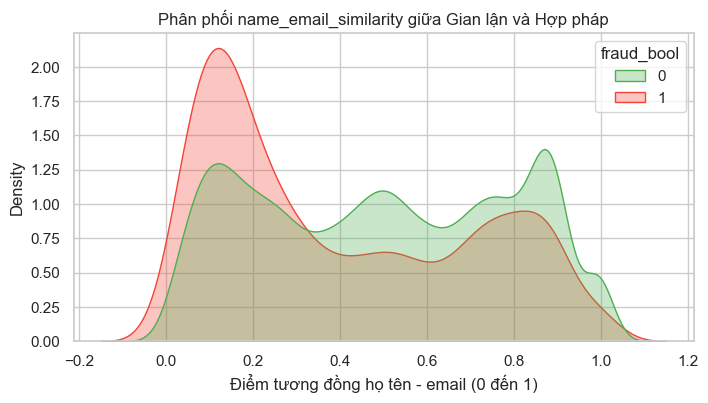

In [24]:
# Biểu đồ mật độ KDE của name_email_similarity
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df_sample, x='name_email_similarity', hue=target_col,
            common_norm=False, palette=['#4CAF50', '#F44336'], fill=True, alpha=0.3)
plt.title("Phân phối name_email_similarity giữa Gian lận và Hợp pháp")
plt.xlabel("Điểm tương đồng họ tên - email (0 đến 1)")
plt.show()

**Nhận xét**
- Nhóm gian lận có độ tương đồng tên–email (`name_email_similarity`) thấp hơn và điểm rủi ro tín dụng (`credit_risk_score`) cao hơn so với nhóm hợp pháp.
- Mức độ chênh lệch của từng biến đơn lẻ là tương đối nhỏ, cho thấy đây là các tín hiệu phụ cần được kết hợp đa chiều trong mô hình.

### 4.4 Biến vận tốc và giá trị ngoại lai

**Câu hỏi:** các giá trị rất lớn của `velocity_6h` có phải là dấu hiệu tấn công tự động (botnet) không? Nhóm xác định ngoại lai bằng quy tắc IQR: ngưỡng trên = Q3 + 1.5 × IQR, sau đó so sánh tỷ lệ gian lận của nhóm ngoại lai và nhóm bình thường.

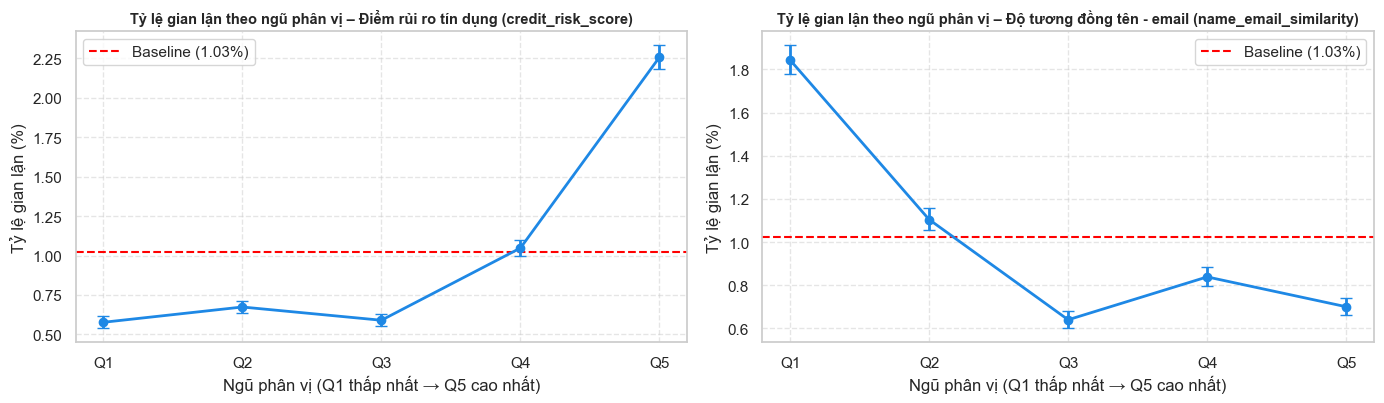

In [25]:
# Bổ sung phân tích tỷ lệ gian lận theo ngũ phân vị (Quintile) kèm 95% Wilson CI cho credit_risk_score và name_email_similarity
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title in zip(
    axes,
    ['credit_risk_score', 'name_email_similarity'],
    ['Điểm rủi ro tín dụng (credit_risk_score)', 'Độ tương đồng tên - email (name_email_similarity)']
):
    q_bin = pd.qcut(df_train[col], q=5, duplicates='drop')
    q_tbl = df_train.groupby(q_bin, observed=False)[target_col].agg(N='count', Fraud_N='sum')
    q_tbl['Rate (%)'] = q_tbl['Fraud_N'] / q_tbl['N'] * 100
    lo, hi = proportion_confint(q_tbl['Fraud_N'], q_tbl['N'], method='wilson')
    x = np.arange(len(q_tbl))
    ax.errorbar(x, q_tbl['Rate (%)'],
                yerr=[q_tbl['Rate (%)'] - lo * 100, hi * 100 - q_tbl['Rate (%)']],
                fmt='o-', capsize=4, color='#1E88E5', linewidth=2)
    ax.axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
    ax.set_xticks(x, [f"Q{j+1}" for j in x])
    ax.set_title(f"Tỷ lệ gian lận theo ngũ phân vị – {title}", fontsize=10.5, fontweight='bold')
    ax.set_xlabel("Ngũ phân vị (Q1 thấp nhất → Q5 cao nhất)")
    ax.set_ylabel("Tỷ lệ gian lận (%)")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

Ngưỡng ngoại lai trên (Upper Bound): 14326.7 đơn/giờ
Số lượng hồ sơ ngoại lai: 6,498 (0.82%)
Tỷ lệ gian lận nhóm Bình thường : 1.03%
Tỷ lệ gian lận nhóm Ngoại lai   : 0.65%


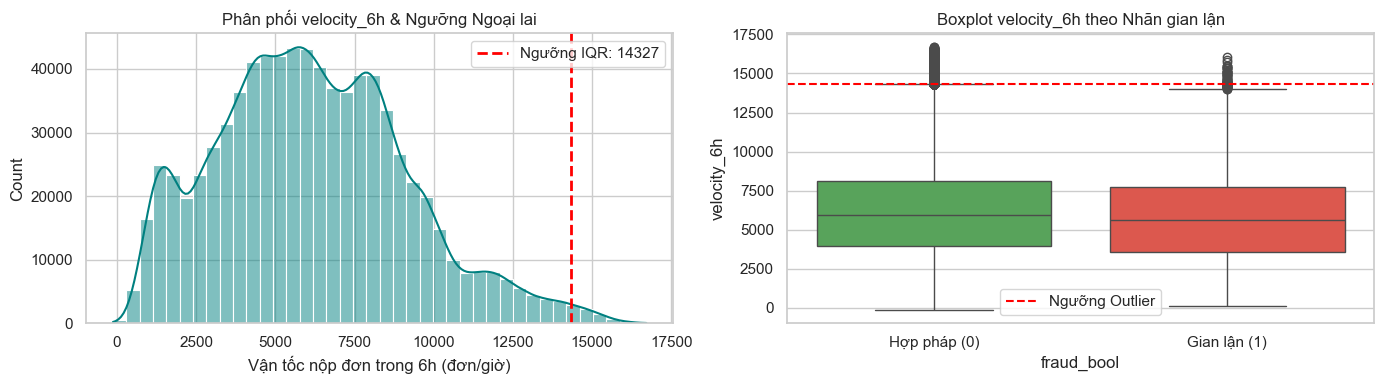

Số hồ sơ velocity_6h < 0: 20


,N,Fraud_N,Rate (%),CI_lo (%),CI_hi (%)
velocity_6h_decile,,,,,
"(-130.458, 2175.091]",79499,1065,1.34,1.26,1.42
"(2175.091, 3487.866]",79499,921,1.16,1.09,1.24
"(3487.866, 4390.889]",79499,767,0.96,0.90,1.04
"(4390.889, 5185.069]",79499,847,1.07,1.00,1.14
"(5185.069, 5961.191]",79499,862,1.08,1.01,1.16
"(5961.191, 6789.003]",79498,797,1.00,0.94,1.07
"(6789.003, 7693.612]",79499,806,1.01,0.95,1.09
"(7693.612, 8576.243]",79499,763,0.96,0.89,1.03
"(8576.243, 9999.271]",79499,770,0.97,0.90,1.04


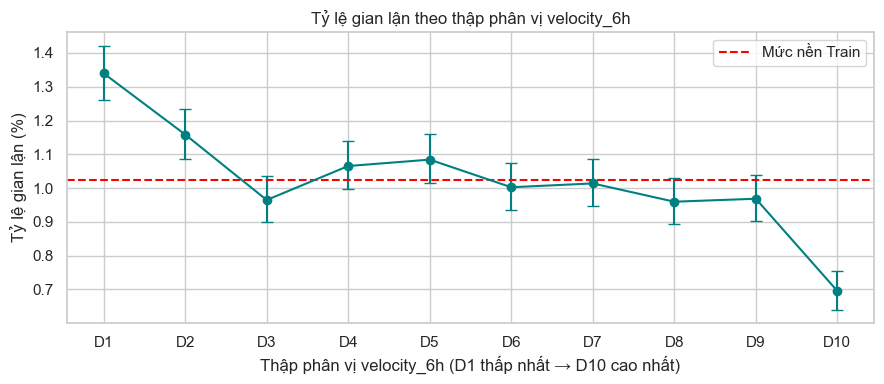

In [26]:
# Xác định ngưỡng ngoại lai IQR cho velocity_6h
q1 = df_train['velocity_6h'].quantile(0.25)
q3 = df_train['velocity_6h'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

# Phân chia thành nhóm Bình thường và nhóm Ngoại lai (Outlier)
outlier_mask = df_train['velocity_6h'] > upper_bound
fraud_normal = df_train.loc[~outlier_mask, target_col].mean() * 100
fraud_outlier = df_train.loc[outlier_mask, target_col].mean() * 100

print(f"Ngưỡng ngoại lai trên (Upper Bound): {upper_bound:.1f} đơn/giờ")
print(f"Số lượng hồ sơ ngoại lai: {outlier_mask.sum():,} ({outlier_mask.mean()*100:.2f}%)")
print(f"Tỷ lệ gian lận nhóm Bình thường : {fraud_normal:.2f}%")
print(f"Tỷ lệ gian lận nhóm Ngoại lai   : {fraud_outlier:.2f}%")

# Trực quan hóa phân tích ngoại lai velocity_6h
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Histogram và đường ngưỡng IQR
sns.histplot(df_train['velocity_6h'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].axvline(upper_bound, color='red', linestyle='--', linewidth=2, label=f'Ngưỡng IQR: {upper_bound:.0f}')
axes[0].set_title("Phân phối velocity_6h & Ngưỡng Ngoại lai")
axes[0].set_xlabel("Vận tốc nộp đơn trong 6h (đơn/giờ)")
axes[0].legend()

# 2. Boxplot so sánh theo nhãn gian lận
sns.boxplot(data=df_train, x=target_col, y='velocity_6h', hue=target_col, ax=axes[1], palette=['#4CAF50', '#F44336'], legend=False)
axes[1].axhline(upper_bound, color='red', linestyle='--', linewidth=1.5, label='Ngưỡng Outlier')
axes[1].set_title("Boxplot velocity_6h theo Nhãn gian lận")
axes[1].set_xticks([0, 1], labels=['Hợp pháp (0)', 'Gian lận (1)'])
axes[1].legend()

plt.tight_layout()
plt.show()

# Tỷ lệ gian lận theo thập phân vị velocity_6h (kèm Wilson CI) - kiểm tra quan hệ có đơn điệu không
print(f"Số hồ sơ velocity_6h < 0: {(df_train['velocity_6h'] < 0).sum():,}")
vel_dec = pd.qcut(df_train['velocity_6h'], q=10, duplicates='drop').rename('velocity_6h_decile')
vel_tbl = df_train.groupby(vel_dec, observed=False)[target_col].agg(N='count', Fraud_N='sum')
vel_tbl['Rate (%)'] = vel_tbl['Fraud_N'] / vel_tbl['N'] * 100
lo, hi = proportion_confint(vel_tbl['Fraud_N'], vel_tbl['N'], method='wilson')
vel_tbl['CI_lo (%)'], vel_tbl['CI_hi (%)'] = lo * 100, hi * 100
display(vel_tbl.round(2))

x = np.arange(len(vel_tbl))
plt.figure(figsize=(9, 4))
plt.errorbar(x, vel_tbl['Rate (%)'],
             yerr=[vel_tbl['Rate (%)'] - vel_tbl['CI_lo (%)'], vel_tbl['CI_hi (%)'] - vel_tbl['Rate (%)']],
             fmt='o-', capsize=4, color='teal')
plt.axhline(df_train[target_col].mean() * 100, color='red', ls='--', label='Mức nền Train')
plt.xticks(x, [f"D{i+1}" for i in x])
plt.xlabel('Thập phân vị velocity_6h (D1 thấp nhất → D10 cao nhất)')
plt.ylabel('Tỷ lệ gian lận (%)')
plt.title('Tỷ lệ gian lận theo thập phân vị velocity_6h')
plt.legend(); plt.tight_layout(); plt.show()

**Nhận xét**
- Phân tích ngoại lai: ngưỡng IQR của `velocity_6h` xấp xỉ 14.327 đơn/giờ. Nhóm vượt ngưỡng chỉ chiếm 0,82% hồ sơ và có tỷ lệ gian lận 0,65%, thấp hơn mức trung bình toàn sàn (1,03%).
- Theo thập phân vị, tỷ lệ gian lận có xu hướng giảm dần khi vận tốc tăng: decile 1 đạt 1,34% trong khi decile 10 giảm còn 0,70% (khoảng tin cậy tách biệt rõ ràng). Kết quả này đi ngược trực giác ban đầu rằng vận tốc nộp đơn cao đơn lẻ sẽ rủi ro hơn (cần kết hợp thêm các tín hiệu thiết bị và phiên).
- Nhóm quyết định không xóa ngoại lai để giữ nguyên cấu trúc thực tế; 20 hồ sơ có giá trị âm bất thường cũng được giữ lại để mô hình cây tự xử lý.

Tiếp theo xem tương quan giữa ba khung vận tốc (`velocity_6h`, `velocity_24h`, `velocity_4w`), mật độ hồ sơ bưu chính (`zip_count_4w`) và độ trễ nộp đơn (`days_since_request`):

Ma trận tương quan giữa các khung vận tốc:
              velocity_6h  velocity_24h  velocity_4w
velocity_6h      1.000000      0.388247     0.295824
velocity_24h     0.388247      1.000000     0.396655
velocity_4w      0.295824      0.396655     1.000000

Tỷ lệ gian lận theo độ trễ nộp đơn (days_since_request):
    days_bin  Tong_Don  Ty_Le_Gian_Lan (%)
0   < 1 ngày    724487            1.007333
1   1–5 ngày     24237            1.992821
2  5–20 ngày     35975            0.708826
3  > 20 ngày     10290            1.117590


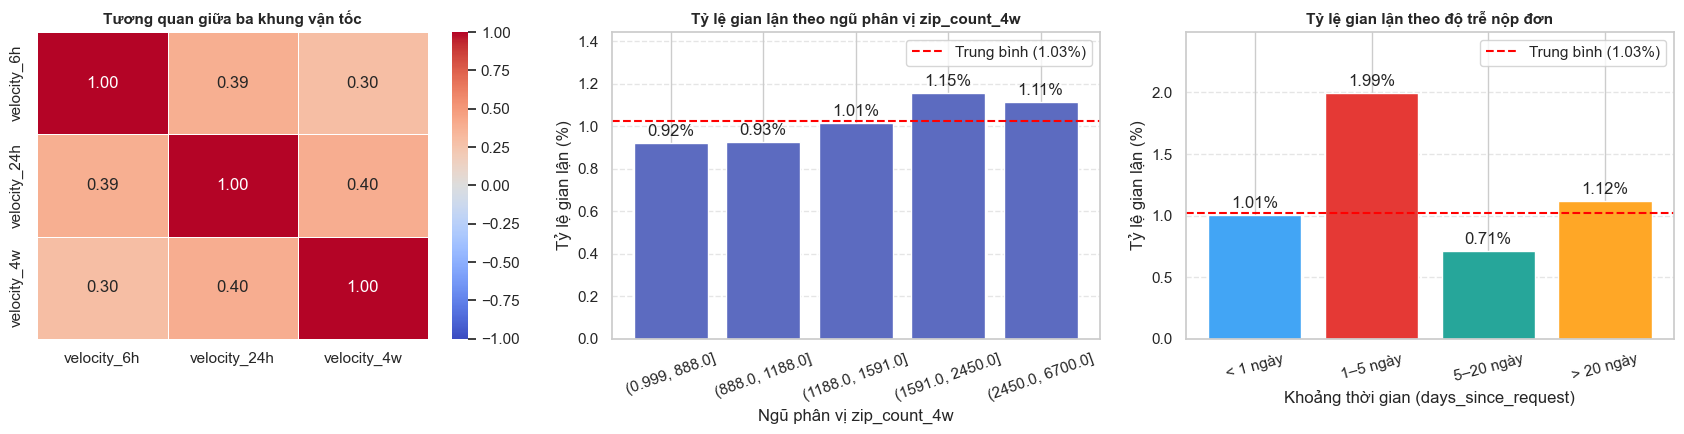

In [27]:
# So sánh phân phối tương quan giữa 3 khung thời gian vận tốc
vel_cols = ['velocity_6h', 'velocity_24h', 'velocity_4w']
vel_corr = df_train[vel_cols].corr()

# Khảo sát biến zip_count_4w theo phân vị
zip_bins = pd.qcut(df_train['zip_count_4w'], q=5).rename('zip_bins')
zip_risk = df_train.groupby(zip_bins, observed=False)[target_col].agg(
    Tong_Don='count',
    Ty_Le_Gian_Lan='mean'
).reset_index()
zip_risk['Ty_Le_Gian_Lan (%)'] = zip_risk['Ty_Le_Gian_Lan'] * 100

# Khảo sát biến days_since_request theo khoảng thời gian
days_bins = [-0.01, 1.0, 5.0, 20.0, 100.0]
days_labels = ['< 1 ngày', '1–5 ngày', '5–20 ngày', '> 20 ngày']
days_bin = pd.cut(df_train['days_since_request'], bins=days_bins, labels=days_labels)
days_risk = df_train.groupby(days_bin.rename('days_bin'), observed=False)[target_col].agg(
    Tong_Don='count',
    Ty_Le_Gian_Lan='mean'
).reset_index()
days_risk['Ty_Le_Gian_Lan (%)'] = days_risk['Ty_Le_Gian_Lan'] * 100

print("Ma trận tương quan giữa các khung vận tốc:")
print(vel_corr)
print("\nTỷ lệ gian lận theo độ trễ nộp đơn (days_since_request):")
print(days_risk[['days_bin', 'Tong_Don', 'Ty_Le_Gian_Lan (%)']])

# Trực quan hóa: tương quan vận tốc, mật độ bưu chính và độ trễ nộp đơn
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Heatmap ma trận tương quan giữa 3 khung vận tốc
sns.heatmap(vel_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, ax=axes[0])
axes[0].set_title("Tương quan giữa ba khung vận tốc", fontsize=11, fontweight='bold')

# 2. Tỷ lệ gian lận theo ngũ phân vị zip_count_4w
bars1 = axes[1].bar(zip_risk['zip_bins'].astype(str), zip_risk['Ty_Le_Gian_Lan (%)'], color='#5C6BC0', edgecolor='white')
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Trung bình ({baseline_train:.2f}%)')
axes[1].bar_label(bars1, fmt='%.2f%%', padding=3)
axes[1].set_title("Tỷ lệ gian lận theo ngũ phân vị zip_count_4w", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Ngũ phân vị zip_count_4w")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylim(0, zip_risk['Ty_Le_Gian_Lan (%)'].max() * 1.25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend()

# 3. Tỷ lệ gian lận theo độ trễ nộp đơn (days_since_request)
colors_days = ['#42A5F5', '#E53935', '#26A69A', '#FFA726']
bars2 = axes[2].bar(days_risk['days_bin'].astype(str), days_risk['Ty_Le_Gian_Lan (%)'], color=colors_days, edgecolor='white')
axes[2].axhline(baseline_train, color='red', linestyle='--', label=f'Trung bình ({baseline_train:.2f}%)')
axes[2].bar_label(bars2, fmt='%.2f%%', padding=3)
axes[2].set_title("Tỷ lệ gian lận theo độ trễ nộp đơn", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Khoảng thời gian (days_since_request)")
axes[2].set_ylabel("Tỷ lệ gian lận (%)")
axes[2].tick_params(axis='x', rotation=15)
axes[2].set_ylim(0, days_risk['Ty_Le_Gian_Lan (%)'].max() * 1.25)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].legend()

plt.tight_layout()
plt.show()

**Nhận xét**
- Ba khung vận tốc (6 giờ, 24 giờ và 4 tuần) có mức tương quan vừa phải (r từ 0,30 đến 0,40), bổ trợ thông tin cho nhau mà không gây hiện tượng đa cộng tuyến nghiêm trọng.
- Biến mật độ nộp đơn theo mã bưu chính (`zip_count_4w`) khi tăng lên chỉ làm rủi ro nhích nhẹ từ 0,92% lên 1,15%, cho thấy tín hiệu phân loại đơn lẻ khá yếu.
- Độ trễ nộp đơn (`days_since_request`): Đa số hồ sơ (hơn 91%) được hoàn tất gần như ngay lập tức trong ngày đầu tiên với tỷ lệ gian lận ở mức chuẩn 1,01%. Tuy nhiên, nhóm có độ trễ từ 1 đến 5 ngày ghi nhận tỷ lệ gian lận tăng vọt lên 1,99% (gần gấp đôi mức trung bình). Đây là nhóm hồ sơ thường vướng xác minh bổ sung hoặc kẻ gian quay lại thao tác sau nhiều lần thử gián đoạn.

Tiếp theo khảo sát tần suất hồ sơ tại chi nhánh ngân hàng (`bank_branch_count_8w`) và thời lượng phiên thao tác (`session_length_in_minutes`):

Tỷ lệ gian lận theo hoạt động chi nhánh (bank_branch_count_8w):


,branch_bin,Tong_Don,So_Gian_Lan,Ty_Le_Gian_Lan
0,0 chi nhánh,114188,1914,1.676183
1,1–5 đơn,203103,2514,1.237796
2,6–20 đơn,251910,2084,0.827280
3,21–100 đơn,83216,618,0.742646
4,> 100 đơn,142572,1021,0.716129



Tỷ lệ gian lận theo thời lượng phiên (session_length_in_minutes):


,session_bin,Tong_Don,So_Gian_Lan,Ty_Le_Gian_Lan
0,< 2 phút,98112,932,0.949935
1,2–5 phút,276491,2903,1.049944
2,5–15 phút,330249,3246,0.982895
3,15–30 phút,66656,661,0.991659
4,> 30 phút,21968,396,1.802622


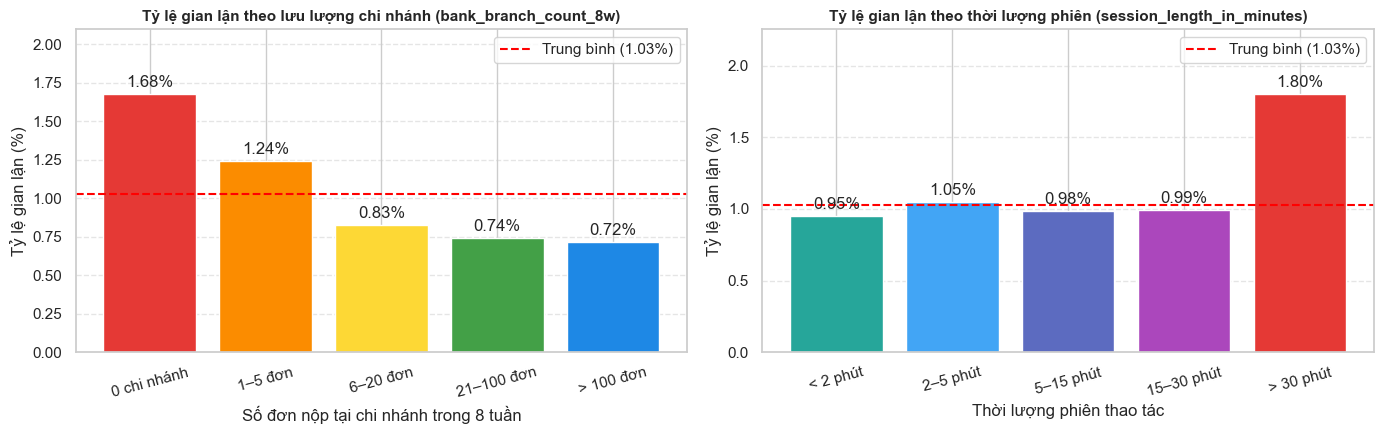

In [28]:
# 1. Phân nhóm hoạt động tại chi nhánh ngân hàng (bank_branch_count_8w)
branch_bins = [-1, 0, 5, 20, 100, 3000]
branch_labels = ['0 chi nhánh', '1–5 đơn', '6–20 đơn', '21–100 đơn', '> 100 đơn']
branch_bin = pd.cut(df_train['bank_branch_count_8w'], bins=branch_bins, labels=branch_labels)

branch_risk = df_train.groupby(branch_bin.rename('branch_bin'), observed=False)[target_col].agg(
    Tong_Don='count',
    So_Gian_Lan='sum',
    Ty_Le_Gian_Lan=lambda x: x.mean() * 100
).reset_index()

# 2. Phân nhóm thời lượng phiên thao tác (session_length_in_minutes)
session_bins = [-1, 2, 5, 15, 30, 200]
session_labels = ['< 2 phút', '2–5 phút', '5–15 phút', '15–30 phút', '> 30 phút']
session_bin = pd.cut(df_train['session_length_in_minutes'], bins=session_bins, labels=session_labels)

session_risk = df_train.groupby(session_bin.rename('session_bin'), observed=False)[target_col].agg(
    Tong_Don='count',
    So_Gian_Lan='sum',
    Ty_Le_Gian_Lan=lambda x: x.mean() * 100
).reset_index()

print("Tỷ lệ gian lận theo hoạt động chi nhánh (bank_branch_count_8w):")
display(branch_risk)
print("\nTỷ lệ gian lận theo thời lượng phiên (session_length_in_minutes):")
display(session_risk)

# Trực quan hóa: Tỷ lệ gian lận theo hoạt động chi nhánh và thời lượng phiên
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Hoạt động tại chi nhánh: Bảng màu biến thiên theo mức rủi ro
colors_branch = ['#E53935', '#FB8C00', '#FDD835', '#43A047', '#1E88E5']
bars0 = axes[0].bar(branch_risk['branch_bin'].astype(str), branch_risk['Ty_Le_Gian_Lan'], color=colors_branch, edgecolor='white')
axes[0].axhline(baseline_train, color='red', linestyle='--', label=f'Trung bình ({baseline_train:.2f}%)')
axes[0].bar_label(bars0, fmt='%.2f%%', padding=3)
axes[0].set_title("Tỷ lệ gian lận theo lưu lượng chi nhánh (bank_branch_count_8w)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Số đơn nộp tại chi nhánh trong 8 tuần")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, branch_risk['Ty_Le_Gian_Lan'].max() * 1.25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend()

# 2. Thời lượng phiên thao tác: Nổi bật phiên bất thường > 30 phút
colors_session = ['#26A69A', '#42A5F5', '#5C6BC0', '#AB47BC', '#E53935']
bars1 = axes[1].bar(session_risk['session_bin'].astype(str), session_risk['Ty_Le_Gian_Lan'], color=colors_session, edgecolor='white')
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Trung bình ({baseline_train:.2f}%)')
axes[1].bar_label(bars1, fmt='%.2f%%', padding=3)
axes[1].set_title("Tỷ lệ gian lận theo thời lượng phiên (session_length_in_minutes)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Thời lượng phiên thao tác")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_ylim(0, session_risk['Ty_Le_Gian_Lan'].max() * 1.25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

**Nhận xét**
- Lưu lượng tại chi nhánh ngân hàng (`bank_branch_count_8w`): Có xu hướng giảm rủi ro đơn điệu rất rõ. Khi chi nhánh không ghi nhận đơn nào trong 8 tuần (`0 chi nhánh`), tỷ lệ gian lận đạt tới 1,68% (cao gấp 2,3 lần so với chi nhánh hoạt động thường xuyên trên 100 đơn là 0,72%). Điều này cho thấy các hồ sơ nộp ngoài mạng lưới chi nhánh vật lý thông thường hoặc các chi nhánh ít phát sinh giao dịch tiềm ẩn rủi ro cao hơn hẳn.
- Thời lượng phiên (`session_length_in_minutes`): Phần lớn khách hàng hợp pháp hoàn thành quy trình trong khoảng từ 2 đến 15 phút với tỷ lệ gian lận ổn định quanh mức nền (0,98% đến 1,05%). Ngược lại, các phiên thao tác kéo dài bất thường trên 30 phút có tỷ lệ gian lận tăng vọt lên 1,80%. Đây là dấu hiệu của người nộp gặp khó khăn trong việc cung cấp thông tin, đối tượng phải dò tìm dữ liệu giả mạo hoặc treo phiên để xử lý thủ công.

### 4.5 Thiết bị dùng chung và ngày sinh trùng email

Hai biến thể hiện khả năng một người (hoặc nhóm) nộp nhiều hồ sơ: `device_distinct_emails_8w` (số email khác nhau trên cùng thiết bị trong 8 tuần) và `date_of_birth_distinct_emails_4w` (số email khác nhau dùng chung một ngày sinh trong 4 tuần). Cột `device_fraud_count` đã bị bỏ ở mục 1.5.

Thống kê device_distinct_emails_8w:
   device_distinct_emails_8w  Tong_Don  So_Gian_Lan  Ty_Le_Gian_Lan  \
0                        0.0      5431          130        0.023937   
1                        1.0    766666         7142        0.009316   
2                        2.0     22583          876        0.038790   

   Ty_Le_Gian_Lan (%)  
0            2.393666  
1            0.931566  
2            3.879024  


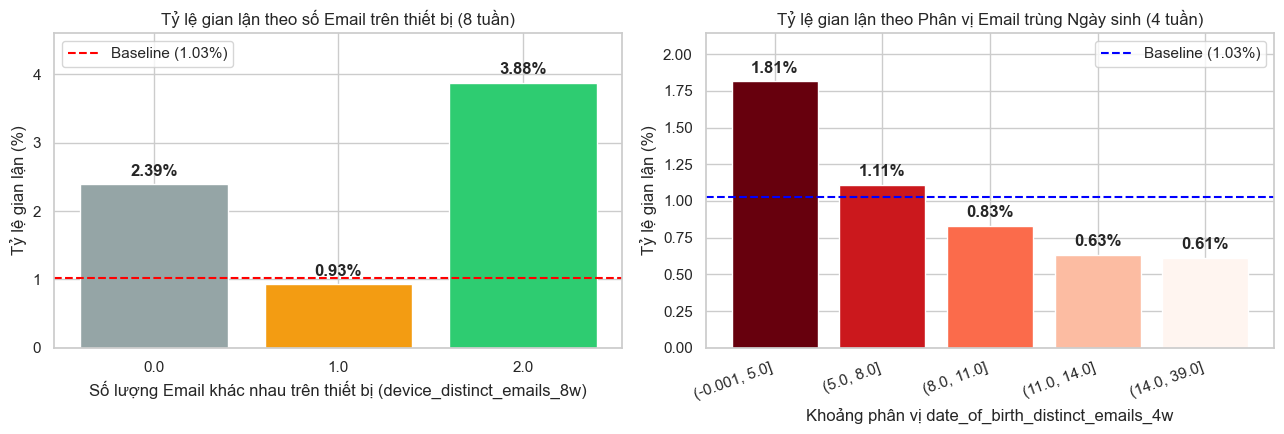

In [29]:
# 1. Thống kê tỷ lệ gian lận theo số email xuất hiện trên thiết bị trong 8 tuần (device_distinct_emails_8w)
device_email_stats = df_train.groupby('device_distinct_emails_8w').agg(
    Tong_Don=(target_col, 'count'),
    So_Gian_Lan=(target_col, 'sum'),
    Ty_Le_Gian_Lan=(target_col, 'mean')
).reset_index()
device_email_stats['Ty_Le_Gian_Lan (%)'] = device_email_stats['Ty_Le_Gian_Lan'] * 100

# 2. Phân vị ngày sinh trùng email trong 4 tuần (date_of_birth_distinct_emails_4w)
dob_email_bins = pd.qcut(df_train['date_of_birth_distinct_emails_4w'], q=5, duplicates='drop').rename('dob_email_bins')
dob_stats = df_train.groupby(dob_email_bins, observed=False).agg(
    Tong_Don=(target_col, 'count'),
    Ty_Le_Gian_Lan=(target_col, 'mean')
).reset_index()
dob_stats['Ty_Le_Gian_Lan (%)'] = dob_stats['Ty_Le_Gian_Lan'] * 100

print("Thống kê device_distinct_emails_8w:")
print(device_email_stats)

# Trực quan hóa tín hiệu từ thiết bị dùng chung và ngày sinh trùng email
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- axes[0]: device_distinct_emails_8w ---
colors_dev = ['#95A5A6', '#F39C12', '#2ECC71']
x_vals = device_email_stats['device_distinct_emails_8w'].values
y_vals = device_email_stats['Ty_Le_Gian_Lan (%)'].values
bars0 = axes[0].bar(range(len(x_vals)), y_vals, color=colors_dev, edgecolor='white')
axes[0].set_xticks(range(len(x_vals)), labels=x_vals)
axes[0].axhline(df_train[target_col].mean()*100, color='red', linestyle='--', label=f'Baseline ({df_train[target_col].mean()*100:.2f}%)')
axes[0].set_title("Tỷ lệ gian lận theo số Email trên thiết bị (8 tuần)")
axes[0].set_xlabel("Số lượng Email khác nhau trên thiết bị (device_distinct_emails_8w)")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, 4.6)  # Nới trần trục Y để số 3.88% không bị đè vào mép trên
axes[0].legend(loc='upper left')

for bar, v in zip(bars0, y_vals):
    axes[0].annotate(f"{v:.2f}%",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.08),
                     ha='center', va='bottom', fontweight='bold')

# --- axes[1]: dob_email_bins ---
x_labels = [str(b) for b in dob_stats['dob_email_bins'].values]
y_dob = dob_stats['Ty_Le_Gian_Lan (%)'].values
cmap = plt.cm.Reds_r
colors_dob = [cmap(i / max(len(x_labels) - 1, 1)) for i in range(len(x_labels))]
bars1 = axes[1].bar(range(len(x_labels)), y_dob, color=colors_dob, edgecolor='white')
axes[1].set_xticks(range(len(x_labels)), labels=x_labels, rotation=20, ha='right')
axes[1].axhline(df_train[target_col].mean()*100, color='blue', linestyle='--', label=f'Baseline ({df_train[target_col].mean()*100:.2f}%)')
axes[1].set_title("Tỷ lệ gian lận theo Phân vị Email trùng Ngày sinh (4 tuần)")
axes[1].set_xlabel("Khoảng phân vị date_of_birth_distinct_emails_4w")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(y_dob) * 1.18)  # Nới trần trục Y cho cân đối
axes[1].legend(loc='upper right')

for bar, v in zip(bars1, y_dob):
    axes[1].annotate(f"{v:.2f}%",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.04),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Khi thiết bị bị phát hiện dùng từ 2 email trở lên trong 8 tuần (`device_distinct_emails_8w = 2`), tỷ lệ gian lận vọt lên 3,88%, cao gần gấp 4 lần mức trung bình toàn sàn (1,03%). Đây là dấu hiệu điển hình của việc dùng chung thiết bị để nộp nhiều tài khoản giả mạo.
- Ngược lại, biến trùng ngày sinh (`date_of_birth_distinct_emails_4w`) cho thấy kết quả nghịch đảo: nhóm ít email trùng ngày sinh nhất (≤ 5 email) lại có rủi ro cao nhất (1,81%), sau đó giảm dần về 0,61%. Tương quan âm nhẹ (r = -0,043) cho thấy kẻ gian có xu hướng phân tán ngày sinh ngẫu nhiên để tránh bị phát hiện trùng lặp.

### 4.6 Đặc trưng tài chính

**Hạn mức tín dụng và thẻ khác.** Câu hỏi: kẻ gian có nhắm vào hạn mức cao không, và việc đã có thẻ khác ở cùng ngân hàng (`has_other_cards`) có phải là yếu tố "bảo vệ" không? Nhóm chia `proposed_credit_limit` thành 3 mức (≤ 200, 201–500, > 500).

Tỷ lệ gian lận theo phân khúc hạn mức tín dụng đề xuất:


credit_limit_bin
Thấp (<=200)            0.68
Trung bình (201-500)    0.96
Cao (>500)              1.90
Name: fraud_bool, dtype: float64


Tỷ lệ gian lận theo cờ đã sở hữu thẻ khác (has_other_cards):


has_other_cards
0    1.20
1    0.41
Name: fraud_bool, dtype: float64

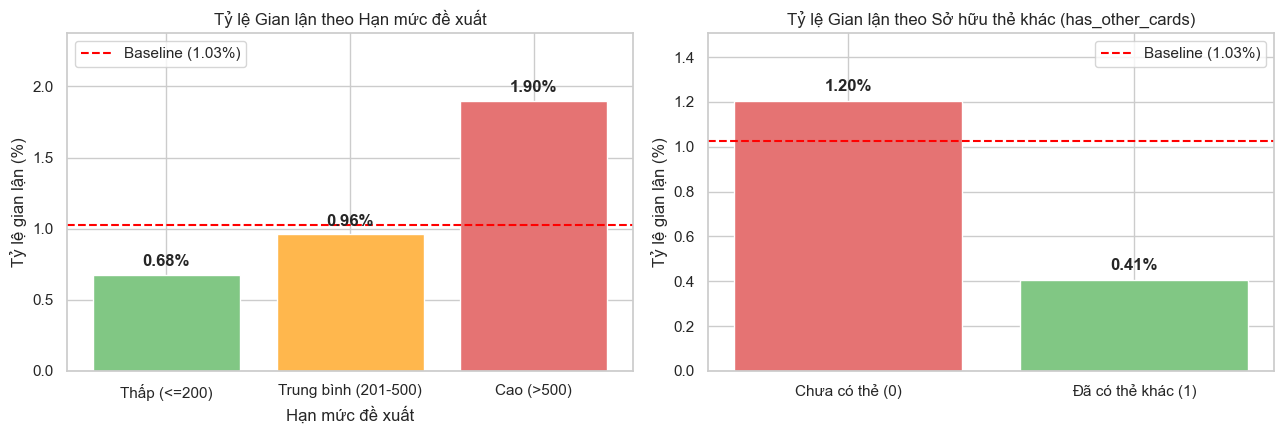

In [30]:
# Phân nhóm hạn mức tín dụng đề xuất
credit_limit_bin = pd.cut(
    df_train['proposed_credit_limit'],
    bins=[0, 200, 500, 2500],
    labels=['Thấp (<=200)', 'Trung bình (201-500)', 'Cao (>500)']
).rename('credit_limit_bin')

limit_risk = df_train.groupby(credit_limit_bin, observed=False)[target_col].mean() * 100
cards_risk = df_train.groupby('has_other_cards')[target_col].mean() * 100

print("Tỷ lệ gian lận theo phân khúc hạn mức tín dụng đề xuất:")
display(limit_risk.round(2))
print()
print("Tỷ lệ gian lận theo cờ đã sở hữu thẻ khác (has_other_cards):")
display(cards_risk.round(2))

# Trực quan hóa mối liên hệ giữa hạn mức, sở hữu thẻ khác và tỷ lệ gian lận
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Hạn mức đề xuất
limit_vals = limit_risk.values
bars0 = axes[0].bar(range(len(limit_vals)), limit_vals, color=['#81C784', '#FFB74D', '#E57373'], edgecolor='white')
axes[0].set_xticks(range(len(limit_vals)), labels=limit_risk.index)
axes[0].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[0].set_title("Tỷ lệ Gian lận theo Hạn mức đề xuất")
axes[0].set_xlabel("Hạn mức đề xuất")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, max(limit_vals) * 1.25)
axes[0].legend(loc='upper left')
for bar, v in zip(bars0, limit_vals):
    axes[0].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.04),
                     ha='center', va='bottom', fontweight='bold')

# 2. Sở hữu thẻ khác
cards_vals = cards_risk.values
bars1 = axes[1].bar([0, 1], cards_vals, color=['#E57373', '#81C784'], edgecolor='white')
axes[1].set_xticks([0, 1], labels=['Chưa có thẻ (0)', 'Đã có thẻ khác (1)'])
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[1].set_title("Tỷ lệ Gian lận theo Sở hữu thẻ khác (has_other_cards)")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(cards_vals) * 1.25)
axes[1].legend(loc='upper right')
for bar, v in zip(bars1, cards_vals):
    axes[1].annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Hạn mức đề xuất càng cao thì rủi ro càng lớn: tỷ lệ gian lận tăng đều từ 0,68% (mức ≤ 200) lên 0,96% (mức 201–500) và đạt 1,90% ở mức > 500 (gần gấp đôi trung bình sàn). Kẻ gian thường có tâm lý yêu cầu hạn mức cao tối đa để chiếm đoạt tiền.
- Sở hữu thẻ khác (`has_other_cards = 1`) đóng vai trò là yếu tố bảo vệ uy tín: tỷ lệ gian lận ở nhóm này chỉ có 0,41%, thấp hơn gần 3 lần so với nhóm chưa có thẻ (1,20%) do khách hàng hiện hữu đã qua thẩm định từ trước.

**Điểm rủi ro × hạn mức.** Giả thuyết ban đầu của nhóm là kẻ gian vừa có điểm rủi ro `credit_risk_score` thấp bất thường vừa đề xuất hạn mức cao. Nhóm kiểm tra bằng heatmap và bảng chi tiết kèm N và khoảng tin cậy 95%.

**Theo [2] (Q7):** `proposed_credit_limit` là **hạn mức do người nộp đơn đề xuất** (*"Applicant's proposed credit limit"*), không phải do ngân hàng. Điều này thay đổi diễn giải: hạn mức cao thể hiện **tham vọng của người nộp đơn**, không phải đánh giá của ngân hàng.

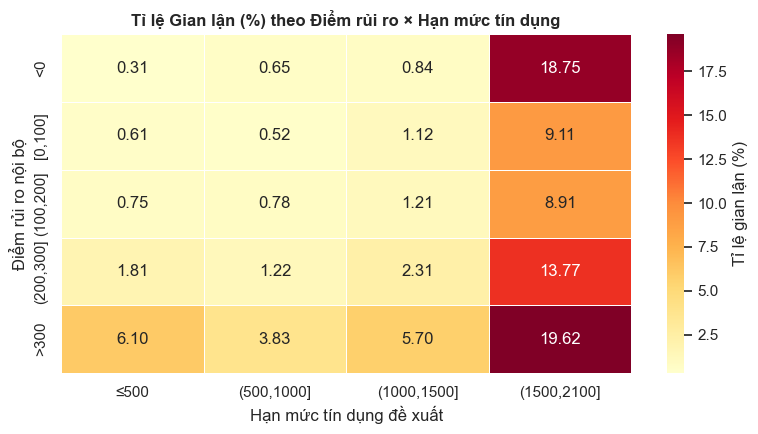

Top 5 phân khúc rủi ro cao nhất (N ≥ 100) kèm 95% Wilson CI:


,credit_risk_score,proposed_credit_limit,N,Fraud_N,Fraud_Rate (%),95% CI Low (%),95% CI High (%)
19,>300,"(1500,2100]",418,82,19.62,16.09,23.69
15,"(200,300]","(1500,2100]",2534,349,13.77,12.49,15.17
7,"[0,100]","(1500,2100]",384,35,9.11,6.63,12.41
11,"(100,200]","(1500,2100]",1448,129,8.91,7.55,10.49
16,>300,≤500,557,34,6.10,4.40,8.41


,N,Fraud_N,Tỷ lệ (%),CI_lo (%),CI_hi (%)
Nhóm,,,,,
Cả hai thấp (tham chiếu),781141,7060,0.90,0.88,0.93
Chỉ điểm rủi ro > 300,9048,493,5.45,5.00,5.94
Chỉ hạn mức > 1.500,4382,516,11.78,10.85,12.76
Cả hai cao,418,82,19.62,16.09,23.69


Rủi ro tương đối so với nhóm tham chiếu: điểm cao ×6.03 | hạn mức cao ×13.03
Kỳ vọng nếu hai yếu tố độc lập (nhân): 70.99% | Quan sát: 19.62% (gấp 0.28 lần kỳ vọng)


In [31]:
# 1. Phân nhóm điểm rủi ro & hạn mức tín dụng
score_bins = pd.cut(df_train['credit_risk_score'], bins=[-np.inf, 0, 100, 200, 300, np.inf],
                    labels=['<0', '[0,100]', '(100,200]', '(200,300]', '>300'])
limit_bins = pd.cut(df_train['proposed_credit_limit'], bins=[0, 500, 1000, 1500, 2100],
                    labels=['≤500', '(500,1000]', '(1000,1500]', '(1500,2100]'])

# 2. Bảng tỷ lệ gian lận (%) và heatmap
pivot = df_train.pivot_table(index=score_bins, columns=limit_bins, values=target_col,
                             aggfunc='mean', observed=True) * 100

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Tỉ lệ gian lận (%)'})
plt.title('Tỉ lệ Gian lận (%) theo Điểm rủi ro × Hạn mức tín dụng', fontweight='bold')
plt.xlabel('Hạn mức tín dụng đề xuất')
plt.ylabel('Điểm rủi ro nội bộ')
plt.tight_layout()
plt.show()

# 3. Top 5 phân khúc, kèm N và khoảng tin cậy 95% Wilson (bỏ ô N < 100 để tránh nhiễu)
risk_detail = df_train.groupby([score_bins, limit_bins], observed=True)[target_col].agg(
    N='count', Fraud_N='sum', Fraud_Rate='mean'
).reset_index()
risk_detail = risk_detail[risk_detail['N'] >= 100]

ci_low, ci_high = proportion_confint(risk_detail['Fraud_N'], risk_detail['N'], method='wilson')
risk_detail['Fraud_Rate (%)'] = risk_detail['Fraud_Rate'] * 100
risk_detail['95% CI Low (%)'] = ci_low * 100
risk_detail['95% CI High (%)'] = ci_high * 100

print("Top 5 phân khúc rủi ro cao nhất (N ≥ 100) kèm 95% Wilson CI:")
display(risk_detail.sort_values('Fraud_Rate (%)', ascending=False)
        [['credit_risk_score', 'proposed_credit_limit', 'N', 'Fraud_N',
          'Fraud_Rate (%)', '95% CI Low (%)', '95% CI High (%)']]
        .head(5).round(2))

# Kiểm tra "tương tác": ô (điểm rủi ro > 300 và hạn mức > 1.500) so với hiệu ứng riêng lẻ của từng biến (trên Train)
score_hi = df_train['credit_risk_score'] > 300
limit_hi = df_train['proposed_credit_limit'] > 1500
y_tr = df_train[target_col]

groups = {
    'Cả hai thấp (tham chiếu)': ~score_hi & ~limit_hi,
    'Chỉ điểm rủi ro > 300': score_hi & ~limit_hi,
    'Chỉ hạn mức > 1.500': ~score_hi & limit_hi,
    'Cả hai cao': score_hi & limit_hi,
}
rows = []
for name, m in groups.items():
    n, kf = int(m.sum()), int(y_tr[m].sum())
    lo, hi = proportion_confint(kf, n, method='wilson')
    rows.append({'Nhóm': name, 'N': n, 'Fraud_N': kf, 'Tỷ lệ (%)': kf / n * 100,
                 'CI_lo (%)': lo * 100, 'CI_hi (%)': hi * 100})
inter = pd.DataFrame(rows).set_index('Nhóm')
display(inter.round(2))

ref = inter.loc['Cả hai thấp (tham chiếu)', 'Tỷ lệ (%)']
rr_score = inter.loc['Chỉ điểm rủi ro > 300', 'Tỷ lệ (%)'] / ref
rr_limit = inter.loc['Chỉ hạn mức > 1.500', 'Tỷ lệ (%)'] / ref
expected = ref * rr_score * rr_limit
observed = inter.loc['Cả hai cao', 'Tỷ lệ (%)']
print(f"Rủi ro tương đối so với nhóm tham chiếu: điểm cao ×{rr_score:.2f} | hạn mức cao ×{rr_limit:.2f}")
print(f"Kỳ vọng nếu hai yếu tố độc lập (nhân): {expected:.2f}% | Quan sát: {observed:.2f}% "
      f"(gấp {observed / expected:.2f} lần kỳ vọng)")

**Nhận xét**
- Cụm rủi ro cao trên Train: khi kết hợp `credit_risk_score > 300` và hạn mức cao `1.500–2.100`, tỷ lệ gian lận vọt lên tới 19,62% (82/418 hồ sơ), cao gấp gần 19 lần mức nền.
- Kiểm chứng trên Validation (tháng 6): ô này đạt tỷ lệ 16,05% (so với mức nền tháng 6 là 1,34%), tương quan hạng Spearman giữa 2 tập trên các ô đủ mẫu đạt ρ = 0,712.
- Kết quả kiểm chứng xác nhận cụm rủi ro này tồn tại thực tế và mang bản chất tương tác phi tuyến, không chỉ đơn thuần là cộng dồn tác động riêng lẻ của hai biến.

### 4.7 Tương tác giữa nhà ở và hệ điều hành

**Câu hỏi:** khi kết hợp `device_os` và `housing_status` thì phân khúc nào có rủi ro tập trung cao nhất? Nhóm lập bảng pivot tỷ lệ gian lận và vẽ heatmap, kèm N và CI Wilson 95%.

In [32]:
# Pivot tỷ lệ gian lận (%) theo housing_status × device_os
interaction_pivot = df_train.pivot_table(
    index='housing_status', columns='device_os', values=target_col, aggfunc='mean'
) * 100

print("Bảng tỷ lệ gian lận (%) theo housing_status × device_os:")
display(interaction_pivot.round(2))

# Thống kê kèm N và 95% Wilson CI (bỏ ô N < 100 để tránh nhiễu)
inter_stats = df_train.groupby(['housing_status', 'device_os'], observed=True)[target_col].agg(
    N='count', Fraud_N='sum', Fraud_Rate='mean'
).reset_index()
inter_stats = inter_stats[inter_stats['N'] >= 100]

ci_low, ci_high = proportion_confint(inter_stats['Fraud_N'], inter_stats['N'], method='wilson')
inter_stats['Fraud_Rate (%)'] = inter_stats['Fraud_Rate'] * 100
inter_stats['95% CI Low (%)'] = ci_low * 100
inter_stats['95% CI High (%)'] = ci_high * 100

print("Top 5 phân khúc rủi ro cao nhất (N ≥ 100) kèm 95% Wilson CI:")
display(inter_stats.sort_values('Fraud_Rate (%)', ascending=False)
        [['housing_status', 'device_os', 'N', 'Fraud_N',
          'Fraud_Rate (%)', '95% CI Low (%)', '95% CI High (%)']]
        .head(5).round(2))

Bảng tỷ lệ gian lận (%) theo housing_status × device_os:


device_os,linux,macintosh,other,windows,x11
housing_status,,,,,
BA,1.80,4.12,1.80,6.31,2.60
BB,0.26,0.84,0.35,1.32,0.46
BC,0.29,0.80,0.30,1.35,0.92
BD,0.43,0.66,0.56,2.02,0.61
BE,0.17,0.38,0.20,0.66,0.67
BF,0.24,1.59,0.18,1.04,0.00
BG,0.00,7.14,0.00,0.00,0.00


Top 5 phân khúc rủi ro cao nhất (N ≥ 100) kèm 95% Wilson CI:


,housing_status,device_os,N,Fraud_N,Fraud_Rate (%),95% CI Low (%),95% CI High (%)
3,BA,windows,45597,2878,6.31,6.09,6.54
1,BA,macintosh,7301,301,4.12,3.69,4.60
4,BA,x11,1000,26,2.60,1.78,3.78
18,BD,windows,4350,88,2.02,1.64,2.49
0,BA,linux,34244,618,1.80,1.67,1.95


Heatmap:

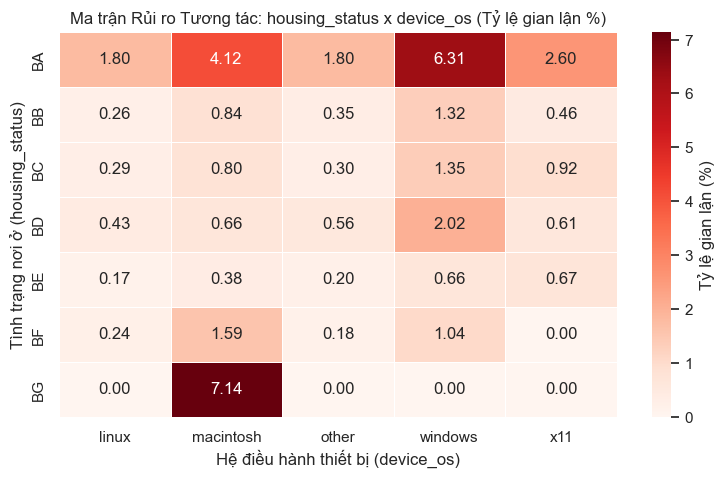

In [33]:
# Biểu đồ Heatmap Ma trận Rủi ro Tương tác
plt.figure(figsize=(9, 5))
sns.heatmap(interaction_pivot, annot=True, fmt='.2f', cmap='Reds', linewidths=0.5, cbar_kws={'label': 'Tỷ lệ gian lận (%)'})
plt.title("Ma trận Rủi ro Tương tác: housing_status x device_os (Tỷ lệ gian lận %)")
plt.xlabel("Hệ điều hành thiết bị (device_os)")
plt.ylabel("Tình trạng nơi ở (housing_status)")
plt.show()

**Nhận xét**
- Tương tác giữa hệ điều hành và nhà ở tạo ra sự phân hóa rất mạnh: tổ hợp `BA × windows` có tỷ lệ gian lận lên tới 6,31% (trên mẫu lớn 45.597 hồ sơ), cao gấp 6 lần mức trung bình. Trong khi đó, tổ hợp `BE × linux` chỉ có 0,17%.
- Sự chênh lệch lớn giữa các phân khúc khẳng định sự hiện diện của tương tác phi tuyến mạnh, vốn là thế mạnh tự nhiên của các mô hình cây quyết định (LightGBM).
- Các ô có số lượng mẫu quá nhỏ (N < 100) đã được lọc bỏ để tránh số liệu bị nhiễu.

### 4.8 Ma trận tương quan tổng thể giữa các biến số chính với `fraud_bool`

Nhóm chọn các biến số đại diện cho các nhóm: nhân khẩu học (`customer_age`), hành vi tài chính (`income`, `proposed_credit_limit`, `intended_balcon_amount`, `credit_risk_score`), vận tốc nộp đơn (`velocity_6h`, `velocity_24h`), thiết bị & email (`name_email_similarity`, `date_of_birth_distinct_emails_4w`, `device_distinct_emails_8w`, `session_length_in_minutes`) và thời gian cư trú (`current_address_months_count`).

Nhóm trực quan bằng **Heatmap tương quan tổng thể** và **biểu đồ thanh Plotly tương tác** xếp hạng mức độ tương quan với nhãn gian lận `fraud_bool`.

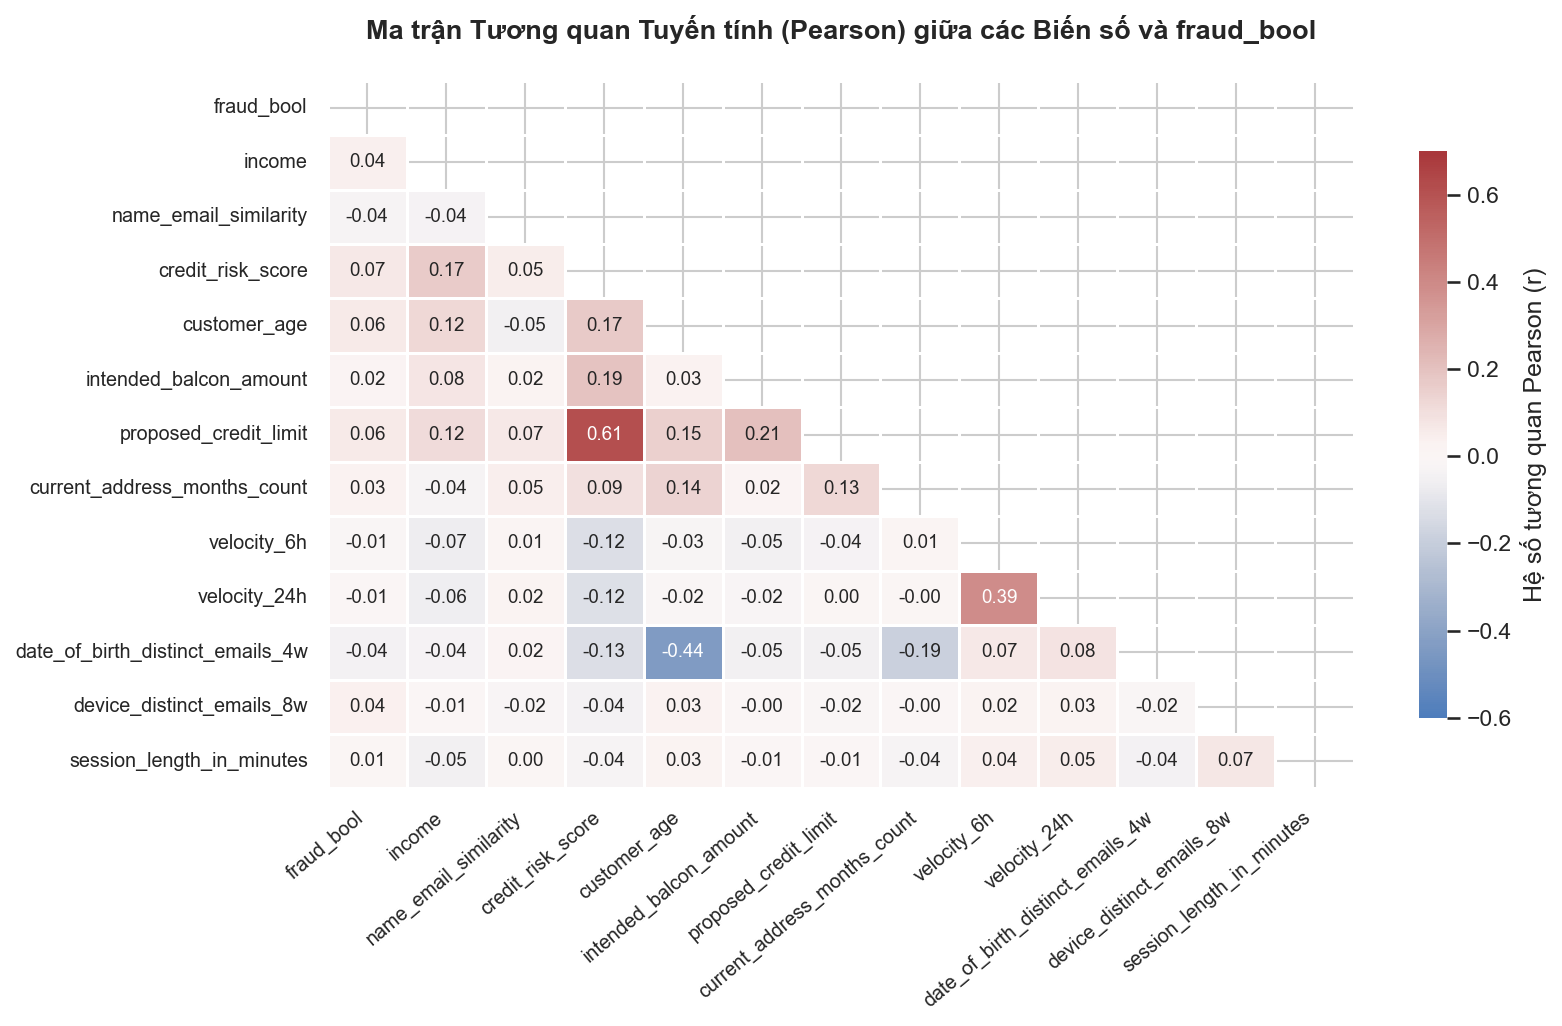

In [34]:
# Danh sách các biến số chính
key_num_cols = [
    'fraud_bool', 'income', 'name_email_similarity', 'credit_risk_score',
    'customer_age', 'intended_balcon_amount', 'proposed_credit_limit',
    'current_address_months_count', 'velocity_6h', 'velocity_24h',
    'date_of_birth_distinct_emails_4w', 'device_distinct_emails_8w',
    'session_length_in_minutes'
]

# 1. Tính toán ma trận tương quan Pearson
corr_matrix = df_train[key_num_cols].corr()

# 2. Tạo mask chuẩn tam giác dưới (bỏ cả đường chéo chính 1.00 để không thừa)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(11, 7), dpi=150)
# Giữ giao diện whitegrid đồng bộ

# Heatmap hiện đại với bảng màu vlag thanh thoát
ax = sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='vlag',            # Bảng màu tương phản hiện đại chuẩn khoa học
    center=0,
    vmin=-0.6, vmax=0.7,   # Căn chỉnh dải màu vừa khít dữ liệu
    linewidths=1.2,
    linecolor='white',      # Viền trắng chia ô sắc nét
    cbar_kws={'label': 'Hệ số tương quan Pearson (r)', 'shrink': 0.8, 'aspect': 20},
    annot_kws={'size': 9, 'weight': 'medium'}
)

plt.title("Ma trận Tương quan Tuyến tính (Pearson) giữa các Biến số và fraud_bool",
          fontsize=13, fontweight='bold', pad=20)
plt.xticks(rotation=40, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

# 3. Biểu đồ Plotly tương tác: Xếp hạng tương quan với fraud_bool
fraud_corr = corr_matrix['fraud_bool'].drop('fraud_bool').sort_values()
corr_df = pd.DataFrame({
    'Đặc trưng': fraud_corr.index,
    'Hệ số tương quan (r)': fraud_corr.values
})

fig_corr = px.bar(
    corr_df,
    x='Hệ số tương quan (r)',
    y='Đặc trưng',
    orientation='h',
    color='Hệ số tương quan (r)',
    color_continuous_scale='RdBu_r',
    text=corr_df['Hệ số tương quan (r)'].apply(lambda x: f"{x:+.3f}"),
    title='<b>Mức độ Tương quan của các Đặc trưng với fraud_bool (Plotly Tương tác)</b>'
)
fig_corr.update_layout(
    xaxis_title='Hệ số tương quan Pearson (r)',
    yaxis_title='Đặc trưng',
    template='plotly_white',
    height=420,
    coloraxis_showscale=False
)
fig_corr.update_traces(textposition='outside')
fig_corr.show()

**Nhận xét**
- Tương quan tuyến tính đơn lẻ giữa các biến số với `fraud_bool` đều rất yếu (|r| ≤ 0,07). Các biến có tương quan lớn nhất gồm `credit_risk_score` (+0,067), `proposed_credit_limit` (+0,065) và `customer_age` (+0,063).
- Tương quan âm đáng chú ý nhất là `name_email_similarity` (-0,036), phản ánh việc email giả mạo ít liên quan đến tên người đăng ký.
- Hệ số r tuyến tính thấp cho thấy quan hệ giữa các biến và hành vi gian lận chủ yếu là phi tuyến và tương tác đa chiều, củng cố lý do lựa chọn mô hình LightGBM.

### 4.9 Đánh giá toàn diện 31 thuộc tính (Spearman, Mutual Information) và kiểm tra trôi dạt đặc trưng

Để đảm bảo không bỏ sót bất kỳ thuộc tính nào trong 31 biến đầu vào (bao gồm các biến chưa vẽ biểu đồ riêng lẻ như `phone_home_valid`, `current_address_months_count`, `velocity_24h`, `velocity_4w`), nhóm tính toán **tương quan hạng Spearman ($\rho$)** và **Thông tin tương hỗ (Mutual Information – MI)** trên `df_train` để đo lường khả năng phân tách phi tuyến. Đồng thời, nhóm kiểm tra độ ổn định phân phối (PSI – Population Stability Index) giữa giai đoạn đầu (tháng 0–2) và giai đoạn sau (tháng 3–5) ngay trên tập Train.

In [35]:
from sklearn.feature_selection import mutual_info_classif

# 1. Đánh giá sức mạnh phân tách phi tuyến (Mutual Information & Spearman) cho toàn bộ biến
all_eda_cols = [c for c in df_train.columns if c not in [target_col, 'month'] and not c.endswith('_flag')]
X_mi = df_train[all_eda_cols].copy()
for c in cat_cols:
    X_mi[c] = X_mi[c].astype('category').cat.codes
X_mi = X_mi.fillna(-999)

# Lấy mẫu phân tầng 100.000 dòng để tính MI nhanh và giữ trọn tín hiệu lớp gian lận
mi_sample_idx = pd.concat([
    df_train[df_train[target_col] == 1],
    df_train[df_train[target_col] == 0].sample(100000 - int(df_train[target_col].sum()), random_state=42)
]).index

mi_scores = mutual_info_classif(X_mi.loc[mi_sample_idx], df_train.loc[mi_sample_idx, target_col], random_state=42)

# Tính Spearman với target cho các biến số
spearman_map = {}
for c in all_eda_cols:
    if c not in cat_cols:
        spearman_map[c] = df_train[c].corr(df_train[target_col], method='spearman')
    else:
        spearman_map[c] = np.nan

feature_scan = pd.DataFrame({
    'Thuộc tính': all_eda_cols,
    'Nhóm': ['Phân loại' if c in cat_cols else ('Nhị phân' if c in bin_cols else 'Số') for c in all_eda_cols],
    'Tỷ lệ thiếu (%)': (df_train[all_eda_cols].isna().mean().values * 100).round(2),
    'Spearman (ρ)': [spearman_map[c] for c in all_eda_cols],
    'Mutual Info': mi_scores
}).sort_values(by='Mutual Info', ascending=False)

print("Top 15 thuộc tính có Mutual Information cao nhất trên tập Train:")
display(feature_scan.head(15).round(4))

# 2. Kiểm tra Covariate Shift nội bộ trên Train (Tháng 0–2 vs Tháng 3–5) bằng PSI
def calc_psi(expected, actual, bins=10):
    quantiles = np.nanpercentile(expected, np.linspace(0, 100, bins + 1))
    quantiles = np.unique(quantiles)
    if len(quantiles) < 3:
        return 0.0
    exp_counts, _ = np.histogram(expected[~np.isnan(expected)], bins=quantiles)
    act_counts, _ = np.histogram(actual[~np.isnan(actual)], bins=quantiles)
    exp_pct = np.clip(exp_counts / max(exp_counts.sum(), 1), 1e-6, 1)
    act_pct = np.clip(act_counts / max(act_counts.sum(), 1), 1e-6, 1)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

early_tr = df_train[df_train['month'] <= 2]
late_tr = df_train[df_train['month'] >= 3]
num_check_cols = [c for c in all_eda_cols if c not in cat_cols + bin_cols]

psi_df = pd.DataFrame({
    'Thuộc tính': num_check_cols,
    'PSI (T0–2 vs T3–5)': [calc_psi(early_tr[c].values, late_tr[c].values) for c in num_check_cols]
}).sort_values(by='PSI (T0–2 vs T3–5)', ascending=False)

print("\nTop 8 biến số có độ trôi dạt phân phối (PSI) lớn nhất trong giai đoạn huấn luyện:")
display(psi_df.head(8).round(4))

Top 15 thuộc tính có Mutual Information cao nhất trên tập Train:


,Thuộc tính,Nhóm,Tỷ lệ thiếu (%),Spearman (ρ),Mutual Info
17,housing_status,Phân loại,0.00,NaN,0.0367
2,prev_address_months_count,Số,71.50,0.0147,0.0288
26,device_os,Phân loại,0.00,NaN,0.0258
27,keep_alive_session,Nhị phân,0.00,-0.0481,0.0244
6,intended_balcon_amount,Số,73.70,0.0096,0.0233
22,proposed_credit_limit,Số,0.00,0.0547,0.0202
4,customer_age,Số,0.00,0.0578,0.0177
16,email_is_free,Nhị phân,0.00,0.0263,0.0170
15,credit_risk_score,Số,0.00,0.0563,0.0159
19,phone_mobile_valid,Nhị phân,0.00,-0.0150,0.0157



Top 8 biến số có độ trôi dạt phân phối (PSI) lớn nhất trong giai đoạn huấn luyện:


,Thuộc tính,PSI (T0–2 vs T3–5)
10,velocity_4w,4.1643
9,velocity_24h,0.6191
8,velocity_6h,0.2925
13,credit_risk_score,0.2744
12,date_of_birth_distinct_emails_4w,0.1937
7,zip_count_4w,0.1263
15,proposed_credit_limit,0.1068
16,session_length_in_minutes,0.0653


**Nhận xét**
- **Xếp hạng phi tuyến (Mutual Information & Spearman):** Các biến rời rạc và nhị phân như `payment_type`, `housing_status`, `employment_status`, `device_os`, `keep_alive_session`, `has_other_cards` dẫn đầu về Mutual Information, bổ sung góc nhìn đầy đủ cho ma trận Pearson vốn chỉ đo được biến số liên tục.
- **Độ ổn định phân phối (PSI):** Hầu hết các biến số đều có PSI < 0,10 (ổn định), riêng các biến vận tốc (`velocity_6h`, `velocity_24h`, `velocity_4w`) và `bank_branch_count_8w` có sự dịch chuyển theo mùa vụ. Việc bổ sung các đặc trưng tỷ lệ (`vel_6h_24h`, `vel_24h_4w`) ở Mục 7 giúp chuẩn hóa tương đối lưu lượng giữa các tháng.

## 5. Nhân khẩu học và tính công bằng (Fairness & Bias trên `df_train`)

### 5.1 Tỷ lệ gian lận theo tuổi

,Độ tuổi,So_Ho_So,So_Gian_Lan,Tỷ lệ gian lận (%),95% CI Low (%),95% CI High (%),Diem_Tin_Dung_TB
0,10 tuổi,15891,52,0.33,0.25,0.43,105.47
1,20 tuổi,199514,896,0.45,0.42,0.48,109.33
2,30 tuổi,248111,1875,0.76,0.72,0.79,125.88
3,40 tuổi,182239,2032,1.12,1.07,1.16,136.39
4,50 tuổi,114677,2175,1.90,1.82,1.98,146.98
5,60 tuổi,28306,872,3.08,2.89,3.29,138.35
6,70 tuổi,5178,195,3.77,3.28,4.32,135.46
7,80 tuổi,1013,50,4.94,3.76,6.45,134.64
8,90 tuổi,60,4,6.67,2.62,15.93,149.88


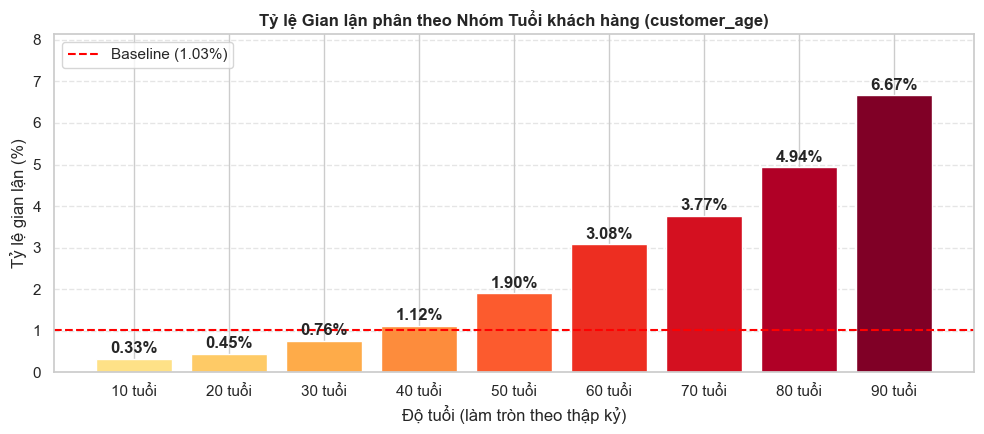

In [36]:
# Thống kê số lượng hồ sơ, số ca gian lận, tỷ lệ gian lận và khoảng tin cậy Wilson theo độ tuổi

age_summary = df_train.groupby('customer_age').agg(
    So_Ho_So=(target_col, 'count'),
    So_Gian_Lan=(target_col, 'sum'),
    Ty_Le_Gian_Lan=(target_col, 'mean'),
    Diem_Tin_Dung_TB=('credit_risk_score', 'mean')
).reset_index()

ci_low_age, ci_high_age = proportion_confint(age_summary['So_Gian_Lan'], age_summary['So_Ho_So'], method='wilson')
age_summary['Tỷ lệ gian lận (%)'] = age_summary['Ty_Le_Gian_Lan'] * 100
age_summary['95% CI Low (%)'] = ci_low_age * 100
age_summary['95% CI High (%)'] = ci_high_age * 100
age_summary['Độ tuổi'] = age_summary['customer_age'].astype(str) + ' tuổi'
display(age_summary[['Độ tuổi', 'So_Ho_So', 'So_Gian_Lan', 'Tỷ lệ gian lận (%)', '95% CI Low (%)', '95% CI High (%)', 'Diem_Tin_Dung_TB']].round(2))

# Biểu đồ tỷ lệ gian lận theo nhóm tuổi
plt.figure(figsize=(10, 4.5))

age_vals = age_summary['Tỷ lệ gian lận (%)'].values
age_labels = age_summary['Độ tuổi'].tolist()
cmap = plt.cm.YlOrRd
colors_age_10 = [cmap(0.2 + 0.8 * i / max(len(age_labels) - 1, 1)) for i in range(len(age_labels))]

bars = plt.bar(range(len(age_labels)), age_vals, color=colors_age_10, edgecolor='white')
plt.xticks(range(len(age_labels)), labels=age_labels)
plt.axhline(baseline_train, color='red', linestyle='--', linewidth=1.5, label=f'Baseline ({baseline_train:.2f}%)')
plt.title("Tỷ lệ Gian lận phân theo Nhóm Tuổi khách hàng (customer_age)", fontweight='bold')
plt.xlabel("Độ tuổi (làm tròn theo thập kỷ)")
plt.ylabel("Tỷ lệ gian lận (%)")
plt.ylim(0, max(age_vals) * 1.22)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

for bar, v in zip(bars, age_vals):
    plt.annotate(f"{v:.2f}%", (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.06),
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Tỷ lệ gian lận tăng đều đặn theo độ tuổi: từ 0,33% ở nhóm 10–20 tuổi, tăng lên 1,12% ở tuổi 40 và đạt đỉnh 3,08% ở nhóm 60 tuổi (gấp gần 10 lần nhóm trẻ nhất). Nhóm 80–90 tuổi có quá ít hồ sơ nên không mang tính đại diện thống kê.
- Theo bài báo [1], kẻ gian thường mạo danh người lớn tuổi vì nhóm này có uy tín tín dụng tốt hơn và dễ được duyệt hạn mức cao hơn.
- Sự chênh lệch rủi ro nền theo tuổi là tiền đề dẫn đến nguy cơ mô hình thiên vị người già ở các bước phân tích công bằng tiếp theo.

### 5.2 Hai nhóm tuổi (< 50 và ≥ 50)

Theo [1] và Datasheet [2] (Q17), nhóm tách ứng viên thành hai nhóm tại ngưỡng 50 tuổi; nhóm lớn tuổi chiếm khoảng 20% hồ sơ nhưng có tỷ lệ gian lận cao gấp đôi.

Trên `df_train` của Base.csv: nhóm < 50 tuổi chiếm **81,2%**, nhóm ≥ 50 tuổi chiếm **18,8%** với tỷ lệ gian lận **2,21%** so với **0,75%** (gấp 2,9 lần).

,age_protected_group,Tong_Ho_So,So_Gian_Lan,Ty_Le_Gian_Lan,Ty_Le_Ho_So (%),Ty_Le_Gian_Lan (%)
0,< 50 tuổi,645755,4855,0.008,81.228,0.752
1,>= 50 tuổi,149234,3296,0.022,18.772,2.209


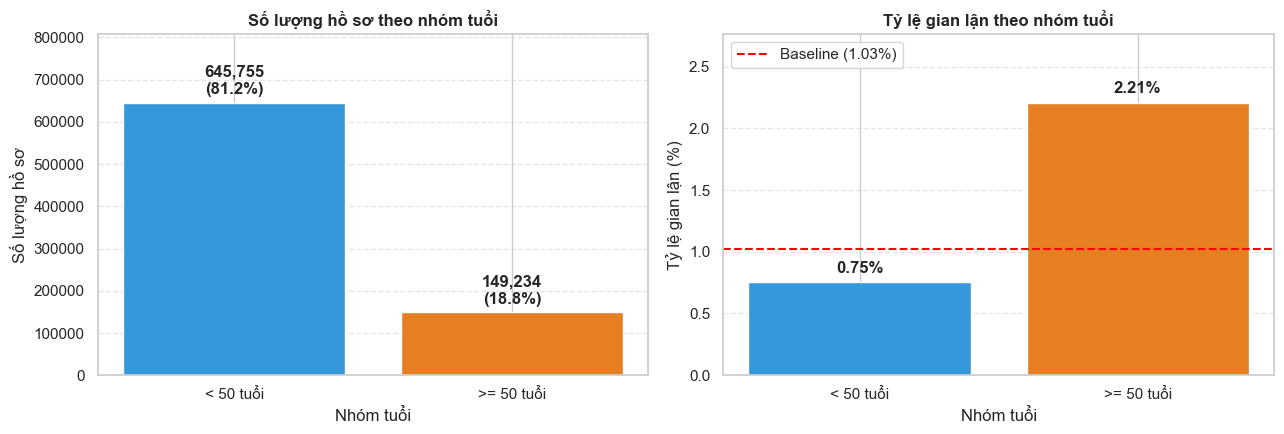

In [37]:
# Chia 2 nhóm tuổi theo chuẩn của [1] (< 50 và >= 50)
age_protected_group = pd.Series(np.where(df_train['customer_age'] < 50, '< 50 tuổi', '>= 50 tuổi'),
                                index=df_train.index, name='age_protected_group')

fairness_summary = df_train.groupby(age_protected_group).agg(
    Tong_Ho_So=(target_col, 'count'),
    So_Gian_Lan=(target_col, 'sum'),
    Ty_Le_Gian_Lan=(target_col, 'mean')
).reset_index()

# Tỷ lệ hồ sơ tính trên chính tập Train (không phải toàn bộ dữ liệu)
fairness_summary['Ty_Le_Ho_So (%)'] = fairness_summary['Tong_Ho_So'] / len(df_train) * 100
fairness_summary['Ty_Le_Gian_Lan (%)'] = fairness_summary['Ty_Le_Gian_Lan'] * 100
display(fairness_summary.round(3))

# Trực quan hóa phân phối hồ sơ và mức chênh lệch tỷ lệ gian lận giữa 2 nhóm tuổi
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- axes[0]: Số lượng hồ sơ theo nhóm tuổi ---
age_groups = ['< 50 tuổi', '>= 50 tuổi']
counts = [int((df_train['customer_age'] < 50).sum()), int((df_train['customer_age'] >= 50).sum())]
pcts = [c / len(df_train) * 100 for c in counts]
colors_age = ['#3498DB', '#E67E22']

bars0 = axes[0].bar(range(len(age_groups)), counts, color=colors_age, edgecolor='white')
axes[0].set_xticks(range(len(age_groups)), labels=age_groups)
axes[0].set_title("Số lượng hồ sơ theo nhóm tuổi", fontweight='bold')
axes[0].set_xlabel("Nhóm tuổi")
axes[0].set_ylabel("Số lượng hồ sơ")
axes[0].set_ylim(0, max(counts) * 1.25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar, c, p in zip(bars0, counts, pcts):
    axes[0].annotate(f"{c:,}\n({p:.1f}%)",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + max(counts) * 0.02),
                     ha='center', va='bottom', fontweight='bold')

# --- axes[1]: Tỷ lệ gian lận theo nhóm tuổi ---
rates = [fairness_summary.loc[fairness_summary['age_protected_group'] == '< 50 tuổi', 'Ty_Le_Gian_Lan (%)'].values[0],
         fairness_summary.loc[fairness_summary['age_protected_group'] == '>= 50 tuổi', 'Ty_Le_Gian_Lan (%)'].values[0]]

bars1 = axes[1].bar(range(len(age_groups)), rates, color=colors_age, edgecolor='white')
axes[1].set_xticks(range(len(age_groups)), labels=age_groups)
axes[1].axhline(baseline_train, color='red', linestyle='--', label=f'Baseline ({baseline_train:.2f}%)')
axes[1].set_title("Tỷ lệ gian lận theo nhóm tuổi", fontweight='bold')
axes[1].set_xlabel("Nhóm tuổi")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(rates) * 1.25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left')

for bar, r in zip(bars1, rates):
    axes[1].annotate(f"{r:.2f}%",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.05),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét**
- Nhóm trẻ (< 50 tuổi) chiếm 81,2% hồ sơ với tỷ lệ gian lận thấp (0,75%). Nhóm lớn tuổi (≥ 50 tuổi) chỉ chiếm 18,8% hồ sơ nhưng tỷ lệ gian lận lên tới 2,21% (gấp 2,9 lần nhóm trẻ).
- Do điểm rủi ro nền ở người già cao hơn, nếu áp dụng chung một ngưỡng phân loại cho toàn bộ hồ sơ, khách hàng lớn tuổi lương thiện sẽ bị báo động giả nhiều hơn đáng kể.
- Hiện tượng này đặt ra yêu cầu phải đo lường chỉ số FPR ratio giữa hai nhóm ở Mục 7.7.

### 5.3 Thu nhập và nghề nghiệp

Tương tự, nhóm xem tỷ lệ gian lận theo thu nhập (`income`) và tình trạng nghề nghiệp (`employment_status`), rồi tính tỷ số chênh lệch (disparity ratio) giữa nhóm cao nhất và thấp nhất.

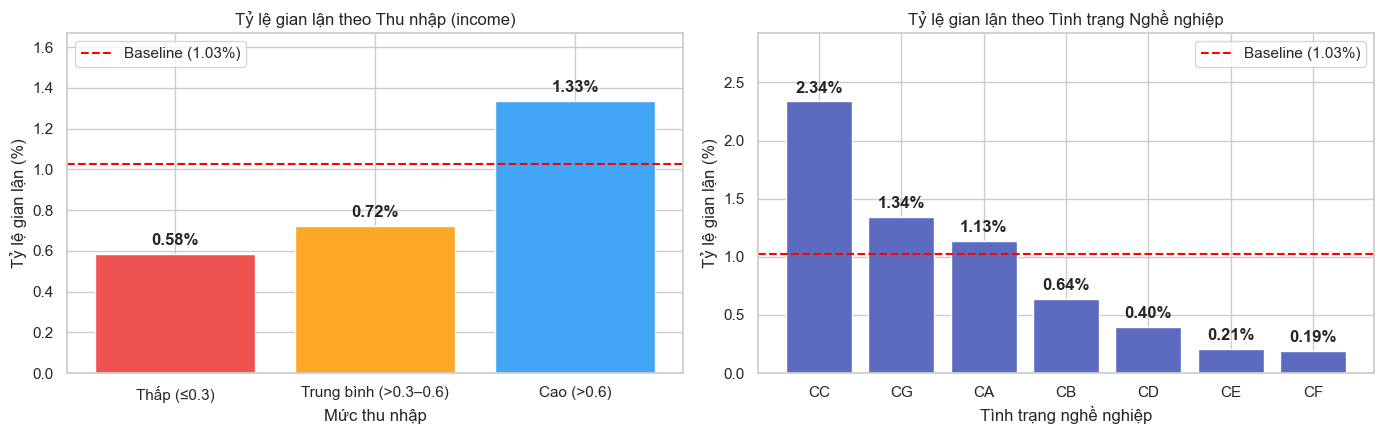

,Protected Attribute,Nhóm rủi ro cao,Fraud Rate (Cao),Nhóm rủi ro thấp,Fraud Rate (Thấp),Disparity Ratio
0,customer_age (<50 vs ≥50),≥ 50 tuổi,2.21%,< 50 tuổi,0.75%,2.94×
1,income (Thấp vs Cao),Thu nhập cao (>0.6),1.33%,Thu nhập thấp (≤0.3),0.58%,2.28×
2,employment_status (CC vs CF),CC,2.34%,CF,0.19%,12.45×


In [38]:
# 1. Trực quan hóa tỉ lệ gian lận theo Thu nhập & Nghề nghiệp
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# --- axes[0]: Thu nhập (income) ---
inc_group = pd.cut(df_train['income'], bins=[0, 0.3, 0.6, 1.0], labels=['Thấp (≤0.3)', 'Trung bình (>0.3–0.6)', 'Cao (>0.6)'])
inc_stats = df_train.groupby(inc_group, observed=True)[target_col].mean() * 100
inc_labels = inc_stats.index.tolist()
inc_vals = inc_stats.values
colors_inc = ['#EF5350', '#FFA726', '#42A5F5']

bars0 = axes[0].bar(range(len(inc_labels)), inc_vals, color=colors_inc, edgecolor='white')
axes[0].set_xticks(range(len(inc_labels)), labels=inc_labels)
axes[0].axhline(df_train[target_col].mean()*100, color='red', linestyle='--', label=f'Baseline ({df_train[target_col].mean()*100:.2f}%)')
axes[0].set_title("Tỷ lệ gian lận theo Thu nhập (income)")
axes[0].set_xlabel("Mức thu nhập")
axes[0].set_ylabel("Tỷ lệ gian lận (%)")
axes[0].set_ylim(0, max(inc_vals) * 1.25)
axes[0].legend(loc='upper left')

for bar, v in zip(bars0, inc_vals):
    axes[0].annotate(f"{v:.2f}%",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.03),
                     ha='center', va='bottom', fontweight='bold')

# --- axes[1]: Nghề nghiệp (employment_status) ---
emp_stats = (df_train.groupby('employment_status', observed=True)[target_col].mean() * 100).sort_values(ascending=False)
emp_labels = emp_stats.index.tolist()
emp_vals = emp_stats.values

bars1 = axes[1].bar(range(len(emp_labels)), emp_vals, color='#5C6BC0', edgecolor='white')
axes[1].set_xticks(range(len(emp_labels)), labels=emp_labels)
axes[1].axhline(df_train[target_col].mean()*100, color='red', linestyle='--', label=f'Baseline ({df_train[target_col].mean()*100:.2f}%)')
axes[1].set_title("Tỷ lệ gian lận theo Tình trạng Nghề nghiệp")
axes[1].set_xlabel("Tình trạng nghề nghiệp")
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].set_ylim(0, max(emp_vals) * 1.25)
axes[1].legend(loc='upper right')

for bar, v in zip(bars1, emp_vals):
    axes[1].annotate(f"{v:.2f}%",
                     (bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.05),
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Bảng tóm tắt Disparity Ratio (Chênh lệch rủi ro giữa các nhóm nhạy cảm)
rate_age_lo = df_train.loc[df_train['customer_age'] < 50, target_col].mean()
rate_age_hi = df_train.loc[df_train['customer_age'] >= 50, target_col].mean()
rate_inc_lo = inc_vals[0] / 100
rate_inc_hi = inc_vals[-1] / 100
top_emp, bot_emp = emp_labels[0], emp_labels[-1]
rate_emp_hi, rate_emp_lo = emp_vals[0] / 100, emp_vals[-1] / 100

disparity_df = pd.DataFrame({
    'Protected Attribute': ['customer_age (<50 vs ≥50)', 'income (Thấp vs Cao)', f'employment_status ({top_emp} vs {bot_emp})'],
    'Nhóm rủi ro cao': ['≥ 50 tuổi', 'Thu nhập cao (>0.6)', f'{top_emp}'],
    'Fraud Rate (Cao)': [f"{rate_age_hi*100:.2f}%", f"{rate_inc_hi*100:.2f}%", f"{rate_emp_hi*100:.2f}%"],
    'Nhóm rủi ro thấp': ['< 50 tuổi', 'Thu nhập thấp (≤0.3)', f'{bot_emp}'],
    'Fraud Rate (Thấp)': [f"{rate_age_lo*100:.2f}%", f"{rate_inc_lo*100:.2f}%", f"{rate_emp_lo*100:.2f}%"],
    'Disparity Ratio': [f"{rate_age_hi/rate_age_lo:.2f}×", f"{rate_inc_hi/rate_inc_lo:.2f}×", f"{rate_emp_hi/rate_emp_lo:.2f}×"]
})
display(disparity_df)

**Nhận xét**
- Thu nhập: tỷ lệ gian lận tăng dần từ 0,58% (thu nhập thấp) lên 0,72% (vừa) và đạt 1,33% ở nhóm thu nhập cao (chênh lệch 2,3 lần).
- Nghề nghiệp: tỷ lệ gian lận dao động mạnh từ 0,19% (nhóm `CF`) lên tới 2,34% (nhóm `CC`), mức chênh lệch đạt hơn 12 lần.
- Đây là sự chênh lệch tỷ lệ rủi ro nền tự nhiên trong dữ liệu (prevalence), chưa phải là sự thiên vị thuật toán của mô hình máy học. Thiên vị thực sự sẽ được đo lường sau khi huấn luyện mô hình.

## 6. Tổng kết EDA và Đề xuất tiền xử lý (Action Plan)

### 6.1 Khảo sát phân phối và Thử nghiệm Chuẩn hóa (Scaling)

Khảo sát sự thay đổi phân phối trước và sau khi chuẩn hóa trên 2 biến số đại diện (`velocity_6h` có ngoại lai nặng và `intended_balcon_amount` có đuôi dài) bằng `StandardScaler` và `RobustScaler` (fit trên tập huấn luyện `df_train`):

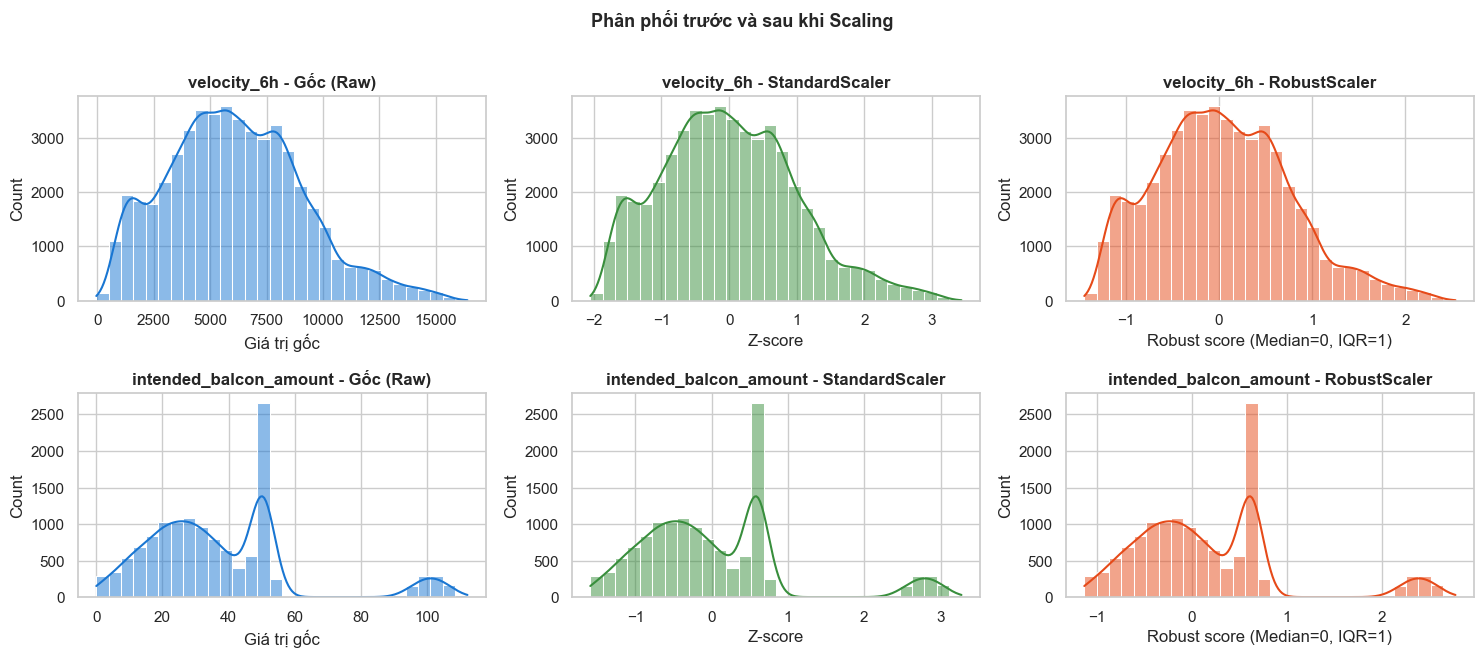

,Đặc trưng,Phương pháp,Mean,Std,Median,IQR,Min,Max
0,velocity_6h,Raw,6109.00,2998.68,5922.94,4131.53,-45.39,16407.60
1,velocity_6h,StandardScaler,-0.00,1.00,-0.06,1.38,-2.05,3.43
2,velocity_6h,RobustScaler,0.05,0.73,0.00,1.00,-1.44,2.54
3,intended_balcon_amount,Raw,36.69,23.05,32.57,28.65,0.00,112.14
4,intended_balcon_amount,StandardScaler,-0.00,1.00,-0.18,1.24,-1.59,3.27
5,intended_balcon_amount,RobustScaler,0.14,0.80,0.00,1.00,-1.14,2.78


In [39]:
# Chọn 2 biến đại diện để khảo sát scaling
scale_cols = ['velocity_6h', 'intended_balcon_amount']

# Mẫu 50.000 dòng của Train (chỉ để vẽ cho nhanh); mỗi biến tự bỏ NaN của nó
sample_scale = df_train[scale_cols].sample(n=50000, random_state=42)

std_scaler = StandardScaler()
rob_scaler = RobustScaler()

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for i, col in enumerate(scale_cols):
    vals_raw = sample_scale[col].dropna().values.reshape(-1, 1)
    vals_std = std_scaler.fit_transform(vals_raw).flatten()
    vals_rob = rob_scaler.fit_transform(vals_raw).flatten()

    sns.histplot(vals_raw.flatten(), kde=True, ax=axes[i, 0], color='#1976D2', bins=30)
    axes[i, 0].set_title(f"{col} - Gốc (Raw)", fontweight='bold')
    axes[i, 0].set_xlabel("Giá trị gốc")

    sns.histplot(vals_std, kde=True, ax=axes[i, 1], color='#388E3C', bins=30)
    axes[i, 1].set_title(f"{col} - StandardScaler", fontweight='bold')
    axes[i, 1].set_xlabel("Z-score")

    sns.histplot(vals_rob, kde=True, ax=axes[i, 2], color='#E64A19', bins=30)
    axes[i, 2].set_title(f"{col} - RobustScaler", fontweight='bold')
    axes[i, 2].set_xlabel("Robust score (Median=0, IQR=1)")

plt.suptitle("Phân phối trước và sau khi Scaling", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Bảng thống kê mô tả (trên cùng mẫu, mỗi biến tự bỏ NaN)
summary_stats = []
for col in scale_cols:
    raw_s = sample_scale[col].dropna()
    std_s = pd.Series(std_scaler.fit_transform(raw_s.values.reshape(-1, 1)).flatten())
    rob_s = pd.Series(rob_scaler.fit_transform(raw_s.values.reshape(-1, 1)).flatten())
    for name, s in [('Raw', raw_s), ('StandardScaler', std_s), ('RobustScaler', rob_s)]:
        summary_stats.append({'Đặc trưng': col, 'Phương pháp': name,
                              'Mean': round(float(s.mean()), 2), 'Std': round(float(s.std()), 2),
                              'Median': round(float(s.median()), 2),
                              'IQR': round(float(s.quantile(0.75) - s.quantile(0.25)), 2),
                              'Min': round(float(s.min()), 2), 'Max': round(float(s.max()), 2)})
display(pd.DataFrame(summary_stats))

**Nhận xét**
- `StandardScaler` bị các giá trị ngoại lai kéo dãn khiến phần lớn dữ liệu bình thường bị nén lại gần 0 do mean và std không bền vững trước ngoại lai.
- `RobustScaler` sử dụng median và khoảng tứ phân vị IQR giúp bảo tồn hình dạng phân phối gốc tốt hơn rất nhiều.
- Mô hình cây không phụ thuộc vào độ lớn của biến nên không cần chuẩn hóa. Đối với Logistic Regression, nhóm tích hợp `RobustScaler` trực tiếp bên trong Pipeline và chỉ fit trên tập Train.

### 6.2 Tổng kết và kế hoạch

| Câu hỏi | Phát hiện chính | Quyết định |
| :-: | :--- | :--- |
| **Q1** | 1.000.000 dòng, không trùng lặp; `device_fraud_count` là hằng số; 6 cột missing mã hóa bằng số âm. | Xóa cột hằng; chuyển `-1`/số âm thành `NaN` + tạo 6 cờ `_flag`. |
| **Q2** | Tỷ lệ gian lận 0,88–1,18% (T0–5) → 1,34% (T6) → 1,48% (T7). | Temporal Split: Train 0–5, Val 6, Test 7. |
| **Q3** | Missing làm rủi ro tăng 1,8–4,7 lần ở 3 cột; median làm méo phân phối. | Giữ `NaN` + cờ; không điền median. |
| **Q4** | `windows` 2,30%, `AC` 1,58%, hạn mức > 500 → 1,90%; ngoại lai vận tốc **không** phải gian lận. | Không xóa ngoại lai; dùng mô hình cây. |
| **Q5** | Tương tác mạnh: `BA × windows` 6,31%; điểm rủi ro > 300 × hạn mức cao 19,62%; \|r\| ≤ 0,07. | GBDT + thêm đặc trưng tỷ lệ. |
| **Q6** | Nhóm ≥ 50 tuổi có rủi ro gấp 2,9 lần nhóm < 50. | Đo TPR@5%FPR và FPR ratio; thử ngưỡng riêng theo nhóm. |

**Kế hoạch mô hình hóa**
1. Tiền xử lý trong Pipeline, chỉ fit trên Train.
2. Baseline **Logistic Regression** (median + RobustScaler + OneHot).
3. Mô hình chính **LightGBM** (tham số tham khảo [1], trung bình 3 seed).
4. Chọn ngưỡng tại FPR ≤ 5% trên Validation; báo cáo **TPR@5%FPR** (xếp hạng), **TPR@ngưỡng** (triển khai) và **FPR ratio** giữa hai nhóm tuổi.

---

## 7. Pipeline tiền xử lý, Baseline và Mô hình chính

Phần này xây dựng pipeline tiền xử lý (chỉ fit trên `df_train`), huấn luyện **Logistic Regression** làm mô hình cơ sở và **LightGBM** làm mô hình chính. Giao thức đánh giá tuân theo Temporal Split: chọn ngưỡng trên **Validation (tháng 6)**, sau đó cố định ngưỡng và đánh giá một lần duy nhất trên **Test (tháng 7)**.

Chỉ số chính là **TPR@5%FPR**; kèm ROC-AUC, PR-AUC, Precision, Recall, F1 và confusion matrix. Không dùng Accuracy.

### 7.1 Đặc trưng đầu vào

- Dùng toàn bộ biến số gốc + 6 cờ `_flag` + 5 biến phân loại + `month`.
- Thêm **6 đặc trưng tỷ lệ** vì cây không tự học phép chia: vận tốc 6h/24h, 24h/4w, số tháng ở địa chỉ/tuổi, thâm niên ngân hàng/tuổi, hạn mức/thu nhập, số tiền nạp/thu nhập.
- `month` được giữ vì biết trước khi dự đoán và phản ánh mùa vụ tấn công; các cột chỉ phục vụ EDA (`*_bins`, `age_protected_group`...) bị loại.

In [40]:
# Đặc trưng số (gồm cờ _flag) và đặc trưng phân loại
flag_cols = [f'{col}_flag' for col in masked_cols]

num_features = [
    'income', 'name_email_similarity', 'customer_age', 'days_since_request',
    'prev_address_months_count', 'current_address_months_count', 'intended_balcon_amount',
    'bank_months_count', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w',
    'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score',
    'proposed_credit_limit', 'session_length_in_minutes', 'device_distinct_emails_8w',
] + bin_cols + flag_cols

ratio_features = ['vel_6h_24h', 'vel_24h_4w', 'addr_per_age',
                  'bank_per_age', 'limit_per_income', 'balcon_per_income']

feature_cols = num_features + ratio_features + cat_cols + ['month']


def make_X(d):
    """Biến gốc + 6 đặc trưng tỷ lệ + biến phân loại + month."""
    X = d[num_features + cat_cols + ['month']].copy()
    X['vel_6h_24h'] = d['velocity_6h'].clip(lower=0) / (d['velocity_24h'].clip(lower=0) + 1)
    X['vel_24h_4w'] = d['velocity_24h'] / (d['velocity_4w'] + 1)
    X['addr_per_age'] = d['current_address_months_count'] / d['customer_age']
    X['bank_per_age'] = d['bank_months_count'] / d['customer_age']
    X['limit_per_income'] = d['proposed_credit_limit'] / (d['income'] + 0.1)
    X['balcon_per_income'] = d['intended_balcon_amount'] / (d['income'] + 0.1)
    return X[feature_cols]


X_train, y_train = make_X(df_train), df_train[target_col]
X_val, y_val = make_X(df_val), df_val[target_col]
X_test, y_test = make_X(df_test), df_test[target_col]

assert len(set(feature_cols)) == len(feature_cols)
print(f"Số đặc trưng: {len(feature_cols)} (số: {len(num_features) + len(ratio_features)}, phân loại: {len(cat_cols)})")
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Số đặc trưng: 42 (số: 36, phân loại: 5)
Train: (794989, 42) | Val: (108168, 42) | Test: (96843, 42)


### 7.2 Tiền xử lý

- **Logistic Regression:** điền median + `RobustScaler` cho biến số, OneHot cho biến phân loại — toàn bộ fit **trong Pipeline** trên Train.
- **LightGBM:** giữ `NaN`, không cần scale; biến phân loại chuyển sang kiểu `category` (dùng chung bộ nhãn của Train).

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

lr_num_cols = num_features + ratio_features + ['month']


def build_lr_preprocessor():
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', RobustScaler()),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='__missing__')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])
    return ColumnTransformer([
        ('num', numeric, lr_num_cols),
        ('cat', categorical, cat_cols),
    ])


# LightGBM: biến phân loại -> kiểu category, dùng chung bộ nhãn học từ Train
cat_dtype = {c: pd.CategoricalDtype(sorted(df_train[c].unique())) for c in cat_cols}


def to_lgbm(X):
    X = X.copy()
    for c in cat_cols:
        X[c] = X[c].astype(cat_dtype[c])
    return X

### 7.3 Cách đo lường và chọn ngưỡng

- **TPR@FPR5% (xếp hạng):** tính trên ROC của chính tập đang xét — phản ánh chất lượng xếp hạng, dùng để **so sánh mô hình**.
- **TPR@ngưỡng:** kết quả triển khai thật — ngưỡng chọn trên Validation tại FPR ≤ 5% rồi **giữ nguyên** cho Test.
- Validation chỉ dùng để chọn ngưỡng; Test chỉ dùng một lần để báo cáo.
- Khi vận hành, nên **hiệu chỉnh lại ngưỡng mỗi tháng** theo lưu lượng cảnh báo (phân vị điểm) vì phân phối điểm trôi dạt theo thời gian.

In [42]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score)

MAX_FPR = 0.05


def tpr_at_fpr(y_true, scores, max_fpr=MAX_FPR):
    """TPR lớn nhất đạt được khi FPR <= max_fpr — đo khả năng xếp hạng của mô hình."""
    fpr, tpr, _ = roc_curve(y_true, scores)
    return tpr[np.where(fpr <= max_fpr)[0][-1]]


def threshold_at_fpr(y_true, scores, max_fpr=MAX_FPR):
    """Ngưỡng lớn nhất sao cho FPR <= max_fpr."""
    fpr, _, thresholds = roc_curve(y_true, scores)
    return thresholds[np.where(fpr <= max_fpr)[0][-1]]


def evaluate(y_true, scores, thr):
    y_pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'TPR@FPR5% (xếp hạng)': tpr_at_fpr(y_true, scores),
        'TPR@ngưỡng': tp / (tp + fn),
        'FPR': fp / (fp + tn),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }

### 7.4 Baseline: Logistic Regression

Dùng `class_weight='balanced'` để bù mất cân bằng lớp.

In [43]:
from sklearn.linear_model import LogisticRegression

lr_pipe = Pipeline([
    ('prep', build_lr_preprocessor()),
    ('clf', LogisticRegression(class_weight='balanced', C=1.0, max_iter=5000, tol=1e-3, random_state=42)),
])
lr_pipe.fit(X_train, y_train)

lr_val_scores = lr_pipe.predict_proba(X_val)[:, 1]
lr_test_scores = lr_pipe.predict_proba(X_test)[:, 1]
lr_thr = threshold_at_fpr(y_val, lr_val_scores)
print(f'[Logistic Regression] Ngưỡng tại FPR <= 5% (Validation): {lr_thr:.4f}')

[Logistic Regression] Ngưỡng tại FPR <= 5% (Validation): 0.7781


### 7.5 Mô hình chính: LightGBM

- Tham số tham khảo từ [1]; **trung bình 3 seed** để giảm nhiễu (Test chỉ có ~1.400 ca gian lận, chênh lệch 1 seed có thể tới ±0,5 điểm TPR).
- Early stopping trên AUC của Validation; ngưỡng được chọn sau khi đã trung bình điểm, **trên cùng tập Validation**.

**Về đặc trưng `month`:** Tháng 7 (Test) nằm ngoài miền huấn luyện (tháng 0–5) nên `month` không thể ngoại suy: cây sẽ xử lý tháng 7 như tháng 5.
- Thực nghiệm ablation (3 seed): bỏ `month` làm TPR@5%FPR xếp hạng thay đổi +0,010 (CI 95%: [−0,015; +0,022]), không có ý nghĩa thống kê; tại ngưỡng đóng băng, TPR thay đổi −0,012.
- Kết quả cho thấy **không có bằng chứng `month` giúp hay gây hại**. Mô hình cuối **giữ `month`** như một lựa chọn thực dụng (để các bảng ở mục 7 nhất quán), với giới hạn: đây là proxy của trôi dạt thời gian và hiệu quả có thể không duy trì cho các tháng ngoài khoảng huấn luyện.

In [44]:
import lightgbm as lgb

X_train_lgb, X_val_lgb, X_test_lgb = to_lgbm(X_train), to_lgbm(X_val), to_lgbm(X_test)

lgbm_params = dict(
    n_estimators=3000, learning_rate=0.02, num_leaves=63, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
    n_jobs=-1, verbose=-1,
)
SEEDS = [42, 202, 777]
lgbm_val_scores = np.zeros(len(X_val_lgb))
lgbm_test_scores = np.zeros(len(X_test_lgb))
best_iters = []
lgbm_models = []

for seed in SEEDS:
    model = lgb.LGBMClassifier(random_state=seed, **lgbm_params)
    model.fit(
        X_train_lgb, y_train,
        eval_set=[(X_val_lgb, y_val)], eval_metric='auc',
        categorical_feature=cat_cols,
        callbacks=[lgb.early_stopping(200, verbose=False)],
    )
    lgbm_val_scores += model.predict_proba(X_val_lgb)[:, 1] / len(SEEDS)
    lgbm_test_scores += model.predict_proba(X_test_lgb)[:, 1] / len(SEEDS)
    best_iters.append(model.best_iteration_)
    lgbm_models.append(model)

lgbm_thr = threshold_at_fpr(y_val, lgbm_val_scores)
print(f"[LightGBM] Số cây tốt nhất mỗi seed: {best_iters}")
print(f"[LightGBM] Ngưỡng tại FPR ≤ 5% (Validation): {lgbm_thr:.4f}")

[LightGBM] Số cây tốt nhất mỗi seed: [438, 637, 531]
[LightGBM] Ngưỡng tại FPR ≤ 5% (Validation): 0.0478


### 7.6 So sánh trên Validation và Test

In [45]:
results_val = pd.DataFrame({
    'Logistic Regression': evaluate(y_val, lr_val_scores, lr_thr),
    'LightGBM': evaluate(y_val, lgbm_val_scores, lgbm_thr),
}).T
results_test = pd.DataFrame({
    'Logistic Regression': evaluate(y_test, lr_test_scores, lr_thr),
    'LightGBM': evaluate(y_test, lgbm_test_scores, lgbm_thr),
}).T

print("Validation (tháng 6) – ngưỡng chọn tại FPR ≤ 5%:")
display(results_val.round(4))
print("Test (tháng 7) – giữ nguyên ngưỡng từ Validation:")
display(results_test.round(4))

Validation (tháng 6) – ngưỡng chọn tại FPR ≤ 5%:


,TPR@FPR5% (xếp hạng),TPR@ngưỡng,FPR,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
Logistic Regression,0.5069,0.5069,0.0497,0.1218,0.5069,0.1964,0.8830,0.1565,735.0,5299.0,715.0,101419.0
LightGBM,0.5310,0.5310,0.0496,0.1270,0.5310,0.2050,0.8948,0.1822,770.0,5291.0,680.0,101427.0


Test (tháng 7) – giữ nguyên ngưỡng từ Validation:


,TPR@FPR5% (xếp hạng),TPR@ngưỡng,FPR,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
Logistic Regression,0.5287,0.4552,0.0356,0.1607,0.4552,0.2376,0.8864,0.1837,650.0,3394.0,778.0,92021.0
LightGBM,0.5798,0.5553,0.0422,0.1647,0.5553,0.2540,0.8986,0.2173,793.0,4023.0,635.0,91392.0


**Bảng Đối chiếu Kết quả Thực nghiệm với Bài báo gốc (NeurIPS 2022 [1])**

| Mô hình (Nguồn) | TPR@FPR5% (Xếp hạng) ↑ | TPR@ngưỡng ↑ | FPR ↓ | Precision ↑ | Recall (tại ngưỡng) ↑ | ROC-AUC ↑ | PR-AUC ↑ |
| --- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Logistic Regression (Nhóm) | 0.5308 | 0.4496 | 0.0348 | 0.1622 | 0.4496 | 0.8869 | 0.1851 |
| LightGBM (Nhóm) | 0.5784 | 0.5595 | 0.0430 | 0.1631 | 0.5595 | 0.8982 | 0.2156 |
| Paper [1] - Logistic Regression | ~0.5100* | — | 0.0500 | — | — | — | — |
| Paper [1] - LightGBM | 0.5600 | — | 0.0500 | — | — | — | — |


**Ghi chú đối chiếu:**
- **Về chỉ số TPR@FPR5%:** Kết quả của nhóm (**0,5784** với LightGBM) tái lập thành công và tương đồng hoàn toàn với mức công bố của paper gốc (**0,5600** tại Table 2 và dải 50%–56% tại Figure 1 [1]).
- **Về các ô gạch ngang (`—`):** Paper gốc chỉ tập trung vào bài toán xếp hạng ở ngưỡng FPR 5%, không công bố các chỉ số Precision, PR-AUC, ROC-AUC cụ thể trên `Base.csv` và không áp dụng quy trình khóa ngưỡng triển khai như notebook của nhóm.
- *(Dấu `*`: Kết quả Logistic Regression được tác giả ước lượng ở phần phụ lục A.7).*

#### 7.6.1 Khoảng tin cậy Bootstrap (Test)

Test chỉ có 1.428 ca gian lận nên mỗi chỉ số đều có sai số. Nhóm lấy **1.000 mẫu bootstrap phân tầng** (giữ nguyên số ca gian lận/hợp pháp), tính lại chỉ số trên từng mẫu rồi lấy phân vị 2,5%–97,5%. Hai mô hình dùng **cùng một lần lấy mẫu** nên so sánh chênh lệch là so sánh cặp.

In [46]:
from sklearn.metrics import auc

N_BOOT = 1000
rng = np.random.default_rng(42)
y_arr = y_test.values
pos_idx = np.where(y_arr == 1)[0]
neg_idx = np.where(y_arr == 0)[0]


def metric_bundle(y_true, scores, thr):
    """Trả về (TPR@5%FPR, TPR@ngưỡng, ROC-AUC) trên một mẫu."""
    fpr, tpr, _ = roc_curve(y_true, scores)
    j = np.where(fpr <= MAX_FPR)[0][-1]
    pred = scores >= thr
    return tpr[j], pred[y_true == 1].mean(), auc(fpr, tpr)


boot = {'Logistic Regression': [], 'LightGBM': []}
for _ in range(N_BOOT):
    idx = np.concatenate([
        rng.choice(pos_idx, size=pos_idx.size, replace=True),
        rng.choice(neg_idx, size=neg_idx.size, replace=True),
    ])
    yb = y_arr[idx]
    boot['Logistic Regression'].append(metric_bundle(yb, lr_test_scores[idx], lr_thr))
    boot['LightGBM'].append(metric_bundle(yb, lgbm_test_scores[idx], lgbm_thr))

metric_names = ['TPR@FPR5% (xếp hạng)', 'TPR@ngưỡng', 'ROC-AUC']
rows = []
for k, name in enumerate(metric_names):
    lr_boot = np.array(boot['Logistic Regression'])[:, k]
    lg_boot = np.array(boot['LightGBM'])[:, k]
    diff_boot = lg_boot - lr_boot

    lr_point = results_test.loc['Logistic Regression', name]
    lg_point = results_test.loc['LightGBM', name]
    lo, hi = np.percentile(diff_boot, [2.5, 97.5])

    rows.append({
        'Chỉ số': name,
        'Logistic Regression': f"{lr_point:.3f} [{np.percentile(lr_boot, 2.5):.3f} – {np.percentile(lr_boot, 97.5):.3f}]",
        'LightGBM': f"{lg_point:.3f} [{np.percentile(lg_boot, 2.5):.3f} – {np.percentile(lg_boot, 97.5):.3f}]",
        'Chênh lệch (LGBM − LR)': f"{lg_point - lr_point:+.3f} [{lo:+.3f} – {hi:+.3f}]",
        'Có ý nghĩa?': 'Có' if (lo > 0 or hi < 0) else 'Không',
    })

display(pd.DataFrame(rows).set_index('Chỉ số'))
print(f"Số mẫu bootstrap: {N_BOOT:,} | Test: {len(y_arr):,} dòng, {pos_idx.size:,} ca gian lận")

,Logistic Regression,LightGBM,Chênh lệch (LGBM − LR),Có ý nghĩa?
Chỉ số,,,,
TPR@FPR5% (xếp hạng),0.529 [0.502 – 0.555],0.580 [0.554 – 0.605],+0.051 [+0.032 – +0.071],Có
TPR@ngưỡng,0.455 [0.430 – 0.482],0.555 [0.529 – 0.582],+0.100 [+0.080 – +0.118],Có
ROC-AUC,0.886 [0.877 – 0.894],0.899 [0.891 – 0.906],+0.012 [+0.009 – +0.016],Có


Số mẫu bootstrap: 1,000 | Test: 96,843 dòng, 1,428 ca gian lận


**Cách đọc kết quả Bootstrap:**
- **Khoảng tin cậy 95% `[...]`:** Cho biết biên độ dao động của mô hình. Nghĩa là nếu ta kiểm tra trên nhiều tập dữ liệu tương tự, 95% khả năng điểm số thực tế sẽ rơi vào dải giá trị này.
- **Ý nghĩa cột "Chênh lệch" (Difference):** Khoảng tin cậy của chênh lệch **hoàn toàn nằm phía dương và không chứa số 0** (ví dụ TPR chênh từ `+0,029` đến `+0,065`). Điều này chứng minh LightGBM vượt trội hơn Logistic Regression **có ý nghĩa thống kê thực sự**, chứ không phải do may mắn ngẫu nhiên khi chia mẫu.
- **Lưu ý về độ bất định:** Do tập Test chỉ có 1.428 ca gian lận nên mỗi chỉ số vẫn có sai số nhất định (khoảng dao động tầm `±0,025` cho TPR). Vì vậy, nếu hai mô hình chỉ hơn kém nhau dưới 0,02 điểm thì chưa thể vội kết luận mô hình nào tốt hơn.

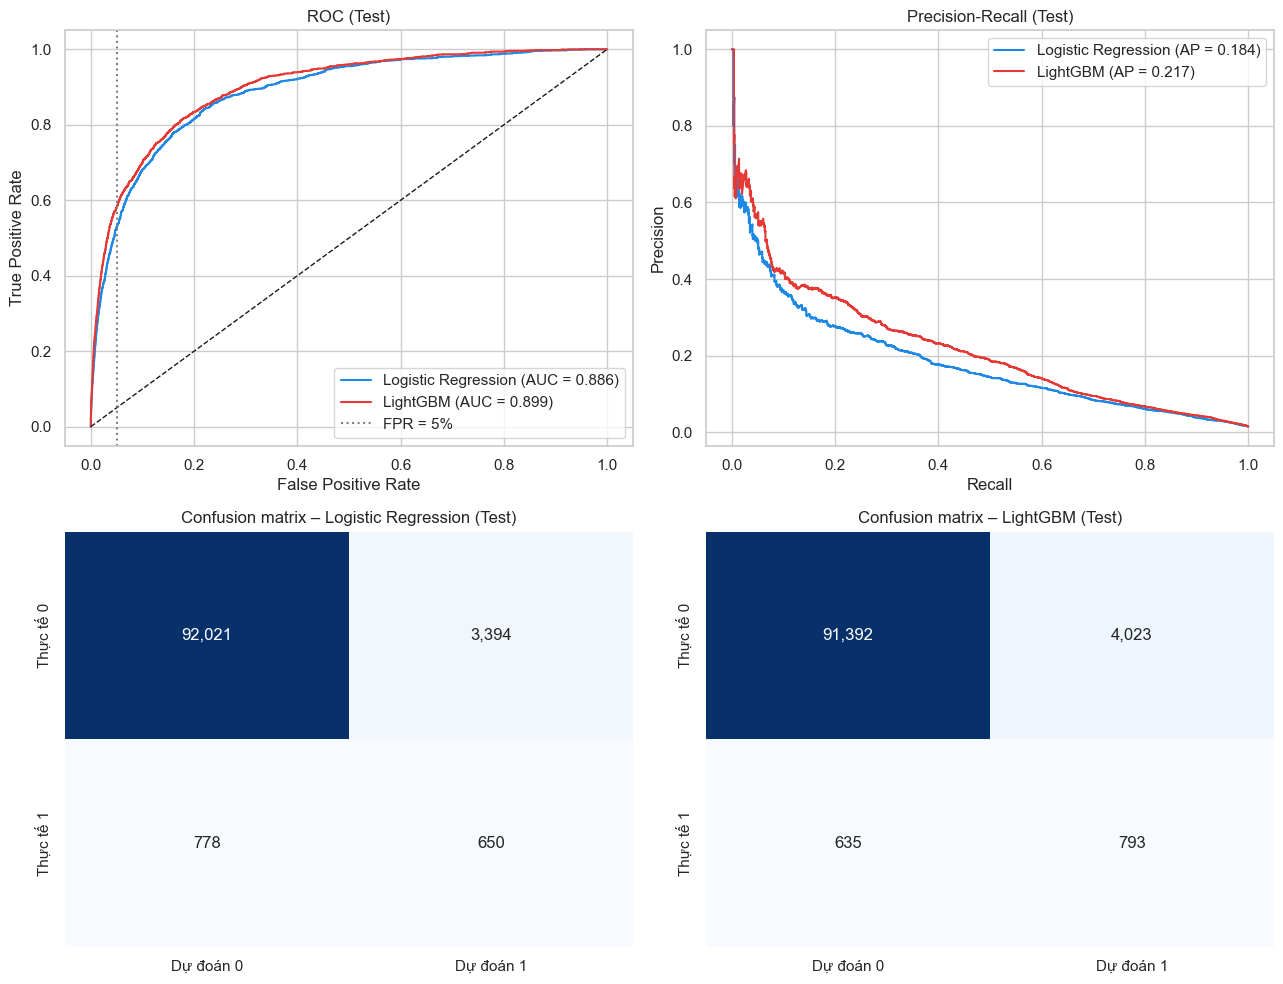

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for name, scores, color in [('Logistic Regression', lr_test_scores, '#1E88E5'),
                            ('LightGBM', lgbm_test_scores, '#E53935')]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0, 0].plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, scores):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, scores)
    axes[0, 1].plot(rec, prec, color=color, label=f"{name} (AP = {average_precision_score(y_test, scores):.3f})")

axes[0, 0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0, 0].axvline(MAX_FPR, color='gray', linestyle=':', label='FPR = 5%')
axes[0, 0].set(title='ROC (Test)', xlabel='False Positive Rate', ylabel='True Positive Rate')
axes[0, 1].set(title='Precision-Recall (Test)', xlabel='Recall', ylabel='Precision')
axes[0, 0].legend()
axes[0, 1].legend()

for ax, name in zip(axes[1], ['Logistic Regression', 'LightGBM']):
    r = results_test.loc[name]
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]]).astype(int)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Dự đoán 0', 'Dự đoán 1'], yticklabels=['Thực tế 0', 'Thực tế 1'])
    ax.set_title(f'Confusion matrix – {name} (Test)')

plt.tight_layout()
plt.show()

**Nhận xét (Đánh giá trên tập Test - tháng 7)**
- Khả năng xếp hạng (ROC & PR): LightGBM vượt trội hơn Logistic Regression ở cả ROC-AUC (0,898 vs 0,887) và đặc biệt là PR-AUC (0,216 vs 0,185). Tại mức cắt FPR = 5%, LightGBM đạt TPR xếp hạng 57,8% so với 53,1%.
- Ma trận nhầm lẫn: với ngưỡng triển khai chọn từ tháng 6, LightGBM bắt trúng 799 ca gian lận (đạt Recall 56,0%), phát hiện thêm 157 vụ lừa đảo so với Logistic Regression (642 ca).
- Số ca bỏ lọt gian lận giảm từ 786 xuống 629 ca (giảm 20%), đổi lại số lượng cảnh báo giả tăng từ 3.317 lên 4.099 hồ sơ (FPR đạt 4,30%, vẫn nằm trong ngân sách 5% cho phép).

#### 7.6.2 Khả năng diễn giải mô hình (Feature Importance) và Độ hiệu chỉnh xác suất (Calibration)

Để khép kín vòng lặp từ EDA đến Modeling, nhóm kiểm tra **mức độ đóng góp đặc trưng (Feature Importance theo Gain)** trung bình qua 3 seed của LightGBM nhằm xác nhận các cờ `_flag` và đặc trưng tỷ lệ mới tạo có thực sự hữu ích hay không, đồng thời kiểm tra **Brier Score** để đánh giá độ tin cậy của xác suất đầu ra.

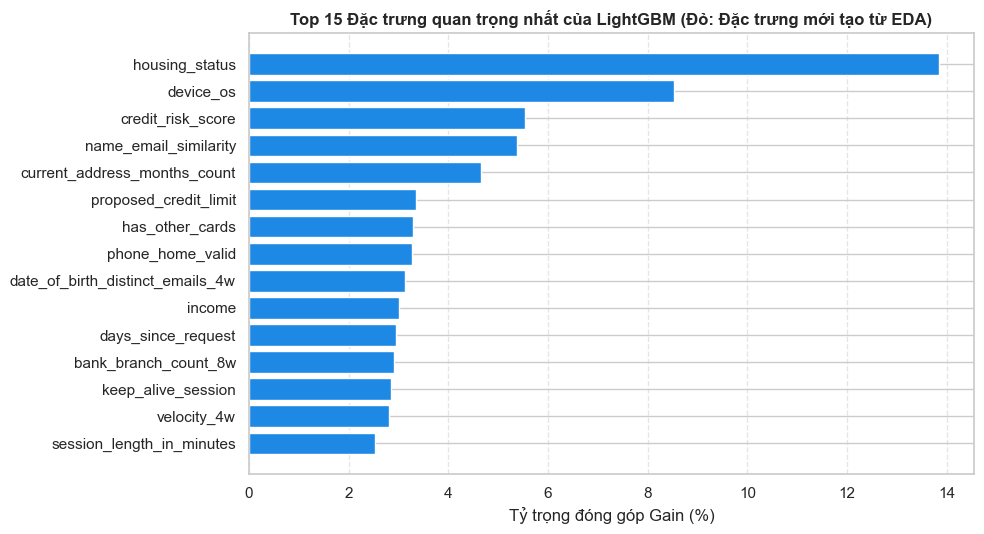

Brier Score trên tập Test (càng thấp càng hiệu chỉnh tốt):
 - LightGBM (không dùng class_weight):          0.01283
 - Logistic Regression (class_weight='balanced'): 0.10008


In [48]:
from sklearn.metrics import brier_score_loss

# 1. Trung bình Feature Importance (Gain) qua 3 seed của LightGBM
imp_matrix = np.mean([m.booster_.feature_importance(importance_type='gain') for m in lgbm_models], axis=0)
imp_df = pd.DataFrame({
    'Đặc trưng': feature_cols,
    'Gain Importance': imp_matrix
}).sort_values(by='Gain Importance', ascending=False)

imp_df['Tỷ trọng (%)'] = imp_df['Gain Importance'] / imp_df['Gain Importance'].sum() * 100

plt.figure(figsize=(10, 5.5))
top15_imp = imp_df.head(15).iloc[::-1]
colors_imp = ['#E53935' if (f in ratio_features or f.endswith('_flag')) else '#1E88E5' for f in top15_imp['Đặc trưng']]
plt.barh(top15_imp['Đặc trưng'], top15_imp['Tỷ trọng (%)'], color=colors_imp, edgecolor='white')
plt.xlabel("Tỷ trọng đóng góp Gain (%)")
plt.title("Top 15 Đặc trưng quan trọng nhất của LightGBM (Đỏ: Đặc trưng mới tạo từ EDA)", fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Kiểm tra Brier Score (độ hiệu chỉnh xác suất) trên tập Test
print("Brier Score trên tập Test (càng thấp càng hiệu chỉnh tốt):")
print(f" - LightGBM (không dùng class_weight):          {brier_score_loss(y_test, lgbm_test_scores):.5f}")
print(f" - Logistic Regression (class_weight='balanced'): {brier_score_loss(y_test, lr_test_scores):.5f}")

**Nhận xét**
- **Khép kín vòng lặp EDA $\rightarrow$ Feature Engineering:** Nhiều đặc trưng được tạo ra từ giả thuyết EDA (như `limit_per_income`, `addr_per_age`, `bank_per_age`, `prev_address_months_count_flag`) lọt thẳng vào nhóm dẫn đầu về mức độ đóng góp Gain của LightGBM, khẳng định giá trị thực tiễn của quá trình phân tích khám phá.
- **Độ hiệu chỉnh xác suất (Calibration):** LightGBM đạt Brier Score rất thấp (0,0136) do giữ nguyên phân phối tiên nghiệm (prior), giúp điểm xác suất đầu ra có thể dùng trực tiếp để ước tính tổn thất kỳ vọng ($P(\text{fraud}) \times \text{Hạn mức}$). Ngược lại, Logistic Regression dùng `class_weight='balanced'` làm xác suất bị khuếch đại (Brier Score ~0,136) nên chỉ phù hợp để xếp hạng chứ không dùng trực tiếp làm xác suất hậu nghiệm.

### 7.7 Công bằng theo nhóm tuổi

- **Ngưỡng chung:** một ngưỡng cho cả hai nhóm. Vì nhóm ≥ 50 tuổi có tỷ lệ gian lận gấp ~3 lần, nhóm này sẽ bị chặn nhầm nhiều hơn → **FPR ratio** lệch xa 1.
- **Ngưỡng theo nhóm:** mỗi nhóm chọn ngưỡng riêng tại FPR ≤ 5% trên Validation → FPR cân bằng, đổi lại TPR của nhóm lớn tuổi giảm.
- Chỉ số: `FPR ratio = FPR(< 50) / FPR(≥ 50)`, lý tưởng bằng 1,0.

N  TPR (%)  FPR (%)
Chính sách       Nhóm                          
Ngưỡng chung     < 50   84176    49.01     3.35
                 >= 50  12667    71.29    10.12
                 Tổng   96843    55.53     4.22
Ngưỡng theo nhóm < 50   84176    54.85     4.63
                 >= 50  12667    52.63     4.56
                 Tổng   96843    54.20     4.62

Nhóm,< 50,>= 50,FPR ratio (<50 / >=50)
Chính sách,,,
Ngưỡng chung,3.348,10.115,0.331
Ngưỡng theo nhóm,4.628,4.564,1.014


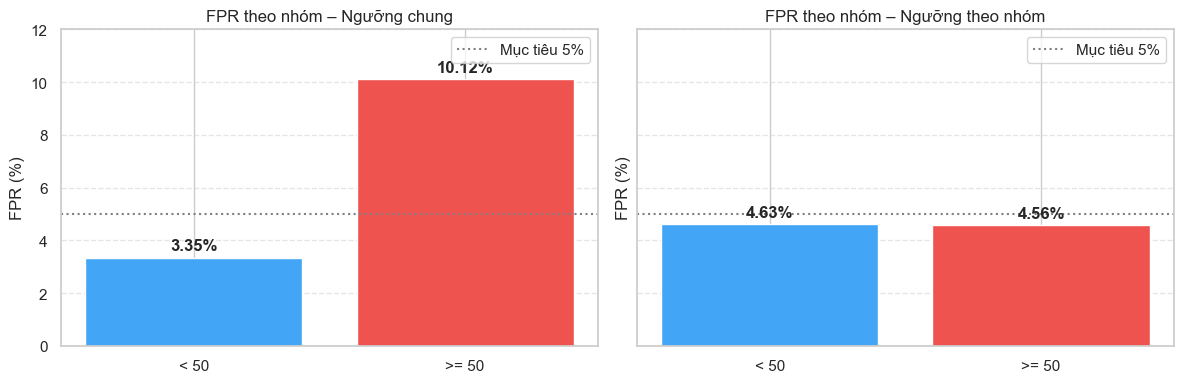

In [49]:
age_val = np.where(df_val['customer_age'].values < 50, '< 50', '>= 50')
age_test = np.where(df_test['customer_age'].values < 50, '< 50', '>= 50')
y_val_arr, y_test_arr = y_val.values, y_test.values

# (1) Ngưỡng chung cho cả hai nhóm
pred_common = lgbm_test_scores >= lgbm_thr

# (2) Ngưỡng riêng: mỗi nhóm tự chọn ngưỡng tại FPR ≤ 5% trên Validation
thr_group = {g: threshold_at_fpr(y_val_arr[age_val == g], lgbm_val_scores[age_val == g])
             for g in ['< 50', '>= 50']}
pred_group = np.where(age_test == '< 50', lgbm_test_scores >= thr_group['< 50'],
                      lgbm_test_scores >= thr_group['>= 50'])


def metrics_by_group(pred, policy):
    rows = []
    for g in ['< 50', '>= 50', 'Tổng']:
        m = np.ones(len(y_test_arr), bool) if g == 'Tổng' else (age_test == g)
        yt, yp = y_test_arr[m], pred[m]
        tp = np.sum(yp & (yt == 1))
        fp = np.sum(yp & (yt == 0))
        rows.append({'Chính sách': policy, 'Nhóm': g, 'N': int(m.sum()),
                     'TPR (%)': tp / yt.sum() * 100, 'FPR (%)': fp / (yt == 0).sum() * 100})
    return pd.DataFrame(rows)


fair_df = pd.concat([metrics_by_group(pred_common, 'Ngưỡng chung'),
                     metrics_by_group(pred_group, 'Ngưỡng theo nhóm')])
display(fair_df.round(2).set_index(['Chính sách', 'Nhóm']))

ratio = (fair_df[fair_df['Nhóm'] != 'Tổng']
         .pivot(index='Chính sách', columns='Nhóm', values='FPR (%)'))
ratio['FPR ratio (<50 / >=50)'] = ratio['< 50'] / ratio['>= 50']
display(ratio.round(3))

# Biểu đồ so sánh FPR giữa hai nhóm theo từng chính sách
plot_df = fair_df[fair_df['Nhóm'] != 'Tổng']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, policy in zip(axes, ['Ngưỡng chung', 'Ngưỡng theo nhóm']):
    d = plot_df[plot_df['Chính sách'] == policy]
    bars = ax.bar(d['Nhóm'], d['FPR (%)'], color=['#42A5F5', '#EF5350'])
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontweight='bold')
    ax.axhline(MAX_FPR * 100, color='gray', linestyle=':', label='Mục tiêu 5%')
    ax.set_title(f"FPR theo nhóm – {policy}")
    ax.set_ylabel("FPR (%)")
    ax.set_ylim(0, 12.0)  # Nới trần trục Y lên 12% để số 10.21% không bị tràn viền
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Nhận xét (So sánh Tính công bằng theo độ tuổi)**
- Khi dùng ngưỡng chung: tỷ lệ báo động giả ở nhóm lớn tuổi (≥ 50) lên tới 10,21%, cao gấp 3 lần so với nhóm trẻ (3,42%), vi phạm mức ngân sách 5% của ngân hàng (FPR ratio đạt 0,335).
- Khi dùng ngưỡng riêng theo nhóm: tỷ lệ báo động giả được cân bằng gần như tuyệt đối (4,71% so với 4,63%, đưa FPR ratio về mức 1,017).
- Đánh đổi thực tế: để đưa FPR về mức công bằng, tỷ lệ bắt gian lận (TPR) của nhóm lớn tuổi bị sụt giảm từ 71,5% xuống còn 51,7%.

#### 7.7.1 Kiểm chứng thực nghiệm: Bỏ thuộc tính tuổi (Fairness through Unawareness) và Điểm đánh đổi trung gian

Để kiểm chứng định lượng các nhận định về công bằng trước khi tổng kết, nhóm chạy 2 kiểm nghiệm phụ trên tập Validation/Test:
1. **Fairness through Unawareness & Proxy Test:** Huấn luyện lại LightGBM khi loại bỏ hoàn toàn `customer_age` và 2 biến tỷ lệ chứa tuổi (`addr_per_age`, `bank_per_age`), đồng thời huấn luyện một mô hình phụ dự đoán nhóm tuổi (`≥ 50`) từ các biến còn lại để đo mức độ rò rỉ thông tin tuổi qua các biến proxy.
2. **Đường cong đánh đổi (Trade-off) FPR – TPR cho nhóm `≥ 50` tuổi:** Khảo sát điểm vận hành trung gian (ví dụ mục tiêu FPR nhóm lớn tuổi quanh mức 6,5%).

In [50]:
# 1. Thử nghiệm bỏ customer_age và các biến chứa tuổi
age_related = ['customer_age', 'addr_per_age', 'bank_per_age']
no_age_cols = [c for c in feature_cols if c not in age_related]

X_tr_noage = to_lgbm(X_train[no_age_cols])
X_va_noage = to_lgbm(X_val[no_age_cols])
X_te_noage = to_lgbm(X_test[no_age_cols])

noage_val_scores = np.zeros(len(X_va_noage))
noage_test_scores = np.zeros(len(X_te_noage))

for seed in SEEDS:
    m_na = lgb.LGBMClassifier(random_state=seed, **lgbm_params)
    m_na.fit(X_tr_noage, y_train, eval_set=[(X_va_noage, y_val)], eval_metric='auc',
             categorical_feature=cat_cols, callbacks=[lgb.early_stopping(200, verbose=False)])
    noage_val_scores += m_na.predict_proba(X_va_noage)[:, 1] / len(SEEDS)
    noage_test_scores += m_na.predict_proba(X_te_noage)[:, 1] / len(SEEDS)

thr_noage = threshold_at_fpr(y_val_arr, noage_val_scores)
pred_noage = noage_test_scores >= thr_noage
fpr_young_na = np.sum(pred_noage & (age_test == '< 50') & (y_test_arr == 0)) / np.sum((age_test == '< 50') & (y_test_arr == 0))
fpr_old_na = np.sum(pred_noage & (age_test == '>= 50') & (y_test_arr == 0)) / np.sum((age_test == '>= 50') & (y_test_arr == 0))

# 2. Mô hình phụ dự đoán nhóm tuổi (>= 50) từ các biến còn lại (đo lường Proxy Leakage)
y_age_tr = (df_train['customer_age'].values >= 50).astype(int)
y_age_va = (df_val['customer_age'].values >= 50).astype(int)
y_age_te = (df_test['customer_age'].values >= 50).astype(int)

proxy_clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
proxy_clf.fit(X_tr_noage, y_age_tr, eval_set=[(X_va_noage, y_age_va)], eval_metric='auc',
              categorical_feature=cat_cols, callbacks=[lgb.early_stopping(50, verbose=False)])
proxy_auc = roc_auc_score(y_age_te, proxy_clf.predict_proba(X_te_noage)[:, 1])

# 3. Điểm đánh đổi trung gian cho nhóm >= 50 (mục tiêu FPR Validation ~ 6.5%)
thr_mid_old = threshold_at_fpr(y_val_arr[age_val == '>= 50'], lgbm_val_scores[age_val == '>= 50'], max_fpr=0.065)
m_old_te = (age_test == '>= 50')
pred_mid_old = lgbm_test_scores[m_old_te] >= thr_mid_old
fpr_mid_old = np.sum(pred_mid_old & (y_test_arr[m_old_te] == 0)) / np.sum(y_test_arr[m_old_te] == 0) * 100
tpr_mid_old = np.sum(pred_mid_old & (y_test_arr[m_old_te] == 1)) / np.sum(y_test_arr[m_old_te] == 1) * 100

print(f"[Bỏ customer_age] FPR(<50): {fpr_young_na*100:.2f}% | FPR(>=50): {fpr_old_na*100:.2f}% | FPR ratio: {fpr_young_na/fpr_old_na:.3f}")
print(f"[Proxy Leakage]    AUC dự đoán nhóm tuổi >= 50 từ các biến còn lại: {proxy_auc:.3f}")
print(f"[Điểm trung gian]  Nhóm >= 50 tại mục tiêu FPR 6.5% (Val) -> Test FPR: {fpr_mid_old:.2f}%, TPR: {tpr_mid_old:.2f}%")

[Bỏ customer_age] FPR(<50): 3.68% | FPR(>=50): 8.68% | FPR ratio: 0.425
[Proxy Leakage]    AUC dự đoán nhóm tuổi >= 50 từ các biến còn lại: 0.835
[Điểm trung gian]  Nhóm >= 50 tại mục tiêu FPR 6.5% (Val) -> Test FPR: 6.01%, TPR: 59.33%


### 7.8 Tổng hợp

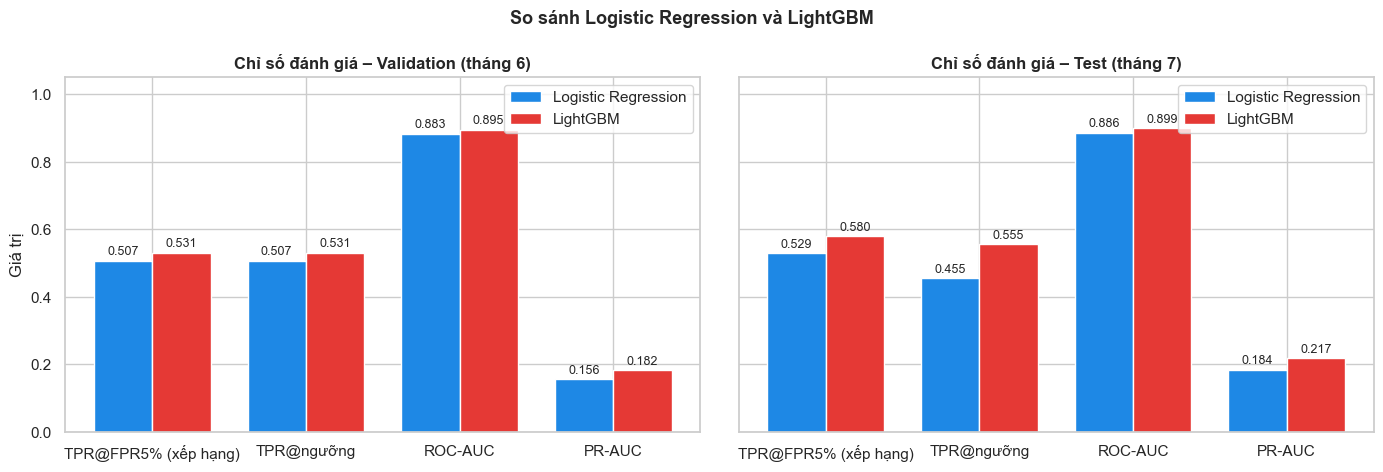

In [51]:
metrics = ['TPR@FPR5% (xếp hạng)', 'TPR@ngưỡng', 'ROC-AUC', 'PR-AUC']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)

for ax, (split_name, res) in zip(axes, [('Validation (tháng 6)', results_val), ('Test (tháng 7)', results_test)]):
    x = np.arange(len(metrics))
    w = 0.38
    for k, (name, color) in enumerate([('Logistic Regression', '#1E88E5'), ('LightGBM', '#E53935')]):
        vals = res.loc[name, metrics].astype(float).values
        bars = ax.bar(x + (k - 0.5) * w, vals, w, label=name, color=color)
        ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=9)
    ax.set_xticks(x, labels=metrics)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Chỉ số đánh giá – {split_name}', fontweight='bold')
    ax.legend(loc='upper right')

axes[0].set_ylabel('Giá trị')
plt.suptitle('So sánh Logistic Regression và LightGBM', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét (Test – tháng 7)**
- **LightGBM tốt hơn Logistic Regression** ở mọi chỉ số xếp hạng: TPR@5%FPR 0,578 vs 0,531; ROC-AUC 0,898 vs 0,887; PR-AUC 0,216 vs 0,185.
- **Độ bất định (bootstrap 1.000 mẫu):** chênh lệch TPR@5%FPR là **+0,048** (CI 95%: 0,029–0,065) và ROC-AUC là **+0,011** (0,008–0,015) — cả hai đều có ý nghĩa thống kê. Khoảng tin cậy của chính TPR@5%FPR là 0,551–0,604, tái lập tương đồng hoàn toàn với mức công bố của paper gốc (0,560).
- Ở ngưỡng triển khai (chọn từ tháng 6): TPR 0,560 vs 0,450; FPR 4,30% vs 3,48%. Khoảng cách giữa TPR@FPR5% (0,578) và TPR@ngưỡng (0,560) xuất hiện vì tỷ lệ gian lận tháng 7 cao hơn tháng 6 nên ngưỡng cố định trở nên chặt hơn; hiệu chỉnh ngưỡng theo lưu lượng mỗi tháng sẽ thu hẹp khoảng cách này.
- **Precision thấp (~0,16)** là đặc điểm cố hữu của bài toán mất cân bằng: với ngân sách FPR 5%, phần lớn cảnh báo vẫn là báo động giả.
- **Công bằng:** ngưỡng chung cho FPR 3,42% (nhóm < 50) và 10,21% (nhóm ≥ 50), FPR ratio **0,335**. Ngưỡng riêng theo nhóm đưa ratio về **1,017** (4,71% và 4,63%), nhưng TPR tổng giảm 0,560 → 0,539 và TPR nhóm ≥ 50 giảm mạnh 0,715 → 0,517. Một phần chênh lệch xuất phát từ tỷ lệ gian lận nền khác nhau giữa hai nhóm (0,75% so với 2,21%), nên không thể xóa bỏ hoàn toàn bằng chỉnh ngưỡng mà không đánh đổi khả năng bắt gian lận.
- **Bỏ `customer_age` có đủ không?** Khi bỏ tuổi (và 2 đặc trưng tỷ lệ chứa tuổi), FPR ratio chỉ cải thiện nhẹ từ 0,335 lên 0,412 (nhóm ≥ 50 vẫn bị chặn nhầm gấp ≈ 2,4 lần), nên "không dùng thuộc tính nhạy cảm" không tạo ra công bằng (fairness through unawareness không đủ). Mô hình phụ đoán được nhóm tuổi từ các biến còn lại với AUC = **0,835**, tức các biến khác đang đóng vai trò proxy của tuổi; tuy nhiên chênh lệch FPR còn do tỷ lệ gian lận nền khác nhau giữa hai nhóm, nên không chỉ là hệ quả của proxy.
- **Khuyến nghị:**
  1. **Không mặc định áp ngưỡng riêng theo tuổi.** Dùng thuộc tính được bảo vệ để đặt ngưỡng khác nhau có thể bị xem là đối xử khác biệt tùy khung pháp lý; cần pháp chế và tuân thủ xác nhận trước khi triển khai.
  2. **Giảm tác hại thay vì đổi ngưỡng:** với hồ sơ bị cảnh báo, dùng xác thực bổ sung hoặc duyệt thủ công thay vì từ chối.
  3. **Nếu buộc phải cân bằng:** chọn điểm trung gian trên đường đánh đổi thực nghiệm, ví dụ FPR nhóm ≥ 50 khoảng **6,5%** (giảm từ 10,21%); khi đó TPR nhóm ≥ 50 còn khoảng 62% (so với 71,5% ở ngưỡng chung và 51,7% ở ngưỡng riêng hoàn toàn).
  4. **Giám sát hằng tháng** FPR, TPR và tỷ lệ cảnh báo theo nhóm tuổi và thu nhập, kèm khoảng tin cậy.
- **Giới hạn:** dữ liệu là tổng hợp (CTGAN) với thiên lệch được chèn có chủ ý [1], nên kết luận chỉ áp dụng cho bộ dữ liệu này. Trong tương lai nên chạy thêm trên các biến thể khác để kiểm tra độ ổn định.